In [1]:
%pip install -q biopython scikit-learn joblib


In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from Bio.PDB import PDBParser, PDBList
from scipy.spatial.distance import pdist, squareform

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PDB_ID = "4OBE"
CHAIN_ID = "A"
PDB_DIR = Path("pdb_files")
OUTPUT_DIR = Path("kras_operator_space_v5_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Main manuscript RIN configuration.
DISTANCE_CUTOFF = 7.0
RIN_WEIGHT_MODE = "distance"  # "distance" for the main model; "binary" is used only in sensitivity analysis.

# Amino-acid-aware numerical perturbation model.
ALPHA_MIN = 0.20
ALPHA_MAX = 0.85
SECOND_SHELL_FACTOR = 0.15

print("Configuration")
print("-------------")
print(f"PDB ID: {PDB_ID}")
print(f"Chain: {CHAIN_ID}")
print(f"Distance cutoff: {DISTANCE_CUTOFF} Å")
print(f"RIN weight mode: {RIN_WEIGHT_MODE}")
print(f"Mutation alpha range: [{ALPHA_MIN}, {ALPHA_MAX}]")
print(f"Second-shell factor: {SECOND_SHELL_FACTOR}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")


Configuration
-------------
PDB ID: 4OBE
Chain: A
Distance cutoff: 7.0 Å
RIN weight mode: distance
Mutation alpha range: [0.2, 0.85]
Second-shell factor: 0.15
Output directory: /content/kras_operator_space_v5_outputs


## 1. Utility functions

In [3]:
def download_pdb(pdb_id: str, pdb_dir: Path = PDB_DIR) -> Path:
    """Return a local PDB file, downloading it only when it is not already cached."""
    pdb_dir.mkdir(parents=True, exist_ok=True)
    cached = pdb_dir / f"pdb{pdb_id.lower()}.ent"
    if cached.exists():
        return cached

    pdbl = PDBList()
    retrieved = pdbl.retrieve_pdb_file(pdb_id, pdir=str(pdb_dir), file_format="pdb")
    retrieved_path = Path(retrieved)

    if retrieved_path.exists():
        return retrieved_path
    if cached.exists():
        return cached

    raise FileNotFoundError(f"Could not retrieve PDB structure {pdb_id}.")


def build_rin_from_pdb(
    pdb_id: str,
    chain_id: str = "A",
    distance_cutoff: float = 7.0,
    edge_weight_mode: str = "distance",
    pdb_dir: Path = PDB_DIR,
) -> tuple[nx.Graph, np.ndarray, list[int], Path]:
    """Build a C-alpha RIN from a PDB structure.

    Nodes correspond to standard residues with a C-alpha atom.
    An edge is added when the C-alpha distance is <= distance_cutoff.

    edge_weight_mode:
      - "distance": edge weight equals the C-alpha Euclidean distance (main manuscript model).
      - "binary": every retained contact has unit weight (sensitivity analysis).

    The binary mode is included only as an alternative RIN construction for robustness checks.
    """
    if edge_weight_mode not in {"distance", "binary"}:
        raise ValueError("edge_weight_mode must be either 'distance' or 'binary'")

    pdb_file = download_pdb(pdb_id, pdb_dir)

    parser = PDBParser(QUIET=True)
    structure = parser.get_structure(pdb_id, str(pdb_file))

    model = structure[0]
    if chain_id not in model:
        available = [chain.id for chain in model]
        raise ValueError(f"Chain {chain_id!r} not found. Available chains: {available}")

    chain = model[chain_id]

    residues = []
    coords = []
    residue_numbers = []

    for residue in chain:
        if "CA" not in residue:
            continue

        hetflag, resseq, icode = residue.id
        if hetflag.strip():
            continue

        residues.append(residue)
        residue_numbers.append(int(resseq))
        coords.append(residue["CA"].coord)

    coords = np.asarray(coords, dtype=float)
    distances = squareform(pdist(coords))

    G = nx.Graph()

    for idx, resnum in enumerate(residue_numbers):
        G.add_node(
            idx,
            residue_number=resnum,
            residue_name=residues[idx].resname,
            coord=coords[idx],
        )

    n = len(residue_numbers)
    for i in range(n):
        for j in range(i + 1, n):
            distance = float(distances[i, j])
            if distance <= distance_cutoff:
                weight = distance if edge_weight_mode == "distance" else 1.0
                G.add_edge(i, j, weight=float(weight), ca_distance=distance)

    return G, coords, residue_numbers, pdb_file


def weighted_adjacency(G: nx.Graph) -> np.ndarray:
    """Return the weighted adjacency matrix of a graph."""
    return nx.to_numpy_array(G, weight="weight", dtype=float)


def weighted_laplacian(G: nx.Graph) -> np.ndarray:
    """Return the weighted combinatorial graph Laplacian L = D - A."""
    A = weighted_adjacency(G)
    degrees = A.sum(axis=1)
    return np.diag(degrees) - A


# ---------------------------------------------------------------------
# Amino-acid-aware mutation perturbation model
# ---------------------------------------------------------------------

AA3_TO_1 = {
    "ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C",
    "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H", "ILE": "I",
    "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P",
    "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V",
}

# Physicochemical descriptors used to differentiate substitutions at the same site.
# Hydropathy follows the Kyte--Doolittle scale; volumes are approximate residue volumes.
AA_HYDROPATHY = {
    "A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5,
    "Q": -3.5, "E": -3.5, "G": -0.4, "H": -3.2, "I": 4.5,
    "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8, "P": -1.6,
    "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2,
}

AA_VOLUME = {
    "A": 88.6, "R": 173.4, "N": 114.1, "D": 111.1, "C": 108.5,
    "Q": 143.8, "E": 138.4, "G": 60.1, "H": 153.2, "I": 166.7,
    "L": 166.7, "K": 168.6, "M": 162.9, "F": 189.9, "P": 112.7,
    "S": 89.0, "T": 116.1, "W": 227.8, "Y": 193.6, "V": 140.0,
}

AA_CHARGE = {
    "D": -1.0, "E": -1.0, "K": 1.0, "R": 1.0, "H": 0.1,
}


def aa_charge(aa: str) -> float:
    return AA_CHARGE.get(aa, 0.0)


def parse_mutation_name(name: str) -> dict:
    """Parse a mutation label such as G12D into WT residue, position and mutant residue."""
    import re
    match = re.match(r"^([A-Z])(\d+)([A-Z])$", name)
    if match is None:
        raise ValueError(f"Mutation name {name!r} does not follow the pattern G12D")
    wt, pos, mut = match.groups()
    return {"wt_aa": wt, "resnum": int(pos), "mut_aa": mut}


def amino_acid_severity(wt_aa: str, mut_aa: str) -> float:
    """Return the normalized physicochemical dissimilarity used in the manuscript."""
    if wt_aa not in AA_HYDROPATHY or mut_aa not in AA_HYDROPATHY:
        raise ValueError(f"Unknown amino acid substitution {wt_aa}->{mut_aa}")

    dh = abs(AA_HYDROPATHY[wt_aa] - AA_HYDROPATHY[mut_aa]) / 9.0
    dv = abs(AA_VOLUME[wt_aa] - AA_VOLUME[mut_aa]) / 170.0
    dc = abs(aa_charge(wt_aa) - aa_charge(mut_aa)) / 2.0

    return float(np.sqrt((dh ** 2 + dv ** 2 + dc ** 2) / 3.0))


def alpha_from_severity(
    severity: float,
    alpha_min: float = ALPHA_MIN,
    alpha_max: float = ALPHA_MAX,
) -> float:
    """Map physicochemical dissimilarity to the local numerical reweighting factor alpha."""
    alpha = alpha_max - severity * (alpha_max - alpha_min)
    return float(np.clip(alpha, alpha_min, alpha_max))


def beta_from_alpha(
    alpha: float,
    second_shell_factor: float = SECOND_SHELL_FACTOR,
) -> float:
    """Return the weaker second-neighborhood reweighting factor beta."""
    beta = 1.0 - second_shell_factor * (1.0 - alpha)
    return float(np.clip(beta, 0.0, 1.0))


def apply_mutation_local_reweighting(
    G: nx.Graph,
    nodes_to_perturb: list[int],
    alpha: float,
    second_shell_factor: float = SECOND_SHELL_FACTOR,
) -> nx.Graph:
    """Apply the mutation-dependent local numerical reweighting used in the manuscript.

    Existing edges incident to the mutated residue are multiplied by alpha.
    Existing edges connecting two first neighbors are multiplied by beta.

    No vertices or edges are added or removed. This is a numerical perturbation
    model. In the main distance-weighted RIN, the reweighted coefficients are
    not interpreted as physical post-mutation inter-residue distances.
    """
    if not (0 < alpha <= 1):
        raise ValueError("alpha must satisfy 0 < alpha <= 1")

    H = G.copy()
    beta = beta_from_alpha(alpha, second_shell_factor)

    for v in nodes_to_perturb:
        if v not in H:
            continue

        neighbors = list(H.neighbors(v))

        for u in neighbors:
            w = H[v][u].get("weight", 1.0)
            H[v][u]["weight"] = float(w) * alpha

        for i, u in enumerate(neighbors):
            for w_node in neighbors[i + 1:]:
                if H.has_edge(u, w_node):
                    w = H[u][w_node].get("weight", 1.0)
                    H[u][w_node]["weight"] = float(w) * beta

    return H


def hilbert_schmidt_norm(A: np.ndarray) -> float:
    """Hilbert--Schmidt/Frobenius norm for real matrices."""
    return float(np.sqrt(np.trace(A.T @ A)))


def hilbert_schmidt_inner(A: np.ndarray, B: np.ndarray) -> float:
    """Hilbert--Schmidt inner product for real matrices."""
    return float(np.trace(A.T @ B))


def algebraic_connectivity(L: np.ndarray) -> float:
    """Second-smallest eigenvalue of the Laplacian."""
    evals = np.sort(np.linalg.eigvalsh(L))
    return float(evals[1]) if len(evals) > 1 else np.nan


def matrix_rank(A: np.ndarray, tol: float = 1e-10) -> int:
    """Numerical matrix rank."""
    return int(np.linalg.matrix_rank(A, tol=tol))


## 2. Build the wild-type KRAS RIN

In [4]:
G_wt, coords, residue_numbers, pdb_file = build_rin_from_pdb(
    pdb_id=PDB_ID,
    chain_id=CHAIN_ID,
    distance_cutoff=DISTANCE_CUTOFF,
    edge_weight_mode=RIN_WEIGHT_MODE,
    pdb_dir=PDB_DIR,
)

A_wt = weighted_adjacency(G_wt)
L_wt = weighted_laplacian(G_wt)
lambda2_wt = algebraic_connectivity(L_wt)

print("PDB file:", pdb_file)
print("Number of residues:", G_wt.number_of_nodes())
print("Number of interactions:", G_wt.number_of_edges())
print("RIN weight mode:", RIN_WEIGHT_MODE)
print("WT algebraic connectivity lambda_2:", lambda2_wt)
print("Adjacency shape:", A_wt.shape)
print("Laplacian shape:", L_wt.shape)


PDB file: pdb_files/pdb4obe.ent
Number of residues: 169
Number of interactions: 666
RIN weight mode: distance
WT algebraic connectivity lambda_2: 1.3533143538022037
Adjacency shape: (169, 169)
Laplacian shape: (169, 169)


In [5]:
residue_table = pd.DataFrame([
    {
        "node": node,
        "residue_number": data["residue_number"],
        "residue_name": data["residue_name"],
        "degree": G_wt.degree(node),
        "weighted_degree": sum(G_wt[node][nbr].get("weight", 1.0) for nbr in G_wt.neighbors(node)),
    }
    for node, data in G_wt.nodes(data=True)
])

residue_table.head(10)


,node,residue_number,residue_name,degree,weighted_degree
0,0,1,MET,5,27.352467
1,1,2,THR,6,32.109656
2,2,3,GLU,8,43.887577
3,3,4,TYR,8,44.342193
4,4,5,LYS,10,55.250089
5,5,6,LEU,12,67.100578
6,6,7,VAL,11,60.885688
7,7,8,VAL,10,54.669874
8,8,9,VAL,9,51.059023
9,9,10,GLY,7,37.307906


## 3. Define KRAS mutation sites

The panel contains recurrent KRAS substitutions at G12, G13, Q61, K117 and A146. Multiple substitutions at the same residue are intentionally retained. Their physicochemical dissimilarity scores generate mutation-specific reweighting factors, so substitutions at the same site can produce distinct perturbation operators even though they act on the same wild-type RIN topology.


In [6]:
# A compact panel of clinically recurrent KRAS mutations.
# Multiple substitutions at the same site are intentionally included to test whether
# the amino-acid-aware perturbation model distinguishes mutations beyond residue position.
mutation_labels = [
    "G12D", "G12V", "G12C", "G12A", "G12S", "G12R",
    "G13D", "G13C", "G13V",
    "Q61H", "Q61L", "Q61R",
    "K117N", "A146T",
]

resnum_to_node = {
    data["residue_number"]: node
    for node, data in G_wt.nodes(data=True)
}

mutation_specs = []
for label in mutation_labels:
    parsed = parse_mutation_name(label)
    resnum = parsed["resnum"]
    node = resnum_to_node.get(resnum, None)

    if node is None:
        print(f"WARNING: mutation {label} maps to missing residue number {resnum}")
        continue

    pdb_resname = G_wt.nodes[node]["residue_name"]
    pdb_wt = AA3_TO_1.get(pdb_resname, None)

    if pdb_wt is not None and pdb_wt != parsed["wt_aa"]:
        print(
            f"WARNING: mutation {label} expects WT {parsed['wt_aa']} "
            f"but PDB residue {resnum} is {pdb_resname} ({pdb_wt})"
        )

    severity = amino_acid_severity(parsed["wt_aa"], parsed["mut_aa"])
    alpha = alpha_from_severity(severity)
    beta = beta_from_alpha(alpha, SECOND_SHELL_FACTOR)

    mutation_specs.append({
        "name": label,
        "resnums": [resnum],
        "site": resnum,
        "wt_aa": parsed["wt_aa"],
        "mut_aa": parsed["mut_aa"],
        "pdb_wt_aa": pdb_wt,
        "aa_severity": severity,
        "alpha": alpha,
        "beta": beta,
    })

mutation_design_df = pd.DataFrame(mutation_specs)
mutation_design_df


,name,resnums,site,wt_aa,mut_aa,pdb_wt_aa,aa_severity,alpha,beta
0,G12D,[12],12,G,D,G,0.391000,0.595850,0.939378
1,G12V,[12],12,G,V,G,0.400888,0.589423,0.938413
2,G12C,[12],12,G,C,G,0.248250,0.688637,0.953296
3,G12A,[12],12,G,A,G,0.171132,0.738764,0.960815
4,G12S,[12],12,G,S,G,0.101448,0.784059,0.967609
5,G12R,[12],12,G,R,G,0.548244,0.493642,0.924046
6,G13D,[13],13,G,D,G,0.391000,0.595850,0.939378
7,G13C,[13],13,G,C,G,0.248250,0.688637,0.953296
8,G13V,[13],13,G,V,G,0.400888,0.589423,0.938413
9,Q61H,[61],61,Q,H,Q,0.047147,0.819354,0.972903


## 4. Construct mutation perturbation operators

In [7]:
rows = []
delta_laplacians = {}
mutated_laplacians = {}
mutated_graphs = {}

for mutation in mutation_specs:
    name = mutation["name"]
    resnums = mutation["resnums"]
    alpha_i = mutation["alpha"]

    nodes = [
        resnum_to_node[r]
        for r in resnums
        if r in resnum_to_node
    ]

    G_mut = apply_mutation_local_reweighting(
        G_wt,
        nodes,
        alpha=alpha_i,
        second_shell_factor=SECOND_SHELL_FACTOR,
    )
    L_mut = weighted_laplacian(G_mut)
    delta_L = L_mut - L_wt

    mutated_graphs[name] = G_mut
    mutated_laplacians[name] = L_mut
    delta_laplacians[name] = delta_L

    lambda2_mut = algebraic_connectivity(L_mut)

    rows.append(
        {
            "mutation": name,
            "site": mutation["site"],
            "wt_aa": mutation["wt_aa"],
            "mut_aa": mutation["mut_aa"],
            "aa_severity": mutation["aa_severity"],
            "alpha": alpha_i,
            "beta": beta_from_alpha(alpha_i, SECOND_SHELL_FACTOR),
            "residue_numbers": ",".join(map(str, resnums)),
            "nodes": ",".join(map(str, nodes)),
            "hs_norm": hilbert_schmidt_norm(delta_L),
            "rank_delta_L": matrix_rank(delta_L),
            "lambda2_wt": lambda2_wt,
            "lambda2_mut": lambda2_mut,
            "delta_lambda2": lambda2_mut - lambda2_wt,
            "distance_cutoff": DISTANCE_CUTOFF,
            "rin_weight_mode": RIN_WEIGHT_MODE,
            "second_shell_factor": SECOND_SHELL_FACTOR,
        }
    )

operator_space_df = pd.DataFrame(rows)
operator_space_df


,mutation,site,wt_aa,mut_aa,aa_severity,alpha,beta,residue_numbers,nodes,hs_norm,rank_delta_L,lambda2_wt,lambda2_mut,delta_lambda2,distance_cutoff,rin_weight_mode,second_shell_factor
0,G12D,12,G,D,0.391000,0.595850,0.939378,12,11,11.490845,4,1.353314,1.352965,-0.000350,7.0,distance,0.15
1,G12V,12,G,V,0.400888,0.589423,0.938413,12,11,11.673600,4,1.353314,1.352957,-0.000358,7.0,distance,0.15
2,G12C,12,G,C,0.248250,0.688637,0.953296,12,11,8.852710,4,1.353314,1.353066,-0.000248,7.0,distance,0.15
3,G12A,12,G,A,0.171132,0.738764,0.960815,12,11,7.427498,4,1.353314,1.353114,-0.000200,7.0,distance,0.15
4,G12S,12,G,S,0.101448,0.784059,0.967609,12,11,6.139679,4,1.353314,1.353154,-0.000160,7.0,distance,0.15
5,G12R,12,G,R,0.548244,0.493642,0.924046,12,11,14.396861,4,1.353314,1.352822,-0.000492,7.0,distance,0.15
6,G13D,13,G,D,0.391000,0.595850,0.939378,13,12,10.981945,4,1.353314,1.352094,-0.001220,7.0,distance,0.15
7,G13C,13,G,C,0.248250,0.688637,0.953296,13,12,8.460647,4,1.353314,1.352415,-0.000900,7.0,distance,0.15
8,G13V,13,G,V,0.400888,0.589423,0.938413,13,12,11.156607,4,1.353314,1.352071,-0.001243,7.0,distance,0.15
9,Q61H,61,Q,H,0.047147,0.819354,0.972903,61,60,5.290656,4,1.353314,1.352970,-0.000345,7.0,distance,0.15


## 5. Pairwise Hilbert--Schmidt geometry of the mutation operator space

In [8]:
mutation_names = [m["name"] for m in mutation_specs]
N_mut = len(mutation_names)

D_hs = np.zeros((N_mut, N_mut), dtype=float)
G_hs = np.zeros((N_mut, N_mut), dtype=float)

for i, name_i in enumerate(mutation_names):
    for j, name_j in enumerate(mutation_names):
        Delta_i = delta_laplacians[name_i]
        Delta_j = delta_laplacians[name_j]
        D_hs[i, j] = hilbert_schmidt_norm(Delta_i - Delta_j)
        G_hs[i, j] = hilbert_schmidt_inner(Delta_i, Delta_j)

D_hs_df = pd.DataFrame(D_hs, index=mutation_names, columns=mutation_names)
G_hs_df = pd.DataFrame(G_hs, index=mutation_names, columns=mutation_names)

print("Pairwise Hilbert--Schmidt distance matrix")
display(D_hs_df)
print("Hilbert--Schmidt Gram matrix")
display(G_hs_df)


Pairwise Hilbert--Schmidt distance matrix


,G12D,G12V,G12C,G12A,G12S,G12R,G13D,G13C,G13V,Q61H,Q61L,Q61R,K117N,A146T
G12D,0.000000,0.182755,2.638135,4.063347,5.351166,2.906015,11.560272,10.580201,11.645341,12.650319,17.675043,15.457528,24.872423,22.978285
G12V,0.182755,0.000000,2.820890,4.246102,5.533921,2.723260,11.661073,10.710552,11.744131,12.816551,17.794397,15.593864,24.957381,23.070219
G12C,2.638135,2.820890,0.000000,1.425212,2.713031,5.544150,10.358194,8.906198,10.473815,10.313172,16.085339,13.611250,23.769064,21.779176
G12A,4.063347,4.246102,1.425212,0.000000,1.287819,6.969363,9.942302,8.215161,10.074360,9.119143,15.347161,12.730411,23.275860,21.239816
G12S,5.351166,5.533921,2.713031,1.287819,0.000000,8.257181,9.732130,7.764783,9.877744,8.104734,14.766966,12.024613,22.897458,20.824450
G12R,2.906015,2.723260,5.544150,6.969363,8.257181,0.000000,13.370653,12.805649,13.426458,15.338208,19.688505,17.724707,26.341365,24.560774
G13D,11.560272,11.661073,10.358194,9.942302,9.732130,13.370653,0.000000,2.521299,0.174661,12.189921,17.348509,15.083062,24.641450,22.728070
G13C,10.580201,10.710552,8.906198,8.215161,7.764783,12.805649,2.521299,0.000000,2.695960,9.978657,15.872939,13.359573,23.625843,21.622779
G13V,11.645341,11.744131,10.473815,10.074360,9.877744,13.426458,0.174661,2.695960,0.000000,12.347506,17.459596,15.210704,24.719785,22.812977
Q61H,12.650319,12.816551,10.313172,9.119143,8.104734,15.338208,12.189921,9.978657,12.347506,0.000000,8.139445,5.048379,22.684553,20.590121


Hilbert--Schmidt Gram matrix


,G12D,G12V,G12C,G12A,G12S,G12R,G13D,G13C,G13V,Q61H,Q61L,Q61R,K117N,A146T
G12D,132.039525,134.139533,101.725125,85.348229,70.550103,165.432096,59.501383,45.840711,60.447717,0.000000,0.000000,0.000000,0.000000,0.000000
G12V,134.139533,136.272940,103.343001,86.705640,71.672160,168.063193,60.447717,46.569779,61.409101,0.000000,0.000000,0.000000,0.000000,0.000000
G12C,101.725125,103.343001,78.370481,65.753487,54.352801,127.451236,45.840711,35.316334,46.569779,0.000000,0.000000,0.000000,0.000000,0.000000
G12A,85.348229,86.705640,65.753487,55.167725,45.602454,106.932651,38.460739,29.630699,39.072434,0.000000,0.000000,0.000000,0.000000,0.000000
G12S,70.550103,71.672160,54.352801,45.602454,37.695660,88.392105,31.792213,24.493173,32.297849,0.000000,0.000000,0.000000,0.000000,0.000000
G12R,165.432096,168.063193,127.451236,106.932651,88.392105,207.269593,74.549182,57.433749,75.734842,0.000000,0.000000,0.000000,0.000000,0.000000
G13D,59.501383,60.447717,45.840711,38.460739,31.792213,74.549182,120.603126,92.914361,122.521245,0.000000,0.000000,0.000000,0.000000,0.000000
G13C,45.840711,46.569779,35.316334,29.630699,24.493173,57.433749,92.914361,71.582543,94.392107,0.000000,0.000000,0.000000,0.000000,0.000000
G13V,60.447717,61.409101,46.569779,39.072434,32.297849,75.734842,122.521245,94.392107,124.469871,0.000000,0.000000,0.000000,0.000000,0.000000
Q61H,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,27.991045,71.054054,54.700282,0.000000,0.000000


## 6. Save outputs for the next experiments

In [9]:
operator_space_df.to_csv(OUTPUT_DIR / "kras_mutation_operator_space_summary.csv", index=False)
mutation_design_df.to_csv(OUTPUT_DIR / "kras_mutation_design_amino_acid_aware.csv", index=False)
D_hs_df.to_csv(OUTPUT_DIR / "kras_mutation_operator_distance_matrix.csv")
G_hs_df.to_csv(OUTPUT_DIR / "kras_mutation_operator_gram_matrix.csv")
residue_table.to_csv(OUTPUT_DIR / "kras_rin_residue_table.csv", index=False)

np.save(OUTPUT_DIR / "L_wt.npy", L_wt)
np.save(OUTPUT_DIR / "A_wt.npy", A_wt)
np.save(OUTPUT_DIR / "D_hs.npy", D_hs)
np.save(OUTPUT_DIR / "G_hs.npy", G_hs)

for name, delta_L in delta_laplacians.items():
    np.save(OUTPUT_DIR / f"delta_L_{name}.npy", delta_L)

print("Saved outputs in:", OUTPUT_DIR.resolve())
print("Files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)


Saved outputs in: /content/kras_operator_space_v5_outputs
Files:
 - A_wt.npy
 - D_hs.npy
 - G_hs.npy
 - L_wt.npy
 - delta_L_A146T.npy
 - delta_L_G12A.npy
 - delta_L_G12C.npy
 - delta_L_G12D.npy
 - delta_L_G12R.npy
 - delta_L_G12S.npy
 - delta_L_G12V.npy
 - delta_L_G13C.npy
 - delta_L_G13D.npy
 - delta_L_G13V.npy
 - delta_L_K117N.npy
 - delta_L_Q61H.npy
 - delta_L_Q61L.npy
 - delta_L_Q61R.npy
 - experiment_10_correlation_summary.csv
 - experiment_10_correlation_summary_table.png
 - experiment_10_geometry_only_mds.png
 - experiment_10_mds_operator_vs_ising_reconstructed.png
 - experiment_10_mds_preservation_summary.csv
 - experiment_10_mst_operator_vs_ising_reconstructed.png
 - experiment_10_mst_summary.csv
 - experiment_10_mu_evolution_components_k_main.png
 - experiment_10_mu_evolution_k_main.csv
 - experiment_10_mu_selection_matrix_k_main.png
 - experiment_10_operator_distance_histogram.png
 - experiment_10_operator_energy_ranking.png
 - experiment_10_sankey_cluster_coverage.html
 - e

## 7. Basic figures

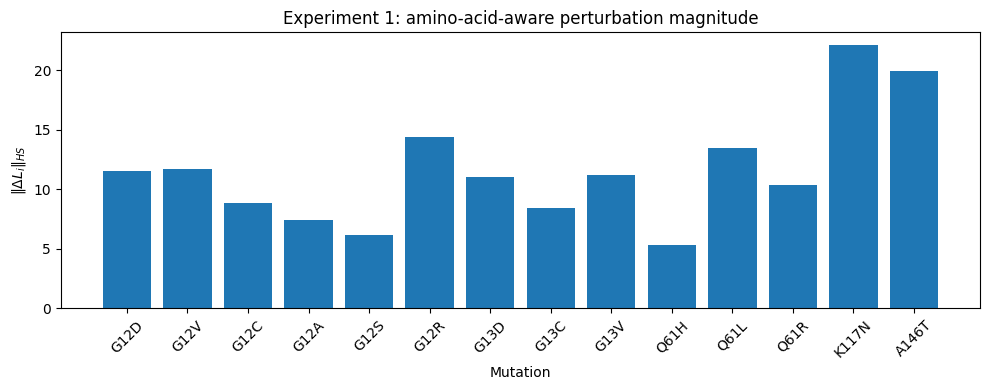

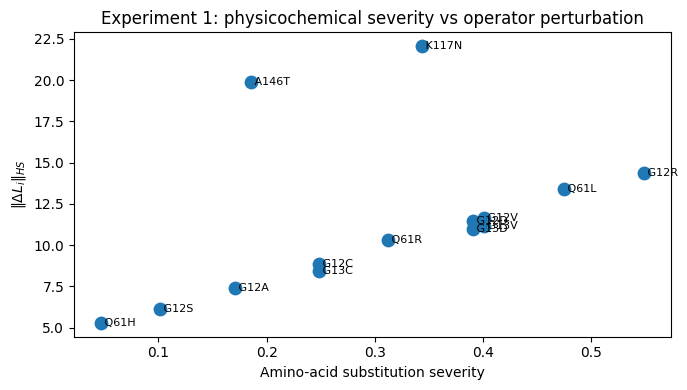

In [10]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(operator_space_df["mutation"], operator_space_df["hs_norm"])
ax1.set_ylabel(r"$\|\Delta L_i\|_{HS}$")
ax1.set_xlabel("Mutation")
ax1.set_title("Experiment 1: amino-acid-aware perturbation magnitude")
ax1.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "hs_norm_by_mutation_amino_acid_aware.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(operator_space_df["aa_severity"], operator_space_df["hs_norm"], s=80)
for _, row in operator_space_df.iterrows():
    plt.text(row["aa_severity"], row["hs_norm"], f" {row['mutation']}", va="center", fontsize=8)
plt.xlabel("Amino-acid substitution severity")
plt.ylabel(r"$\|\Delta L_i\|_{HS}$")
plt.title("Experiment 1: physicochemical severity vs operator perturbation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "severity_vs_hs_norm.png", dpi=300)
plt.show()


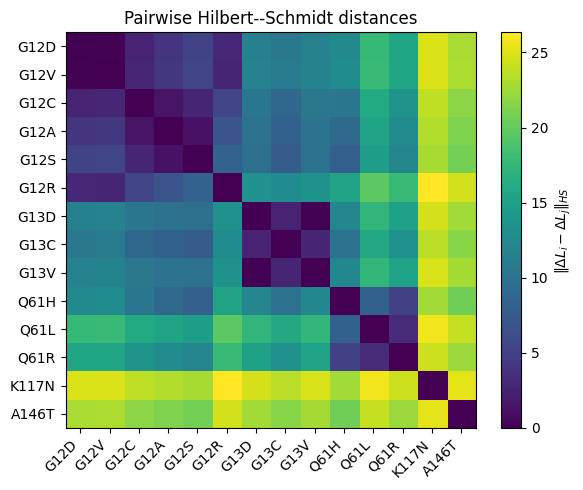

In [11]:
plt.figure(figsize=(6, 5))
plt.imshow(D_hs, aspect="auto")
plt.xticks(range(N_mut), mutation_names, rotation=45, ha="right")
plt.yticks(range(N_mut), mutation_names)
plt.colorbar(label=r"$\|\Delta L_i - \Delta L_j\|_{HS}$")
plt.title("Pairwise Hilbert--Schmidt distances")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mutation_operator_distance_matrix.png", dpi=300)
plt.show()


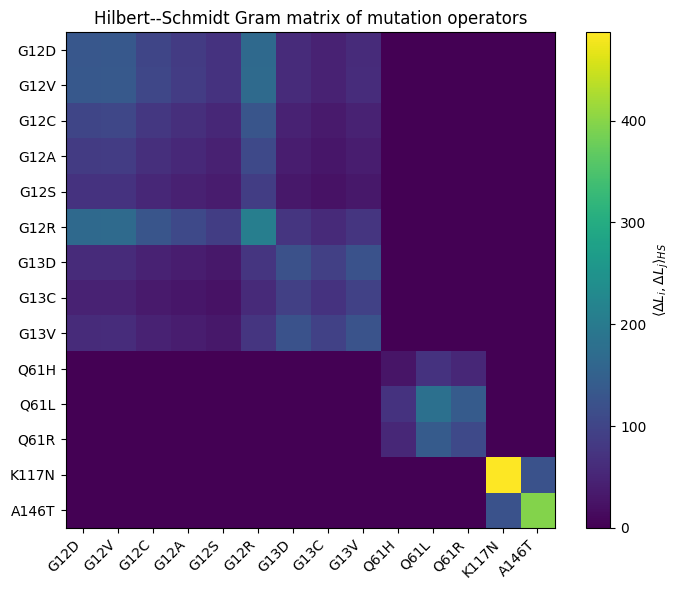

In [12]:
plt.figure(figsize=(7, 6))
plt.imshow(G_hs, aspect="auto")
plt.xticks(range(N_mut), mutation_names, rotation=45, ha="right")
plt.yticks(range(N_mut), mutation_names)
plt.colorbar(label=r"$\langle \Delta L_i,\Delta L_j\rangle_{HS}$")
plt.title("Hilbert--Schmidt Gram matrix of mutation operators")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mutation_operator_gram_matrix.png", dpi=300)
plt.show()


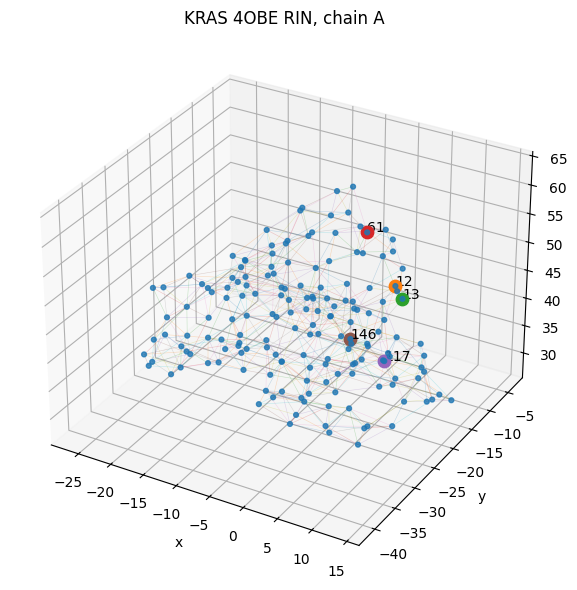

In [13]:
# 3D visualization of the RIN using C-alpha coordinates.
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")

# Plot edges
for u, v in G_wt.edges():
    p = coords[u]
    q = coords[v]
    ax.plot([p[0], q[0]], [p[1], q[1]], [p[2], q[2]], linewidth=0.4, alpha=0.25)

# Plot nodes
ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], s=12, alpha=0.8)

# Highlight mutation residues
highlight_resnums = sorted({r for spec in mutation_specs for r in spec["resnums"]})
for resnum in highlight_resnums:
    if resnum in resnum_to_node:
        node = resnum_to_node[resnum]
        p = coords[node]
        ax.scatter([p[0]], [p[1]], [p[2]], s=80)
        ax.text(p[0], p[1], p[2], str(resnum), fontsize=10)

ax.set_title(f"KRAS {PDB_ID} RIN, chain {CHAIN_ID}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kras_rin_3d.png", dpi=300)
plt.show()



## 9. Experiment 2 — Validation of the variational representative selection functional

In [14]:

import itertools
from dataclasses import dataclass

# ---------------------------------------------------------------------
# Experiment 2 configuration
# ---------------------------------------------------------------------
# Nominal reference value used for the main experiments. Its robustness is
# evaluated explicitly over a broad grid below; for k=5 the v1 results show
# a stable representative subset across the broad plateau mu >= 0.1.
MU = 1.0
N_RANDOM_BASELINE = 1000

# Final paper strategy: use k=5 as the main showcase value, and k=4,6 as compact robustness checks.
K_MAIN = min(5, N_mut)
K_ROBUSTNESS = [k for k in [4, 5, 6] if 1 <= k <= N_mut]
if K_MAIN not in K_ROBUSTNESS:
    K_ROBUSTNESS.append(K_MAIN)
k_values = sorted(set(K_ROBUSTNESS))
if len(k_values) == 0:
    k_values = list(range(1, min(N_mut, 6) + 1))

# The theory uses V_i = Tr(Delta L_i^2), which equals ||Delta L_i||_HS^2
# for real symmetric perturbation operators.
V_vec = np.array([
    hilbert_schmidt_norm(delta_laplacians[name]) ** 2
    for name in mutation_names
], dtype=float)

# The theory uses D_ij = d_ij^2, with d_ij = ||Delta L_i - Delta L_j||_HS.
D_sq = D_hs ** 2


def mask_from_indices(indices: tuple[int, ...], n: int) -> np.ndarray:
    mask = np.zeros(n, dtype=int)
    mask[list(indices)] = 1
    return mask


def names_from_mask(mask: np.ndarray) -> list[str]:
    return [mutation_names[i] for i, value in enumerate(mask) if value == 1]


def mask_from_names(names: list[str]) -> np.ndarray:
    """Construct a binary mask from mutation labels."""
    mask = np.zeros(N_mut, dtype=int)
    for name in names:
        if name not in mutation_names:
            raise ValueError(f"Unknown mutation label: {name}")
        mask[mutation_names.index(name)] = 1
    return mask


def variational_components(mask: np.ndarray, V: np.ndarray, D2: np.ndarray, mu: float = 1.0) -> dict:
    """Compute V(R), D(R), and J(R) for a binary selection mask."""
    selected = np.where(mask == 1)[0]

    V_R = float(np.sum(V[selected]))

    D_R = 0.0
    for i_pos, i in enumerate(selected):
        for j in selected[i_pos + 1:]:
            D_R += float(D2[i, j])

    J_R = -V_R - mu * D_R

    return {
        "V": V_R,
        "D": D_R,
        "J": J_R,
    }


def exact_variational_selection(k: int, V: np.ndarray, D2: np.ndarray, mu: float = 1.0) -> dict:
    """Brute-force exact minimization of the variational functional for fixed k."""
    best = None

    for indices in itertools.combinations(range(len(V)), k):
        mask = mask_from_indices(indices, len(V))
        values = variational_components(mask, V, D2, mu)

        if best is None or values["J"] < best["J"]:
            best = {
                "mask": mask,
                "indices": indices,
                "selected": names_from_mask(mask),
                **values,
            }

    return best


def top_energy_baseline(k: int, V: np.ndarray, D2: np.ndarray, mu: float = 1.0) -> dict:
    """Baseline: select the k largest individual perturbation energies."""
    indices = tuple(np.argsort(-V)[:k])
    mask = mask_from_indices(indices, len(V))
    values = variational_components(mask, V, D2, mu)

    return {
        "mask": mask,
        "indices": indices,
        "selected": names_from_mask(mask),
        **values,
    }


def random_baseline(k: int, V: np.ndarray, D2: np.ndarray, mu: float = 1.0, n_samples: int = 1000) -> dict:
    """Random baseline averaged over uniformly sampled subsets of cardinality k."""
    rng = np.random.default_rng(RANDOM_SEED + k)
    all_values = []

    for _ in range(n_samples):
        indices = tuple(rng.choice(len(V), size=k, replace=False))
        mask = mask_from_indices(indices, len(V))
        all_values.append(variational_components(mask, V, D2, mu))

    return {
        "V_mean": float(np.mean([v["V"] for v in all_values])),
        "V_std": float(np.std([v["V"] for v in all_values])),
        "D_mean": float(np.mean([v["D"] for v in all_values])),
        "D_std": float(np.std([v["D"] for v in all_values])),
        "J_mean": float(np.mean([v["J"] for v in all_values])),
        "J_std": float(np.std([v["J"] for v in all_values])),
    }


experiment_2_rows = []

for k in k_values:
    exact = exact_variational_selection(k, V_vec, D_sq, MU)
    top = top_energy_baseline(k, V_vec, D_sq, MU)
    rnd = random_baseline(k, V_vec, D_sq, MU, N_RANDOM_BASELINE)

    experiment_2_rows.append({
        "k": k,
        "method": "variational_exact",
        "selected": ", ".join(exact["selected"]),
        "V": exact["V"],
        "D": exact["D"],
        "J": exact["J"],
    })

    experiment_2_rows.append({
        "k": k,
        "method": "top_perturbation_energy",
        "selected": ", ".join(top["selected"]),
        "V": top["V"],
        "D": top["D"],
        "J": top["J"],
    })

    experiment_2_rows.append({
        "k": k,
        "method": "random_mean",
        "selected": "random subsets",
        "V": rnd["V_mean"],
        "D": rnd["D_mean"],
        "J": rnd["J_mean"],
        "V_std": rnd["V_std"],
        "D_std": rnd["D_std"],
        "J_std": rnd["J_std"],
    })

experiment_2_df = pd.DataFrame(experiment_2_rows)
experiment_2_df


,k,method,selected,V,D,J,V_std,D_std,J_std
0,4,variational_exact,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
1,4,top_perturbation_energy,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
2,4,random_mean,random subsets,617.829325,1446.336043,-2064.165368,228.385208,800.226776,1019.202942
3,5,variational_exact,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,NaN,NaN,NaN
4,5,top_perturbation_energy,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,NaN,NaN,NaN
5,5,random_mean,random subsets,782.681122,2464.140017,-3246.821139,244.176041,1110.472630,1346.020354
6,6,variational_exact,"G12R, G13V, Q61L, Q61R, K117N, A146T",1501.562706,6831.761863,-8333.324568,NaN,NaN,NaN
7,6,top_perturbation_energy,"G12D, G12V, G12R, Q61L, K117N, A146T",1538.509652,6510.405222,-8048.914874,NaN,NaN,NaN
8,6,random_mean,random subsets,935.434201,3681.943778,-4617.377978,246.044177,1402.282311,1639.518803


In [15]:

# Save Experiment 2 results
experiment_2_df.to_csv(OUTPUT_DIR / "experiment_2_variational_selection_results.csv", index=False)

print("Experiment 2 saved:")
print(" -", OUTPUT_DIR / "experiment_2_variational_selection_results.csv")


Experiment 2 saved:
 - kras_operator_space_v5_outputs/experiment_2_variational_selection_results.csv


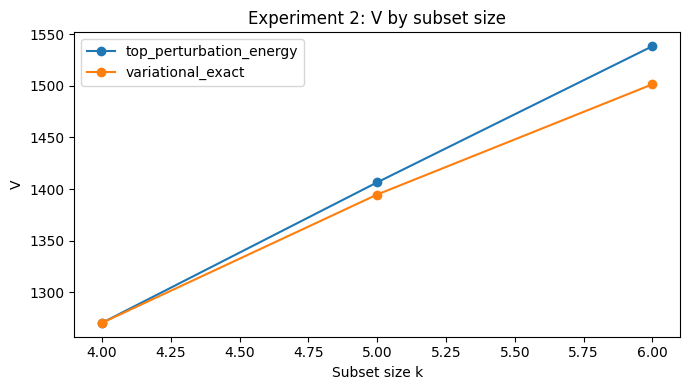

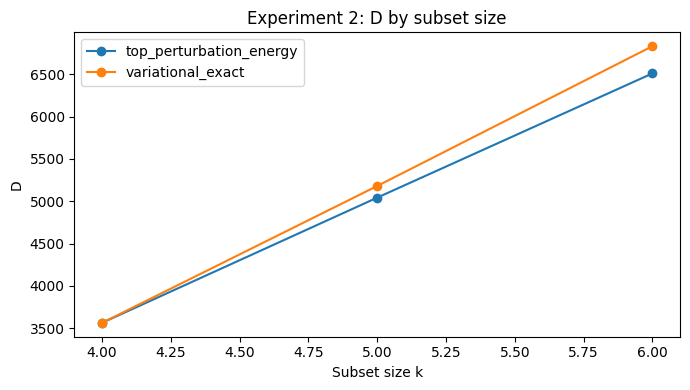

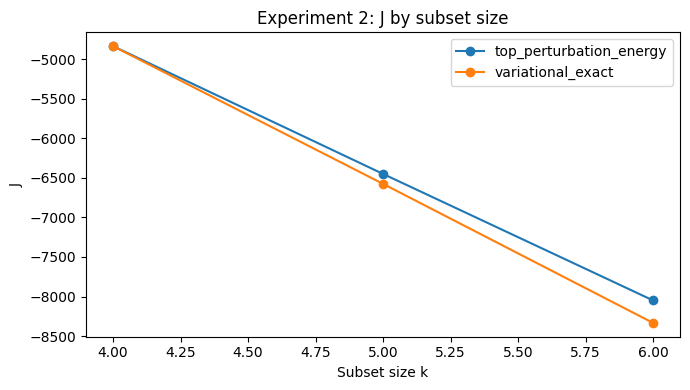

Saved Experiment 2 comparison figures.


In [16]:

# Plot comparison of V, D, and J across k values for deterministic methods.
det_df = experiment_2_df[experiment_2_df["method"].isin(["variational_exact", "top_perturbation_energy"])].copy()

for metric in ["V", "D", "J"]:
    plt.figure(figsize=(7, 4))

    for method, group in det_df.groupby("method"):
        group = group.sort_values("k")
        plt.plot(group["k"], group[metric], marker="o", label=method)

    plt.xlabel("Subset size k")
    plt.ylabel(metric)
    plt.title(f"Experiment 2: {metric} by subset size")
    plt.legend()
    plt.tight_layout()

    out_path = OUTPUT_DIR / f"experiment_2_{metric}_comparison.png"
    plt.savefig(out_path, dpi=200)
    plt.show()

print("Saved Experiment 2 comparison figures.")


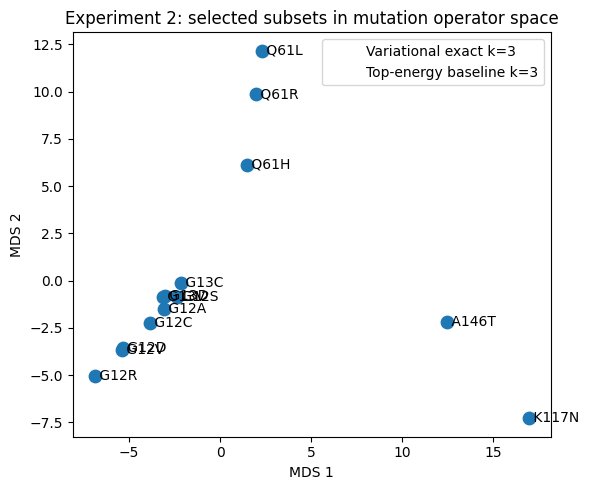

Saved: kras_operator_space_v5_outputs/experiment_2_mds_selected_subsets.png


In [17]:

# Classical MDS visualization of the mutation operator space.
def classical_mds(distance_matrix: np.ndarray, n_components: int = 2) -> np.ndarray:
    """Classical multidimensional scaling from a distance matrix."""
    D2 = distance_matrix ** 2
    n = D2.shape[0]
    J_center = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J_center @ D2 @ J_center

    evals, evecs = np.linalg.eigh(B)
    idx = np.argsort(evals)[::-1]
    evals = evals[idx]
    evecs = evecs[:, idx]

    positive = np.maximum(evals[:n_components], 0)
    coords_mds = evecs[:, :n_components] * np.sqrt(positive)

    return coords_mds


mds_coords = classical_mds(D_hs, n_components=2)

# Choose a representative k for visualization.
k_plot = min(3, N_mut)
exact_plot = exact_variational_selection(k_plot, V_vec, D_sq, MU)
top_plot = top_energy_baseline(k_plot, V_vec, D_sq, MU)

plt.figure(figsize=(6, 5))
plt.scatter(mds_coords[:, 0], mds_coords[:, 1], s=80)

for i, name in enumerate(mutation_names):
    plt.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", va="center")

exact_indices = list(exact_plot["indices"])
top_indices = list(top_plot["indices"])

plt.scatter(
    mds_coords[exact_indices, 0],
    mds_coords[exact_indices, 1],
    s=220,
    facecolors="none",
    linewidths=2,
    label=f"Variational exact k={k_plot}",
)

plt.scatter(
    mds_coords[top_indices, 0],
    mds_coords[top_indices, 1],
    s=120,
    marker="s",
    facecolors="none",
    linewidths=2,
    label=f"Top-energy baseline k={k_plot}",
)

plt.xlabel("MDS 1")
plt.ylabel("MDS 2")
plt.title("Experiment 2: selected subsets in mutation operator space")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_2_mds_selected_subsets.png"
plt.savefig(out_path, dpi=200)
plt.show()

print("Saved:", out_path)



## 10. Experiment 3 — Validation of the exact QUBO and Ising reformulations


In [18]:

# ---------------------------------------------------------------------
# Experiment 3: Exact reformulation checks
# ---------------------------------------------------------------------

def build_qubo_matrix(
    V: np.ndarray,
    D2: np.ndarray,
    mu: float,
    lam: float,
    k: int,
) -> np.ndarray:
    """Build the symmetric QUBO matrix A under Q(x)=x^T A x + lambda k^2."""
    n = len(V)
    one = np.ones((n, 1))
    I = np.eye(n)

    return (
        -np.diag(V)
        - (mu / 2.0) * D2
        + lam * (one @ one.T)
        - 2.0 * lam * k * I
    )


def penalty_bound_B(V: np.ndarray, D2: np.ndarray, mu: float) -> float:
    """Conservative exact penalty bound B."""
    upper_tri_sum = float(np.sum(np.triu(D2, k=1)))
    return float(np.sum(V) + mu * upper_tri_sum)


def qubo_energy(mask: np.ndarray, A: np.ndarray, lam: float, k: int) -> float:
    """Penalized QUBO energy."""
    x = mask.astype(float)
    return float(x.T @ A @ x + lam * (k ** 2))


def binary_to_spin(mask: np.ndarray) -> np.ndarray:
    """Map x in {0,1}^N to z in {-1,+1}^N using x=(1-z)/2."""
    return 1 - 2 * mask.astype(int)


def spin_to_binary(z: np.ndarray) -> np.ndarray:
    """Map z in {-1,+1}^N to x in {0,1}^N using x=(1-z)/2."""
    return ((1 - z) // 2).astype(int)


def ising_coefficients_from_A(A: np.ndarray, lam: float, k: int) -> dict:
    """Compute E0, h, and J from the symmetric QUBO matrix A."""
    n = A.shape[0]
    one = np.ones(n)

    E0 = float(lam * (k ** 2) + 0.25 * (one.T @ A @ one + np.trace(A)))
    h = -0.5 * np.sum(A, axis=1)

    J = np.zeros_like(A, dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            J[i, j] = 0.5 * A[i, j]
            J[j, i] = J[i, j]

    return {"E0": E0, "h": h, "J": J}


def ising_energy(z: np.ndarray, coeffs: dict) -> float:
    """Classical Ising energy E0 + sum_i h_i z_i + sum_{i<j} J_ij z_i z_j."""
    E = coeffs["E0"] + float(np.dot(coeffs["h"], z))

    J = coeffs["J"]
    n = len(z)
    for i in range(n):
        for j in range(i + 1, n):
            E += float(J[i, j] * z[i] * z[j])

    return float(E)


def all_binary_masks(n: int):
    """Generate all binary masks of length n."""
    for bits in itertools.product([0, 1], repeat=n):
        yield np.array(bits, dtype=int)


experiment_3_rows = []
B_bound = penalty_bound_B(V_vec, D_sq, MU)

for k in k_values:
    lam = 1.05 * B_bound if B_bound > 0 else 1.0

    A_qubo = build_qubo_matrix(V_vec, D_sq, MU, lam, k)
    coeffs = ising_coefficients_from_A(A_qubo, lam, k)

    # Direct constrained variational optimum
    exact_var = exact_variational_selection(k, V_vec, D_sq, MU)

    # Unconstrained QUBO optimum over all bitstrings
    best_qubo = None
    best_ising = None
    max_energy_mismatch = 0.0

    for mask in all_binary_masks(N_mut):
        z = binary_to_spin(mask)

        q_energy = qubo_energy(mask, A_qubo, lam, k)
        i_energy = ising_energy(z, coeffs)
        max_energy_mismatch = max(max_energy_mismatch, abs(q_energy - i_energy))

        if best_qubo is None or q_energy < best_qubo["energy"]:
            best_qubo = {
                "mask": mask,
                "energy": q_energy,
                "selected": names_from_mask(mask),
                "cardinality": int(mask.sum()),
            }

        if best_ising is None or i_energy < best_ising["energy"]:
            best_ising = {
                "z": z,
                "mask": mask,
                "energy": i_energy,
                "selected": names_from_mask(mask),
                "cardinality": int(mask.sum()),
            }

    var_mask = exact_var["mask"]
    var_qubo_energy = qubo_energy(var_mask, A_qubo, lam, k)
    var_ising_energy = ising_energy(binary_to_spin(var_mask), coeffs)

    experiment_3_rows.append({
        "k": k,
        "lambda": lam,
        "B_bound": B_bound,
        "variational_selected": ", ".join(exact_var["selected"]),
        "qubo_selected": ", ".join(best_qubo["selected"]),
        "ising_selected": ", ".join(best_ising["selected"]),
        "variational_J": exact_var["J"],
        "qubo_min_energy": best_qubo["energy"],
        "ising_min_energy": best_ising["energy"],
        "qubo_energy_at_variational_solution": var_qubo_energy,
        "ising_energy_at_variational_solution": var_ising_energy,
        "qubo_cardinality": best_qubo["cardinality"],
        "ising_cardinality": best_ising["cardinality"],
        "same_variational_qubo_subset": set(exact_var["selected"]) == set(best_qubo["selected"]),
        "same_variational_ising_subset": set(exact_var["selected"]) == set(best_ising["selected"]),
        "max_abs_qubo_ising_energy_mismatch": max_energy_mismatch,
    })

experiment_3_df = pd.DataFrame(experiment_3_rows)
experiment_3_df


,k,lambda,B_bound,variational_selected,qubo_selected,ising_selected,variational_J,qubo_min_energy,ising_min_energy,qubo_energy_at_variational_solution,ising_energy_at_variational_solution,qubo_cardinality,ising_cardinality,same_variational_qubo_subset,same_variational_ising_subset,max_abs_qubo_ising_energy_mismatch
0,4,25389.536101,24180.510572,"G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T",-4833.915354,-4833.915354,-4833.915354,-4833.915354,-4833.915354,4,4,True,True,1.862645e-09
1,5,25389.536101,24180.510572,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",-6574.992212,-6574.992212,-6574.992212,-6574.992212,-6574.992212,5,5,True,True,1.396984e-09
2,6,25389.536101,24180.510572,"G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T",-8333.324568,-8333.324568,-8333.324568,-8333.324568,-8333.324568,6,6,True,True,6.984919e-10


In [19]:

# Save Experiment 3 outputs
experiment_3_df.to_csv(OUTPUT_DIR / "experiment_3_exact_reformulation_validation.csv", index=False)

# Save one QUBO matrix and Ising coefficients per k.
for k in k_values:
    lam = 1.05 * B_bound if B_bound > 0 else 1.0
    A_qubo = build_qubo_matrix(V_vec, D_sq, MU, lam, k)
    coeffs = ising_coefficients_from_A(A_qubo, lam, k)

    np.save(OUTPUT_DIR / f"experiment_3_qubo_A_k{k}.npy", A_qubo)
    np.save(OUTPUT_DIR / f"experiment_3_ising_h_k{k}.npy", coeffs["h"])
    np.save(OUTPUT_DIR / f"experiment_3_ising_J_k{k}.npy", coeffs["J"])

print("Experiment 3 saved:")
print(" -", OUTPUT_DIR / "experiment_3_exact_reformulation_validation.csv")


Experiment 3 saved:
 - kras_operator_space_v5_outputs/experiment_3_exact_reformulation_validation.csv


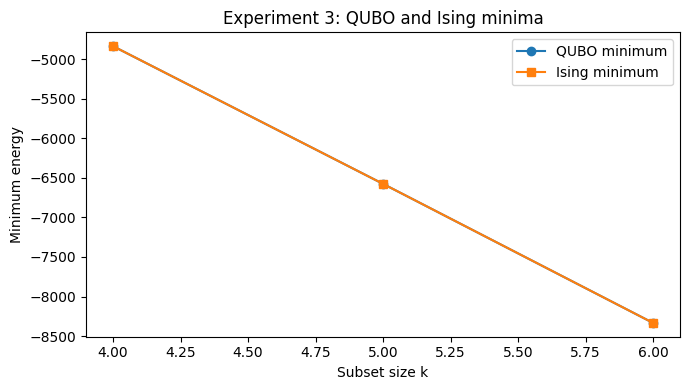

Saved: kras_operator_space_v5_outputs/experiment_3_qubo_ising_minima.png


,k,variational_selected,qubo_selected,ising_selected,qubo_cardinality,ising_cardinality,same_variational_qubo_subset,same_variational_ising_subset,max_abs_qubo_ising_energy_mismatch
0,4,"G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T",4,4,True,True,1.862645e-09
1,5,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",5,5,True,True,1.396984e-09
2,6,"G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T",6,6,True,True,6.984919e-10


In [20]:

# Plot exact reformulation validation.
plt.figure(figsize=(7, 4))
plt.plot(experiment_3_df["k"], experiment_3_df["qubo_min_energy"], marker="o", label="QUBO minimum")
plt.plot(experiment_3_df["k"], experiment_3_df["ising_min_energy"], marker="s", label="Ising minimum")
plt.xlabel("Subset size k")
plt.ylabel("Minimum energy")
plt.title("Experiment 3: QUBO and Ising minima")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_3_qubo_ising_minima.png"
plt.savefig(out_path, dpi=200)
plt.show()

print("Saved:", out_path)

display(experiment_3_df[[
    "k",
    "variational_selected",
    "qubo_selected",
    "ising_selected",
    "qubo_cardinality",
    "ising_cardinality",
    "same_variational_qubo_subset",
    "same_variational_ising_subset",
    "max_abs_qubo_ising_energy_mismatch",
]])


## 11. Experiment 4 — Optimization backends for the induced Hamiltonian

This experiment evaluates **optimization backends**, not alternative representative-selection models. The representative-selection objective has already been fixed by the operator geometry and the prescribed cardinality \(k\).

For exact enumeration, all feasible subsets are evaluated and the global optimum is used as the reference.

For simulated annealing, every proposal exchanges one selected and one unselected mutation, so all iterates remain in the Hamming-weight-\(k\) feasible subspace.

For the gate-based quantum experiment, we use a **cardinality-preserving XY-QAOA ansatz**. The initial state is the uniform Dicke state over all bit strings of Hamming weight \(k\),

\[
|D_k^N\rangle
=
\binom{N}{k}^{-1/2}
\sum_{|x|=k}|x\rangle.
\]

The mixer is generated locally by nearest-neighbor XY interactions on a ring,

\[
H_M^{XY}
=
\frac{1}{2}
\sum_{(i,j)\in E_{\rm ring}}
\left(X_iX_j+Y_iY_j\right),
\]

which preserve total Hamming weight. Numerically, one mixer layer is implemented through a symmetric even--odd--even product of two-qubit XY rotations. The induced mixer graph is explicitly checked to be connected on the complete fixed-\(k\) basis.

The cost phase is the same geometry-induced objective derived from the QUBO/Ising formulation, restricted to the feasible subspace. Since the cardinality penalty vanishes identically for \(|x|=k\), this restriction does not alter the ordering of feasible representative subsets.

For numerical conditioning, the feasible cost spectrum is shifted by its minimum and divided by its spectral span before phase application. This only removes a global phase and reparameterizes the variational angle \(\gamma\); it does not change the minimizing configurations.

The QAOA study is deliberately interpreted as a **backend-compatibility and depth-behavior experiment**. It is not used to define, biologically interpret, or geometrically evaluate a different representative subset. The primary reported QAOA quantities are therefore:
- expected-energy gap to the exact optimum,
- single-shot probability of an exact optimum, and
- independent shots required for 95% probability of observing at least one optimum.

The statevector simulation initializes the Dicke state exactly. A hardware implementation would additionally require a Dicke-state preparation circuit; this preparation overhead is not benchmarked here.


In [21]:
from scipy.optimize import minimize
import multiprocessing
import math

try:
    from joblib import Parallel, delayed
    JOBLIB_AVAILABLE = True
except ImportError:
    JOBLIB_AVAILABLE = False
    Parallel = None
    delayed = None

# ---------------------------------------------------------------------
# Experiment 4 configuration
# ---------------------------------------------------------------------
K_QOPT = K_MAIN
LAMBDA_QOPT = 1.05 * B_bound if B_bound > 0 else 1.0

# XY-QAOA settings.
QAOA_P_VALUES = [1, 2, 3, 4, 5]
QAOA_RESTARTS = 20
QAOA_SHOTS = 3000
QAOA_MAXITER = 800
QAOA_TARGET_SUCCESS = 0.95

# Fixed-cardinality simulated annealing.
SA_RESTARTS = 100
SA_STEPS = 1000

# Parallel execution. NumPy/BLAS may already use internal threads,
# so keep the outer process count moderate.
N_JOBS = min(8, multiprocessing.cpu_count()) if JOBLIB_AVAILABLE else 1
PARALLEL_BACKEND = "loky"

A_qopt = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_QOPT, K_QOPT)
coeffs_qopt = ising_coefficients_from_A(A_qopt, LAMBDA_QOPT, K_QOPT)

# Full penalized spectrum: exact consistency reference.
all_masks_list = list(all_binary_masks(N_mut))
all_masks_array = np.asarray(all_masks_list, dtype=int)
all_energies = np.array([
    qubo_energy(mask, A_qopt, LAMBDA_QOPT, K_QOPT)
    for mask in all_masks_list
], dtype=float)

exact_energy = float(np.min(all_energies))
optimal_indices = np.where(np.isclose(all_energies, exact_energy, atol=1e-9))[0]
optimal_masks = [all_masks_list[i] for i in optimal_indices]

# Fixed-cardinality basis used by both constrained backends.
feasible_global_indices = np.where(np.sum(all_masks_array, axis=1) == K_QOPT)[0]
feasible_masks = all_masks_array[feasible_global_indices]
feasible_energies = all_energies[feasible_global_indices]

exact_feasible_energy = float(np.min(feasible_energies))
feasible_optimal_indices = np.where(
    np.isclose(feasible_energies, exact_feasible_energy, atol=1e-9)
)[0]

if not np.isclose(exact_feasible_energy, exact_energy, atol=1e-9):
    raise RuntimeError(
        "The exact penalty did not reproduce the fixed-cardinality optimum. "
        "Increase lambda or inspect the QUBO construction."
    )

print("Experiment 4 target")
print("-------------------")
print(f"k = {K_QOPT}")
print(f"lambda = {LAMBDA_QOPT:.6g}")
print(f"exact minimum energy = {exact_energy:.6g}")
print(f"fixed-k basis size = {len(feasible_masks)} = C({N_mut},{K_QOPT})")
print(f"number of degenerate optima = {len(feasible_optimal_indices)}")
print(f"parallel backend available = {JOBLIB_AVAILABLE}")
print(f"N_JOBS = {N_JOBS}")
print("one exact optimum:", names_from_mask(feasible_masks[feasible_optimal_indices[0]]))


Experiment 4 target
-------------------
k = 5
lambda = 25389.5
exact minimum energy = -6574.99
fixed-k basis size = 2002 = C(14,5)
number of degenerate optima = 1
parallel backend available = True
N_JOBS = 2
one exact optimum: ['G12R', 'G13V', 'Q61L', 'K117N', 'A146T']


In [22]:
# ---------------------------------------------------------------------
# Fixed-cardinality XY-QAOA
# ---------------------------------------------------------------------

def rescale_cost_spectrum(energies: np.ndarray) -> tuple[np.ndarray, float, float]:
    """Shift and divide the feasible spectrum by its span.

    If H'=(H-Emin I)/(Emax-Emin), then exp(-i gamma H') differs from
    evolution under H only by a global phase and a rescaling of gamma.
    The minimizing configurations are therefore unchanged.
    """
    energies = np.asarray(energies, dtype=float)
    e_min = float(np.min(energies))
    span = float(np.max(energies) - e_min)
    if span <= 0:
        span = 1.0
    return (energies - e_min) / span, e_min, span


def build_ring_matchings(n_qubits: int):
    """Return the two disjoint edge matchings of an even cycle."""
    if n_qubits % 2 != 0:
        raise ValueError("This implementation uses the two-matching decomposition of an even ring.")

    even_matching = [(i, i + 1) for i in range(0, n_qubits, 2)]
    odd_matching = [(i, i + 1) for i in range(1, n_qubits - 1, 2)]
    odd_matching.append((n_qubits - 1, 0))
    return even_matching, odd_matching


def build_xy_swap_pairs(
    basis_masks: np.ndarray,
    edges: list[tuple[int, int]],
):
    """Precompute basis-index pairs mixed by each XY edge.

    Each pair contains two feasible basis states that differ only by
    01 <-> 10 on the selected edge.
    """
    mask_to_index = {
        tuple(mask.tolist()): idx
        for idx, mask in enumerate(basis_masks)
    }

    edge_pairs = {}
    for q1, q2 in edges:
        left = []
        right = []

        for idx, mask in enumerate(basis_masks):
            # Store each unordered pair once.
            if mask[q1] == 0 and mask[q2] == 1:
                partner = mask.copy()
                partner[q1], partner[q2] = 1, 0
                partner_idx = mask_to_index[tuple(partner.tolist())]
                left.append(idx)
                right.append(partner_idx)

        edge_pairs[(q1, q2)] = (
            np.asarray(left, dtype=int),
            np.asarray(right, dtype=int),
        )

    return edge_pairs


def apply_xy_edge_rotation(
    psi: np.ndarray,
    pair_indices: tuple[np.ndarray, np.ndarray],
    angle: float,
) -> None:
    """Apply exp[-i angle (XX+YY)/2] for one edge in-place.

    In the {|01>,|10>} sector the generator is the Pauli-X matrix,
    giving amplitudes cos(angle) and -i sin(angle).
    """
    idx_a, idx_b = pair_indices
    if len(idx_a) == 0:
        return

    amp_a = psi[idx_a].copy()
    amp_b = psi[idx_b].copy()

    c = np.cos(angle)
    s = -1j * np.sin(angle)

    psi[idx_a] = c * amp_a + s * amp_b
    psi[idx_b] = s * amp_a + c * amp_b


def apply_xy_matching(
    psi: np.ndarray,
    matching,
    edge_pairs,
    angle: float,
) -> None:
    """Apply all commuting XY rotations in one disjoint matching."""
    for edge in matching:
        apply_xy_edge_rotation(psi, edge_pairs[edge], angle)


def xy_ring_mixer_layer(
    psi: np.ndarray,
    beta: float,
    even_matching,
    odd_matching,
    edge_pairs,
) -> np.ndarray:
    """Symmetric even--odd--even XY ring-mixer layer.

    This is a second-order product implementation of the local XY mixer:
        exp(-i beta H_even/2)
        exp(-i beta H_odd)
        exp(-i beta H_even/2)
    with commuting two-qubit interactions inside each matching.
    """
    out = psi.copy()
    apply_xy_matching(out, even_matching, edge_pairs, beta / 2.0)
    apply_xy_matching(out, odd_matching, edge_pairs, beta)
    apply_xy_matching(out, even_matching, edge_pairs, beta / 2.0)
    return out


def validate_xy_mixer_connectivity(
    n_basis: int,
    edge_pairs,
) -> tuple[bool, int]:
    """Check that the mixer graph connects the whole feasible basis."""
    adjacency = [[] for _ in range(n_basis)]

    for idx_a, idx_b in edge_pairs.values():
        for a, b in zip(idx_a.tolist(), idx_b.tolist()):
            adjacency[a].append(b)
            adjacency[b].append(a)

    visited = np.zeros(n_basis, dtype=bool)
    stack = [0]
    visited[0] = True

    while stack:
        node = stack.pop()
        for nxt in adjacency[node]:
            if not visited[nxt]:
                visited[nxt] = True
                stack.append(nxt)

    return bool(np.all(visited)), int(np.sum(visited))


# Build the local ring mixer once.
XY_EVEN_MATCHING, XY_ODD_MATCHING = build_ring_matchings(N_mut)
XY_RING_EDGES = XY_EVEN_MATCHING + XY_ODD_MATCHING
XY_EDGE_PAIRS = build_xy_swap_pairs(feasible_masks, XY_RING_EDGES)

xy_connected, xy_reachable = validate_xy_mixer_connectivity(
    len(feasible_masks),
    XY_EDGE_PAIRS,
)
print("XY ring edges:", XY_RING_EDGES)
print(
    f"XY mixer connectivity on fixed-k basis: "
    f"{xy_reachable}/{len(feasible_masks)} states reachable"
)
if not xy_connected:
    raise RuntimeError("The chosen XY mixer is not connected on the feasible basis.")


def xy_qaoa_state(
    params: np.ndarray,
    p: int,
    scaled_energies: np.ndarray,
) -> np.ndarray:
    """Return the fixed-cardinality XY-QAOA state for p layers."""
    n_states = len(scaled_energies)
    betas = params[:p]
    gammas = params[p:]

    # Exact Dicke state in the fixed-cardinality basis.
    psi = np.ones(n_states, dtype=complex) / np.sqrt(n_states)

    for beta, gamma in zip(betas, gammas):
        # Cost unitary: diagonal restriction of the geometry-induced Hamiltonian.
        psi = np.exp(-1j * gamma * scaled_energies) * psi

        # Local cardinality-preserving XY mixer.
        psi = xy_ring_mixer_layer(
            psi,
            beta,
            XY_EVEN_MATCHING,
            XY_ODD_MATCHING,
            XY_EDGE_PAIRS,
        )

    return psi


def xy_qaoa_objective(
    params: np.ndarray,
    p: int,
    scaled_energies: np.ndarray,
) -> float:
    psi = xy_qaoa_state(params, p, scaled_energies)
    probs = np.abs(psi) ** 2
    return float(np.dot(probs, scaled_energies))


def _optimize_xy_qaoa_initial_point(
    p: int,
    scaled_energies: np.ndarray,
    x0: np.ndarray,
    maxiter: int,
    restart_label: str,
) -> dict:
    """Optimize one XY-QAOA initial point."""
    bounds = [(0.0, 2.0 * np.pi)] * (2 * p)

    result = minimize(
        xy_qaoa_objective,
        x0=np.asarray(x0, dtype=float),
        args=(p, scaled_energies),
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": maxiter, "ftol": 1e-12},
    )

    return {
        "p": p,
        "params": result.x,
        "scaled_expectation": float(result.fun),
        "success": bool(result.success),
        "message": str(result.message),
        "nfev": int(result.nfev),
        "restart_label": restart_label,
    }


def inherited_qaoa_parameters(previous_params: np.ndarray, previous_p: int) -> np.ndarray:
    """Embed a depth-p solution into depth p+1 with an identity final layer."""
    previous_params = np.asarray(previous_params, dtype=float)
    betas = previous_params[:previous_p]
    gammas = previous_params[previous_p:]
    return np.concatenate([betas, [0.0], gammas, [0.0]])


def shots_for_target_success(
    single_shot_probability: float,
    target_probability: float = 0.95,
) -> float:
    """Independent shots required to observe an optimum with target probability."""
    p = float(single_shot_probability)
    target = float(target_probability)

    if p <= 0.0:
        return np.inf
    if p >= 1.0:
        return 1.0

    return float(np.ceil(np.log(1.0 - target) / np.log(1.0 - p)))


def optimize_xy_qaoa(
    p: int,
    feasible_energies: np.ndarray,
    feasible_masks: np.ndarray,
    feasible_optimal_indices: np.ndarray,
    n_restarts: int = 20,
    shots: int = 3000,
    seed: int = 42,
    n_jobs: int = 1,
    maxiter: int = 800,
    warm_start_params: np.ndarray | None = None,
    target_success: float = 0.95,
) -> dict:
    """Optimize XY-QAOA in the prescribed-cardinality subspace."""
    scaled_energies, energy_offset, energy_scale = rescale_cost_spectrum(
        feasible_energies
    )

    rng = np.random.default_rng(seed + 1000 * p)
    initial_points = []
    labels = []

    # Depth p can exactly reproduce the previous depth by appending beta=gamma=0.
    if warm_start_params is not None and p > 1:
        initial_points.append(
            inherited_qaoa_parameters(warm_start_params, p - 1)
        )
        labels.append("inherited")

    for restart in range(n_restarts):
        x0 = np.concatenate([
            rng.uniform(0.0, 2.0 * np.pi, size=p),
            rng.uniform(0.0, 2.0 * np.pi, size=p),
        ])
        initial_points.append(x0)
        labels.append(f"random_{restart}")

    if JOBLIB_AVAILABLE and n_jobs != 1 and len(initial_points) > 1:
        restart_results = Parallel(
            n_jobs=n_jobs,
            backend=PARALLEL_BACKEND,
            verbose=5,
        )(
            delayed(_optimize_xy_qaoa_initial_point)(
                p,
                scaled_energies,
                x0,
                maxiter,
                label,
            )
            for x0, label in zip(initial_points, labels)
        )
    else:
        restart_results = [
            _optimize_xy_qaoa_initial_point(
                p,
                scaled_energies,
                x0,
                maxiter,
                label,
            )
            for x0, label in zip(initial_points, labels)
        ]

    best = min(restart_results, key=lambda row: row["scaled_expectation"])
    best["restart_results"] = restart_results
    best["total_nfev"] = int(sum(row["nfev"] for row in restart_results))

    psi = xy_qaoa_state(best["params"], p, scaled_energies)
    probs = np.abs(psi) ** 2

    norm_error = abs(float(np.sum(probs)) - 1.0)
    if norm_error > 1e-9:
        raise RuntimeError(f"XY-QAOA state normalization error: {norm_error:.3e}")

    expectation_original = float(np.dot(probs, feasible_energies))
    optimal_probability = float(np.sum(probs[feasible_optimal_indices]))

    mode_index = int(np.argmax(probs))
    mode_mask = feasible_masks[mode_index].astype(int)
    mode_energy = float(feasible_energies[mode_index])

    # Finite-shot readout is secondary; the primary metrics are expectation
    # and optimal-state probability.
    sample_rng = np.random.default_rng(seed + 999 + p)
    sampled_indices = sample_rng.choice(
        len(feasible_energies),
        size=shots,
        replace=True,
        p=probs,
    )
    sampled_energies = feasible_energies[sampled_indices]
    sampled_best_index = int(sampled_indices[int(np.argmin(sampled_energies))])

    p_success_shots = float(
        1.0 - (1.0 - optimal_probability) ** shots
    )
    n_target = shots_for_target_success(
        optimal_probability,
        target_probability=target_success,
    )

    best.update({
        "state": psi,
        "probabilities": probs,
        "expectation": expectation_original,
        "expectation_gap": expectation_original - float(np.min(feasible_energies)),
        "optimal_probability": optimal_probability,
        "shots_to_target_success": n_target,
        "target_success_probability": target_success,
        "finite_shot_optimal_success_probability": p_success_shots,
        "feasible_probability": 1.0,
        "mode_index": mode_index,
        "mode_mask": mode_mask,
        "mode_energy": mode_energy,
        "mode_gap": mode_energy - float(np.min(feasible_energies)),
        "mode_selected": names_from_mask(mode_mask),
        "sampled_best_index": sampled_best_index,
        "sampled_best_mask": feasible_masks[sampled_best_index].astype(int),
        "sampled_best_energy": float(feasible_energies[sampled_best_index]),
        "sampled_best_selected": names_from_mask(feasible_masks[sampled_best_index]),
        "sampled_best_cardinality": int(np.sum(feasible_masks[sampled_best_index])),
        "energy_offset": energy_offset,
        "energy_scale": energy_scale,
        "normalization_error": norm_error,
    })

    return best


XY ring edges: [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9), (10, 11), (12, 13), (1, 2), (3, 4), (5, 6), (7, 8), (9, 10), (11, 12), (13, 0)]
XY mixer connectivity on fixed-k basis: 2002/2002 states reachable


In [23]:
# ---------------------------------------------------------------------
# Fixed-cardinality simulated annealing
# ---------------------------------------------------------------------

def _single_fixed_k_sa_restart(
    A: np.ndarray,
    lam: float,
    k: int,
    n_steps: int,
    t_initial: float,
    t_final: float,
    seed: int,
) -> dict:
    """Run one simulated-annealing restart using cardinality-preserving swap moves."""
    rng = np.random.default_rng(seed)
    n = A.shape[0]

    selected = rng.choice(n, size=k, replace=False)
    x = np.zeros(n, dtype=int)
    x[selected] = 1

    e = qubo_energy(x, A, lam, k)
    best_local_x = x.copy()
    best_local_e = e

    for step in range(n_steps):
        frac = step / max(n_steps - 1, 1)
        temp = t_initial * (t_final / t_initial) ** frac

        ones = np.flatnonzero(x)
        zeros = np.flatnonzero(1 - x)

        i = int(rng.choice(ones))
        j = int(rng.choice(zeros))

        x_new = x.copy()
        x_new[i] = 0
        x_new[j] = 1

        e_new = qubo_energy(x_new, A, lam, k)
        delta = e_new - e

        if delta <= 0 or rng.random() < np.exp(-delta / max(temp, 1e-12)):
            x = x_new
            e = e_new

            if e < best_local_e:
                best_local_x = x.copy()
                best_local_e = e

    return {
        "mask": best_local_x,
        "energy": float(best_local_e),
        "selected": names_from_mask(best_local_x),
        "cardinality": int(np.sum(best_local_x)),
    }


def simulated_annealing_fixed_k(
    A: np.ndarray,
    lam: float,
    k: int,
    exact_energy: float,
    n_steps: int = 1000,
    n_restarts: int = 100,
    t_initial: float | None = None,
    t_final: float | None = None,
    seed: int = 42,
    n_jobs: int = 1,
) -> dict:
    """Simulated annealing restricted exactly to the Hamming-weight-k subspace."""
    n = A.shape[0]

    if t_initial is None:
        # Estimate an energy scale from random feasible configurations only.
        temp_rng = np.random.default_rng(seed + 123456)
        n_temp_samples = min(1024, max(256, 32 * n))
        sampled_energies = []

        for _ in range(n_temp_samples):
            selected = temp_rng.choice(n, size=k, replace=False)
            mask = np.zeros(n, dtype=int)
            mask[selected] = 1
            sampled_energies.append(qubo_energy(mask, A, lam, k))

        t_initial = max(float(np.std(sampled_energies)), 1.0)

    if t_final is None:
        t_final = max(1e-3, 1e-4 * t_initial)

    restart_seeds = [seed + 20000 + restart for restart in range(n_restarts)]

    if JOBLIB_AVAILABLE and n_jobs != 1 and n_restarts > 1:
        restart_results = Parallel(
            n_jobs=n_jobs,
            backend=PARALLEL_BACKEND,
            verbose=5,
        )(
            delayed(_single_fixed_k_sa_restart)(
                A,
                lam,
                k,
                n_steps,
                t_initial,
                t_final,
                restart_seed,
            )
            for restart_seed in restart_seeds
        )
    else:
        restart_results = [
            _single_fixed_k_sa_restart(
                A,
                lam,
                k,
                n_steps,
                t_initial,
                t_final,
                restart_seed,
            )
            for restart_seed in restart_seeds
        ]

    energies = np.array([row["energy"] for row in restart_results], dtype=float)
    best_global = min(restart_results, key=lambda row: row["energy"])

    best_global["restart_results"] = restart_results
    best_global["success_rate"] = float(
        np.mean(np.isclose(energies, exact_energy, atol=1e-9))
    )
    best_global["median_energy"] = float(np.median(energies))
    best_global["median_gap"] = float(np.median(energies - exact_energy))
    best_global["mean_gap"] = float(np.mean(energies - exact_energy))
    best_global["t_initial"] = float(t_initial)
    best_global["t_final"] = float(t_final)

    return best_global


In [24]:
# ---------------------------------------------------------------------
# Run Experiment 4 — fixed-cardinality optimization backends
# ---------------------------------------------------------------------
experiment_4_rows = []

exact_mask = feasible_masks[feasible_optimal_indices[0]]
experiment_4_rows.append({
    "method": "exact_enumeration",
    "p": np.nan,
    "energy": exact_energy,
    "expectation": exact_energy,
    "expectation_gap": 0.0,
    "relative_expectation_gap": 0.0,
    "optimal_probability": 1.0,
    "shots_to_95_success": 1.0,
    "mode_energy": exact_energy,
    "mode_gap": 0.0,
    "cardinality": int(np.sum(exact_mask)),
    "selected": ", ".join(names_from_mask(exact_mask)),
    "mode_selected": ", ".join(names_from_mask(exact_mask)),
    "success_rate": 1.0,
})

# XY-QAOA depths are optimized sequentially so each new depth can inherit
# the previous best solution through an identity final layer.
qaoa_results = {}
previous_params = None

for p in QAOA_P_VALUES:
    result = optimize_xy_qaoa(
        p=p,
        feasible_energies=feasible_energies,
        feasible_masks=feasible_masks,
        feasible_optimal_indices=feasible_optimal_indices,
        n_restarts=QAOA_RESTARTS,
        shots=QAOA_SHOTS,
        seed=RANDOM_SEED,
        n_jobs=N_JOBS,
        maxiter=QAOA_MAXITER,
        warm_start_params=previous_params,
        target_success=QAOA_TARGET_SUCCESS,
    )
    qaoa_results[p] = result
    previous_params = result["params"].copy()

    expectation_gap = result["expectation"] - exact_energy

    experiment_4_rows.append({
        "method": "qaoa_xy_fixed_cardinality",
        "p": p,
        "energy": result["mode_energy"],
        "expectation": result["expectation"],
        "expectation_gap": expectation_gap,
        "relative_expectation_gap": expectation_gap / (abs(exact_energy) + 1e-12),
        "optimal_probability": result["optimal_probability"],
        "shots_to_95_success": result["shots_to_target_success"],
        "finite_shot_optimal_success_probability": result[
            "finite_shot_optimal_success_probability"
        ],
        "mode_energy": result["mode_energy"],
        "mode_gap": result["mode_gap"],
        "cardinality": int(np.sum(result["mode_mask"])),
        "selected": ", ".join(result["mode_selected"]),
        "mode_selected": ", ".join(result["mode_selected"]),
        "sampled_best_energy": result["sampled_best_energy"],
        "sampled_best_selected": ", ".join(result["sampled_best_selected"]),
        "total_nfev": result["total_nfev"],
        "normalization_error": result["normalization_error"],
        "success_rate": np.nan,
    })

# Fixed-cardinality simulated annealing.
sa_result = simulated_annealing_fixed_k(
    A=A_qopt,
    lam=LAMBDA_QOPT,
    k=K_QOPT,
    exact_energy=exact_energy,
    n_steps=SA_STEPS,
    n_restarts=SA_RESTARTS,
    seed=RANDOM_SEED,
    n_jobs=N_JOBS,
)

sa_gap = sa_result["energy"] - exact_energy

experiment_4_rows.append({
    "method": "simulated_annealing_fixed_k",
    "p": np.nan,
    "energy": sa_result["energy"],
    "expectation": np.nan,
    "expectation_gap": np.nan,
    "relative_expectation_gap": np.nan,
    "optimal_probability": np.nan,
    "shots_to_95_success": np.nan,
    "mode_energy": sa_result["energy"],
    "mode_gap": sa_gap,
    "cardinality": sa_result["cardinality"],
    "selected": ", ".join(sa_result["selected"]),
    "mode_selected": ", ".join(sa_result["selected"]),
    "success_rate": sa_result["success_rate"],
    "median_gap": sa_result["median_gap"],
    "mean_gap": sa_result["mean_gap"],
})

experiment_4_df = pd.DataFrame(experiment_4_rows)

qaoa_rows = experiment_4_df[
    experiment_4_df["method"] == "qaoa_xy_fixed_cardinality"
].copy()

# Main QAOA depth for downstream diagnostics: lowest expectation,
# breaking numerical ties in favor of larger p.
qaoa_best_p = int(
    qaoa_rows.sort_values(
        ["expectation", "p"],
        ascending=[True, False],
    ).iloc[0]["p"]
)

print("Lowest-expectation XY-QAOA depth:", qaoa_best_p)
print("SA restart success rate:", f"{100 * sa_result['success_rate']:.1f}%")
display(experiment_4_df)


[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    2.3s
[Parallel(n_jobs=2)]: Done  20 out of  20 | elapsed:    2.4s finished
[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  18 out of  21 | elapsed:    3.2s remaining:    0.5s
[Parallel(n_jobs=2)]: Done  21 out of  21 | elapsed:    3.5s finished
[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:    6.7s
[Parallel(n_jobs=2)]: Done  21 out of  21 | elapsed:    9.5s finished
[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  18 tasks      | elapsed:   22.9s
[Parallel(n_jobs=2)]: Done  21 out of  21 | elapsed:   24.9s finished
[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  14 tasks      | elapsed:   40.5s
[Parallel(n_jobs=2)]:

Lowest-expectation XY-QAOA depth: 5
SA restart success rate: 100.0%


[Parallel(n_jobs=2)]: Done 100 out of 100 | elapsed:    7.0s finished


,method,p,energy,expectation,expectation_gap,relative_expectation_gap,optimal_probability,shots_to_95_success,mode_energy,mode_gap,...,selected,mode_selected,success_rate,finite_shot_optimal_success_probability,sampled_best_energy,sampled_best_selected,total_nfev,normalization_error,median_gap,mean_gap
0,exact_enumeration,NaN,-6574.992212,-6574.992212,0.000000,0.000000,1.000000,1.0,-6574.992212,0.000000,...,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,qaoa_xy_fixed_cardinality,1.0,-6574.992212,-4072.935865,2502.056347,0.380541,0.006689,447.0,-6574.992212,0.000000,...,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",NaN,1.000000,-6574.992212,"G12R, G13V, Q61L, K117N, A146T",681.0,4.440892e-16,NaN,NaN
2,qaoa_xy_fixed_cardinality,2.0,-5970.951189,-4490.247179,2084.745033,0.317072,0.008260,362.0,-5970.951189,604.041023,...,"G12C, G13D, Q61L, K117N, A146T","G12C, G13D, Q61L, K117N, A146T",NaN,1.000000,-6574.992212,"G12R, G13V, Q61L, K117N, A146T",2535.0,4.440892e-16,NaN,NaN
3,qaoa_xy_fixed_cardinality,3.0,-5970.951189,-4561.885702,2013.106509,0.306176,0.010464,285.0,-5970.951189,604.041023,...,"G12C, G13D, Q61L, K117N, A146T","G12C, G13D, Q61L, K117N, A146T",NaN,1.000000,-6574.992212,"G12R, G13V, Q61L, K117N, A146T",4487.0,4.440892e-16,NaN,NaN
4,qaoa_xy_fixed_cardinality,4.0,-6449.350856,-4876.822212,1698.170000,0.258277,0.008764,341.0,-6449.350856,125.641355,...,"G12V, G12R, Q61L, K117N, A146T","G12V, G12R, Q61L, K117N, A146T",NaN,1.000000,-6574.992212,"G12R, G13V, Q61L, K117N, A146T",9054.0,4.440892e-16,NaN,NaN
5,qaoa_xy_fixed_cardinality,5.0,-5604.301299,-5099.143966,1475.848246,0.224464,0.002868,1043.0,-5604.301299,970.690913,...,"G12S, G12R, G13D, K117N, A146T","G12S, G12R, G13D, K117N, A146T",NaN,0.999819,-6574.992212,"G12R, G13V, Q61L, K117N, A146T",15939.0,1.554312e-15,NaN,NaN
6,simulated_annealing_fixed_k,NaN,-6574.992212,NaN,NaN,NaN,NaN,NaN,-6574.992212,0.000000,...,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",1.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0


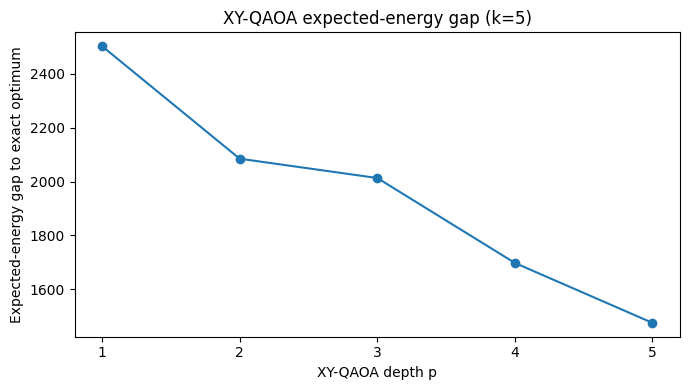

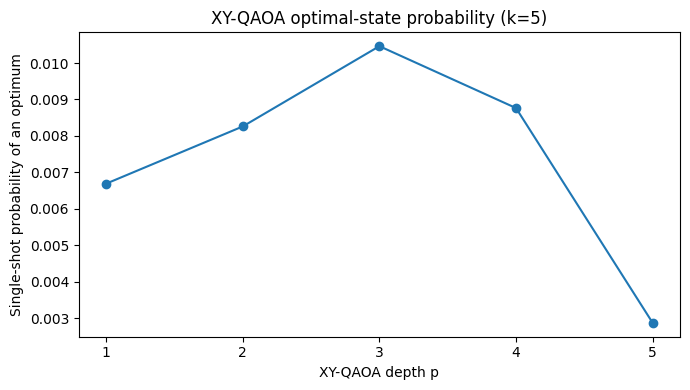

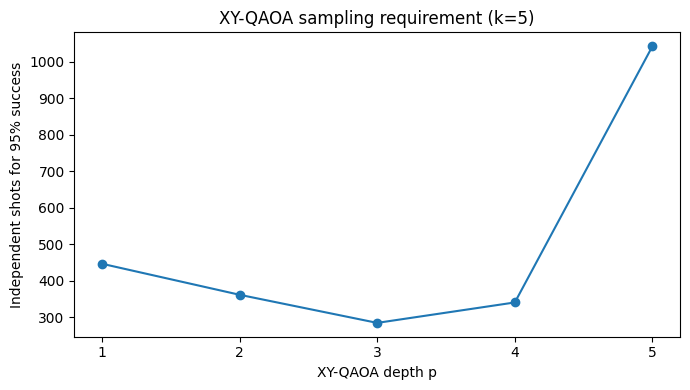

Optimization-backend outputs saved.

XY-QAOA depth summary


,p,expectation,expectation_gap,relative_expectation_gap,optimal_probability,shots_to_95_success
1,1.0,-4072.935865,2502.056347,0.380541,0.006689,447.0
2,2.0,-4490.247179,2084.745033,0.317072,0.008260,362.0
3,3.0,-4561.885702,2013.106509,0.306176,0.010464,285.0
4,4.0,-4876.822212,1698.170000,0.258277,0.008764,341.0
5,5.0,-5099.143966,1475.848246,0.224464,0.002868,1043.0



Simulated annealing summary


,solver,best_energy,best_gap,success_rate,median_gap,mean_gap,n_restarts,steps_per_restart,selected
0,fixed-k simulated annealing,-6574.992212,0.0,1.0,0.0,0.0,100,1000,"G12R, G13V, Q61L, K117N, A146T"


In [25]:
# Save and visualize Experiment 4 outputs.
experiment_4_df.to_csv(
    OUTPUT_DIR / "experiment_4_optimization_backend_diagnostics.csv",
    index=False,
)

qaoa_plot = experiment_4_df[
    experiment_4_df["method"] == "qaoa_xy_fixed_cardinality"
].copy().sort_values("p")

# 1) Expected-energy gap.
plt.figure(figsize=(7, 4))
plt.plot(
    qaoa_plot["p"],
    qaoa_plot["expectation_gap"],
    marker="o",
)
plt.xlabel("XY-QAOA depth p")
plt.ylabel("Expected-energy gap to exact optimum")
plt.title(f"XY-QAOA expected-energy gap (k={K_QOPT})")
plt.xticks(qaoa_plot["p"].astype(int))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "paper_xy_qaoa_expected_gap.png", dpi=300)
plt.show()

# 2) Single-shot probability of an exact optimum.
plt.figure(figsize=(7, 4))
plt.plot(
    qaoa_plot["p"],
    qaoa_plot["optimal_probability"],
    marker="o",
)
plt.xlabel("XY-QAOA depth p")
plt.ylabel("Single-shot probability of an optimum")
plt.title(f"XY-QAOA optimal-state probability (k={K_QOPT})")
plt.xticks(qaoa_plot["p"].astype(int))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "paper_xy_qaoa_optimal_probability.png", dpi=300)
plt.show()

# 3) Independent shots required for 95% success.
plt.figure(figsize=(7, 4))
plt.plot(
    qaoa_plot["p"],
    qaoa_plot["shots_to_95_success"],
    marker="o",
)
plt.xlabel("XY-QAOA depth p")
plt.ylabel("Independent shots for 95% success")
plt.title(f"XY-QAOA sampling requirement (k={K_QOPT})")
plt.xticks(qaoa_plot["p"].astype(int))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "paper_xy_qaoa_shots_to_95.png", dpi=300)
plt.show()

# Compact QAOA table for Section 4.5.
# No representative subset is reported here: QAOA is treated as an optimizer,
# not as a competing biological selection criterion.
qaoa_summary_cols = [
    "p",
    "expectation",
    "expectation_gap",
    "relative_expectation_gap",
    "optimal_probability",
    "shots_to_95_success",
]
qaoa_summary_df = qaoa_plot[qaoa_summary_cols].copy()
qaoa_summary_df.to_csv(
    OUTPUT_DIR / "paper_xy_qaoa_depth_summary.csv",
    index=False,
)

# Classical backend table.
sa_summary_df = pd.DataFrame([{
    "solver": "fixed-k simulated annealing",
    "best_energy": sa_result["energy"],
    "best_gap": sa_result["energy"] - exact_energy,
    "success_rate": sa_result["success_rate"],
    "median_gap": sa_result["median_gap"],
    "mean_gap": sa_result["mean_gap"],
    "n_restarts": SA_RESTARTS,
    "steps_per_restart": SA_STEPS,
    "selected": ", ".join(sa_result["selected"]),
}])
sa_summary_df.to_csv(
    OUTPUT_DIR / "paper_simulated_annealing_summary.csv",
    index=False,
)

print("Optimization-backend outputs saved.")
print("\nXY-QAOA depth summary")
display(qaoa_summary_df)
print("\nSimulated annealing summary")
display(sa_summary_df)


## 12. Experiment 5 — Geometric characterization of the representative-selection model

This experiment evaluates the **representative subsets defined by the model itself**. It compares the exact geometry-induced variational optimum with a perturbation-magnitude-only baseline. Solver outputs are deliberately excluded from these geometric and biological comparisons.

This separation is important: exact enumeration, simulated annealing, and QAOA are alternative mechanisms for searching the same objective, whereas the purpose of the present experiment is to evaluate whether the variational criterion itself improves geometric coverage relative to ranking mutations only by perturbation magnitude.


In [26]:
# ---------------------------------------------------------------------
# Experiment 5: geometric analysis of the model-defined representative subsets
# ---------------------------------------------------------------------

def subset_geometric_metrics(mask: np.ndarray, distance_matrix: np.ndarray) -> dict:
    """Compute diversity and coverage metrics for a selected subset."""
    selected = np.where(mask == 1)[0]

    if len(selected) <= 1:
        avg_pairwise_distance = np.nan
        min_pairwise_distance = np.nan
    else:
        pairwise = []
        for a, i in enumerate(selected):
            for j in selected[a + 1:]:
                pairwise.append(distance_matrix[i, j])
        avg_pairwise_distance = float(np.mean(pairwise))
        min_pairwise_distance = float(np.min(pairwise))

    if len(selected) == 0:
        mean_coverage = np.nan
        max_coverage = np.nan
    else:
        nearest = np.min(distance_matrix[:, selected], axis=1)
        mean_coverage = float(np.mean(nearest))
        max_coverage = float(np.max(nearest))

    return {
        "avg_pairwise_distance": avg_pairwise_distance,
        "min_pairwise_distance": min_pairwise_distance,
        "mean_coverage_distance": mean_coverage,
        "max_coverage_distance": max_coverage,
    }


def row_for_subset(method: str, mask: np.ndarray) -> dict:
    components = variational_components(mask, V_vec, D_sq, MU)
    geom = subset_geometric_metrics(mask, D_hs)
    return {
        "method": method,
        "k": int(np.sum(mask)),
        "selected": ", ".join(names_from_mask(mask)),
        **components,
        **geom,
    }

exact_subset = exact_variational_selection(K_MAIN, V_vec, D_sq, MU)["mask"]
top_subset = top_energy_baseline(K_MAIN, V_vec, D_sq, MU)["mask"]

experiment_5_rows = [
    row_for_subset("variational_exact", exact_subset),
    row_for_subset("top_perturbation_energy", top_subset),
]

experiment_5_df = pd.DataFrame(experiment_5_rows)
display(experiment_5_df)


,method,k,selected,V,D,J,avg_pairwise_distance,min_pairwise_distance,mean_coverage_distance,max_coverage_distance
0,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,22.405483,13.426458,2.892936,8.257181
1,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,21.418127,2.723260,4.152138,11.744131


In [27]:
# Save compact selection-geometry outputs.
experiment_5_df.to_csv(
    OUTPUT_DIR / "paper_selection_geometry_comparison.csv",
    index=False,
)

# Relative changes of the variational model versus the top-energy baseline.
var_row = experiment_5_df[
    experiment_5_df["method"] == "variational_exact"
].iloc[0]
top_row = experiment_5_df[
    experiment_5_df["method"] == "top_perturbation_energy"
].iloc[0]

selection_gain_summary = pd.DataFrame([{
    "k": K_MAIN,
    "relative_change_V_percent":
        100.0 * (var_row["V"] - top_row["V"]) / abs(top_row["V"]),
    "relative_change_D_percent":
        100.0 * (var_row["D"] - top_row["D"]) / abs(top_row["D"]),
    "relative_change_min_pairwise_distance_percent":
        100.0 * (
            var_row["min_pairwise_distance"] - top_row["min_pairwise_distance"]
        ) / abs(top_row["min_pairwise_distance"]),
    "relative_change_mean_coverage_distance_percent":
        100.0 * (
            var_row["mean_coverage_distance"] - top_row["mean_coverage_distance"]
        ) / abs(top_row["mean_coverage_distance"]),
}])
selection_gain_summary.to_csv(
    OUTPUT_DIR / "paper_selection_geometry_relative_changes.csv",
    index=False,
)

print("Selection-geometry outputs saved.")
display(selection_gain_summary)


Selection-geometry outputs saved.


,k,relative_change_V_percent,relative_change_D_percent,relative_change_min_pairwise_distance_percent,relative_change_mean_coverage_distance_percent
0,5,-0.839198,2.725514,393.028811,-30.3266


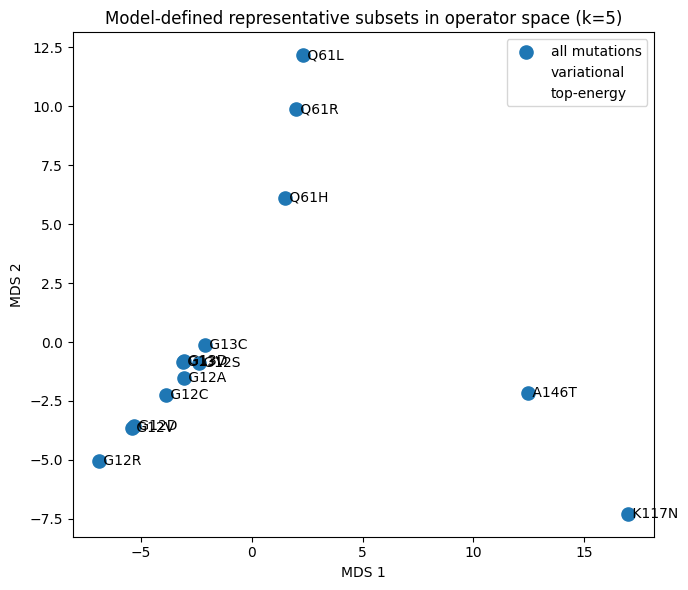

In [28]:
# MDS comparison of the two model-level selection criteria.
plt.figure(figsize=(7, 6))
plt.scatter(mds_coords[:, 0], mds_coords[:, 1], s=90, label="all mutations")

for i, name in enumerate(mutation_names):
    plt.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", va="center")

selection_masks = {
    "variational": exact_subset,
    "top-energy": top_subset,
}

markers = ["*", "^"]
for marker, (method, mask) in zip(markers, selection_masks.items()):
    idx = np.where(mask == 1)[0]
    plt.scatter(
        mds_coords[idx, 0],
        mds_coords[idx, 1],
        s=240,
        facecolors="none",
        linewidths=2,
        marker=marker,
        label=method,
    )

plt.xlabel("MDS 1")
plt.ylabel("MDS 2")
plt.title(f"Model-defined representative subsets in operator space (k={K_MAIN})")
plt.legend()
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "paper_mds_variational_vs_top_energy.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


## 13. Supplementary experiment — sensitivity to the diversity parameter

,k,mu,selected,V,D,J
0,4,0.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-1270.197187
1,4,0.01,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-1305.834368
2,4,0.10,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-1626.569004
3,4,0.50,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-3052.056270
4,4,1.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354
5,4,2.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-8397.633521
6,4,5.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-19088.788022
7,5,0.00,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1406.470127
8,5,0.01,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1456.898934
9,5,0.10,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-1912.699573


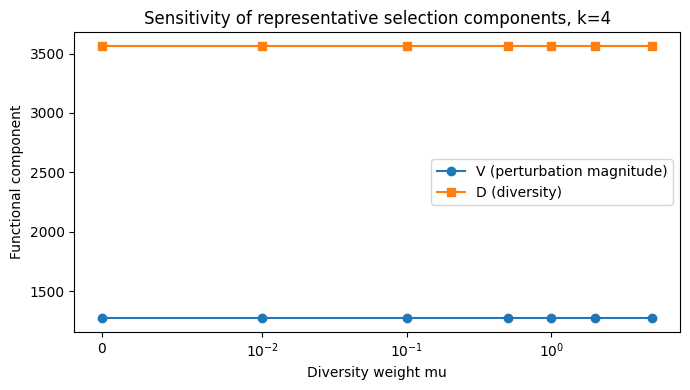

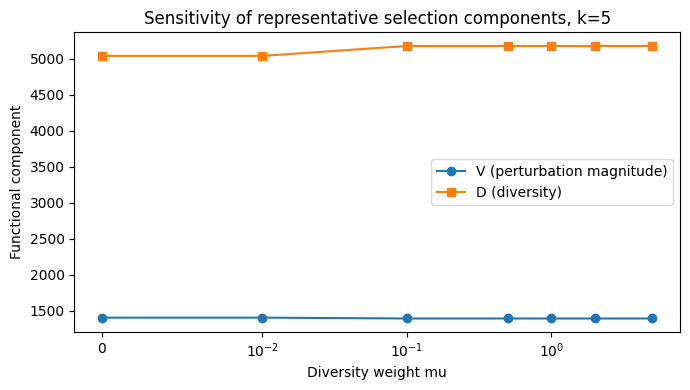

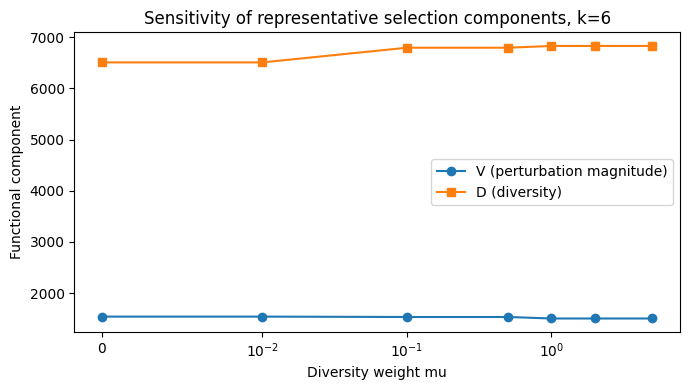

In [29]:
MU_VALUES = [0.0, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0]
K_SENS_VALUES = k_values

sensitivity_rows = []
for k in K_SENS_VALUES:
    for mu_value in MU_VALUES:
        exact = exact_variational_selection(k, V_vec, D_sq, mu=mu_value)
        sensitivity_rows.append({
            "k": k,
            "mu": mu_value,
            "selected": ", ".join(exact["selected"]),
            "V": exact["V"],
            "D": exact["D"],
            "J": exact["J"],
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df.to_csv(OUTPUT_DIR / "supplementary_mu_sensitivity.csv", index=False)
display(sensitivity_df)

for k in K_SENS_VALUES:
    sub = sensitivity_df[sensitivity_df["k"] == k]
    plt.figure(figsize=(7, 4))
    plt.plot(sub["mu"], sub["V"], marker="o", label="V (perturbation magnitude)")
    plt.plot(sub["mu"], sub["D"], marker="s", label="D (diversity)")
    plt.xscale("symlog", linthresh=0.01)
    plt.xlabel("Diversity weight mu")
    plt.ylabel("Functional component")
    plt.title(f"Sensitivity of representative selection components, k={k}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"supplementary_mu_sensitivity_k{k}.png", dpi=200)
    plt.show()


## Reviewer-driven robustness analysis — sensitivity to RIN construction

This analysis addresses the reviewer request to examine how the chosen RIN construction affects the results.

The main manuscript configuration is the **distance-weighted \(C_\alpha\) RIN with \(r_c=7\,\AA\)**. Robustness is evaluated by:

1. varying the contact cutoff to \(6\,\AA\) and \(8\,\AA\) while retaining distance weights;
2. replacing distance weights by a binary-contact weighting at \(7\,\AA\).

For every configuration, the complete mutation operator space is rebuilt from the same PDB structure and mutation panel. We then compare the operator-distance geometry and the exact representative subsets against the main \(7\,\AA\) distance-weighted configuration.

This is a sensitivity analysis, not a claim that the geometry is invariant to the RIN definition.


In [30]:
# ---------------------------------------------------------------------
# RIN construction sensitivity: helper
# ---------------------------------------------------------------------
from scipy.stats import pearsonr, spearmanr

RIN_SENSITIVITY_CONFIGS = [
    {"label": "distance_6A", "cutoff": 6.0, "weight_mode": "distance"},
    {"label": "distance_7A", "cutoff": 7.0, "weight_mode": "distance"},  # main manuscript configuration
    {"label": "distance_8A", "cutoff": 8.0, "weight_mode": "distance"},
    {"label": "binary_7A", "cutoff": 7.0, "weight_mode": "binary"},
]
RIN_SENSITIVITY_BASELINE = "distance_7A"


def compute_operator_space_for_rin_configuration(
    cutoff: float,
    weight_mode: str,
) -> dict:
    """Rebuild the complete mutation operator space for one RIN configuration."""
    G_cfg, coords_cfg, residue_numbers_cfg, pdb_file_cfg = build_rin_from_pdb(
        pdb_id=PDB_ID,
        chain_id=CHAIN_ID,
        distance_cutoff=cutoff,
        edge_weight_mode=weight_mode,
        pdb_dir=PDB_DIR,
    )

    L_cfg = weighted_laplacian(G_cfg)
    resnum_to_node_cfg = {
        data["residue_number"]: node
        for node, data in G_cfg.nodes(data=True)
    }

    deltas_cfg = {}
    V_cfg = np.zeros(N_mut, dtype=float)

    for idx, mutation in enumerate(mutation_specs):
        nodes = [
            resnum_to_node_cfg[r]
            for r in mutation["resnums"]
            if r in resnum_to_node_cfg
        ]

        if len(nodes) != len(mutation["resnums"]):
            raise ValueError(
                f"Configuration cutoff={cutoff}, mode={weight_mode} is missing "
                f"a residue required by mutation {mutation['name']}."
            )

        G_mut_cfg = apply_mutation_local_reweighting(
            G_cfg,
            nodes,
            alpha=mutation["alpha"],
            second_shell_factor=SECOND_SHELL_FACTOR,
        )
        delta_cfg = weighted_laplacian(G_mut_cfg) - L_cfg
        deltas_cfg[mutation["name"]] = delta_cfg
        V_cfg[idx] = hilbert_schmidt_norm(delta_cfg) ** 2

    D_hs_cfg = np.zeros((N_mut, N_mut), dtype=float)
    for i, name_i in enumerate(mutation_names):
        for j in range(i + 1, N_mut):
            name_j = mutation_names[j]
            d = hilbert_schmidt_norm(deltas_cfg[name_i] - deltas_cfg[name_j])
            D_hs_cfg[i, j] = d
            D_hs_cfg[j, i] = d

    D_cfg = D_hs_cfg ** 2

    return {
        "graph": G_cfg,
        "L": L_cfg,
        "V": V_cfg,
        "D_hs": D_hs_cfg,
        "D": D_cfg,
        "delta_laplacians": deltas_cfg,
        "n_nodes": G_cfg.number_of_nodes(),
        "n_edges": G_cfg.number_of_edges(),
        "density": nx.density(G_cfg),
        "cutoff": float(cutoff),
        "weight_mode": weight_mode,
    }


rin_sensitivity_results = {}
for cfg in RIN_SENSITIVITY_CONFIGS:
    print(f"Running {cfg['label']} ...")
    rin_sensitivity_results[cfg["label"]] = compute_operator_space_for_rin_configuration(
        cutoff=cfg["cutoff"],
        weight_mode=cfg["weight_mode"],
    )

baseline_rin = rin_sensitivity_results[RIN_SENSITIVITY_BASELINE]
print("RIN sensitivity configurations completed.")


Running distance_6A ...
Running distance_7A ...
Running distance_8A ...
Running binary_7A ...
RIN sensitivity configurations completed.


In [31]:
# ---------------------------------------------------------------------
# RIN construction sensitivity: geometry and selection stability
# ---------------------------------------------------------------------
upper = np.triu_indices(N_mut, k=1)
baseline_d = baseline_rin["D_hs"][upper]
baseline_V = baseline_rin["V"]

geometry_rows = []
selection_rows = []

baseline_selections = {
    k: exact_variational_selection(k, baseline_rin["V"], baseline_rin["D"], MU)
    for k in k_values
}

for cfg in RIN_SENSITIVITY_CONFIGS:
    label = cfg["label"]
    result = rin_sensitivity_results[label]
    d_cfg = result["D_hs"][upper]

    pearson_d = float(pearsonr(baseline_d, d_cfg).statistic)
    spearman_d = float(spearmanr(baseline_d, d_cfg).correlation)
    pearson_V = float(pearsonr(baseline_V, result["V"]).statistic)
    spearman_V = float(spearmanr(baseline_V, result["V"]).correlation)

    D0_norm = baseline_rin["D_hs"] / max(np.linalg.norm(baseline_rin["D_hs"]), 1e-12)
    D1_norm = result["D_hs"] / max(np.linalg.norm(result["D_hs"]), 1e-12)
    normalized_geometry_difference = float(np.linalg.norm(D1_norm - D0_norm))

    geometry_rows.append({
        "configuration": label,
        "cutoff_A": result["cutoff"],
        "weight_mode": result["weight_mode"],
        "n_nodes": result["n_nodes"],
        "n_edges": result["n_edges"],
        "graph_density": result["density"],
        "pearson_d_vs_baseline": pearson_d,
        "spearman_d_vs_baseline": spearman_d,
        "pearson_V_vs_baseline": pearson_V,
        "spearman_V_vs_baseline": spearman_V,
        "normalized_geometry_difference": normalized_geometry_difference,
    })

    for k in k_values:
        selected = exact_variational_selection(k, result["V"], result["D"], MU)
        baseline_selected = baseline_selections[k]

        selected_set = set(selected["selected"])
        baseline_set = set(baseline_selected["selected"])
        union = selected_set | baseline_set
        jaccard = len(selected_set & baseline_set) / len(union) if union else 1.0

        selection_rows.append({
            "configuration": label,
            "cutoff_A": result["cutoff"],
            "weight_mode": result["weight_mode"],
            "k": k,
            "mu": MU,
            "selected": ", ".join(selected["selected"]),
            "baseline_selected": ", ".join(baseline_selected["selected"]),
            "selection_jaccard_vs_baseline": jaccard,
            "V": selected["V"],
            "D": selected["D"],
            "J": selected["J"],
        })

rin_sensitivity_geometry_df = pd.DataFrame(geometry_rows)
rin_sensitivity_selection_df = pd.DataFrame(selection_rows)

rin_sensitivity_geometry_df.to_csv(
    OUTPUT_DIR / "reviewer_rin_sensitivity_geometry.csv",
    index=False,
)
rin_sensitivity_selection_df.to_csv(
    OUTPUT_DIR / "reviewer_rin_sensitivity_selection.csv",
    index=False,
)

display(rin_sensitivity_geometry_df)
display(rin_sensitivity_selection_df)


,configuration,cutoff_A,weight_mode,n_nodes,n_edges,graph_density,pearson_d_vs_baseline,spearman_d_vs_baseline,pearson_V_vs_baseline,spearman_V_vs_baseline,normalized_geometry_difference
0,distance_6A,6.0,distance,169,454,0.031981,0.976444,0.980443,0.905490,0.854945,0.103463
1,distance_7A,7.0,distance,169,666,0.046915,1.000000,1.000000,1.000000,1.000000,0.000000
2,distance_8A,8.0,distance,169,809,0.056988,0.968557,0.983803,0.887601,0.956044,0.123969
3,binary_7A,7.0,binary,169,666,0.046915,0.998458,0.997786,0.993466,0.995604,0.027653


,configuration,cutoff_A,weight_mode,k,mu,selected,baseline_selected,selection_jaccard_vs_baseline,V,D,J
0,distance_6A,6.0,distance,4,1.0,"G12R, G13V, K117N, A146T","G12R, Q61L, K117N, A146T",0.600000,463.886333,1300.570297,-1764.456630
1,distance_6A,6.0,distance,5,1.0,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",1.000000,493.983431,1884.845024,-2378.828455
2,distance_6A,6.0,distance,6,1.0,"G12V, G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T",0.714286,560.702476,2480.462515,-3041.164991
3,distance_7A,7.0,distance,4,1.0,"G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T",1.000000,1270.197187,3563.718167,-4833.915354
4,distance_7A,7.0,distance,5,1.0,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",1.000000,1394.667058,5180.325154,-6574.992212
5,distance_7A,7.0,distance,6,1.0,"G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T",1.000000,1501.562706,6831.761863,-8333.324568
6,distance_8A,8.0,distance,4,1.0,"G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T",1.000000,3687.145606,10368.008064,-14055.153670
7,distance_8A,8.0,distance,5,1.0,"G12V, G12R, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",0.666667,4300.037270,14871.114618,-19171.151888
8,distance_8A,8.0,distance,6,1.0,"G12V, G12R, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T",0.714286,4686.465043,20027.097095,-24713.562138
9,binary_7A,7.0,binary,4,1.0,"G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T",1.000000,43.904435,124.610984,-168.515419


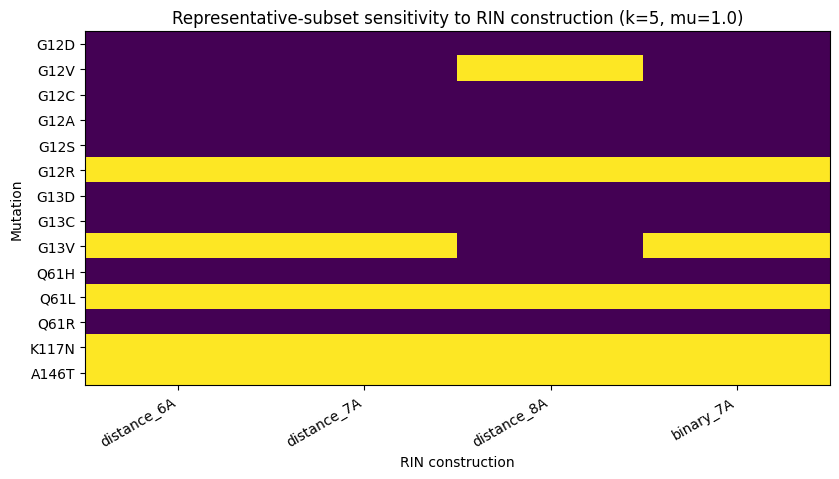

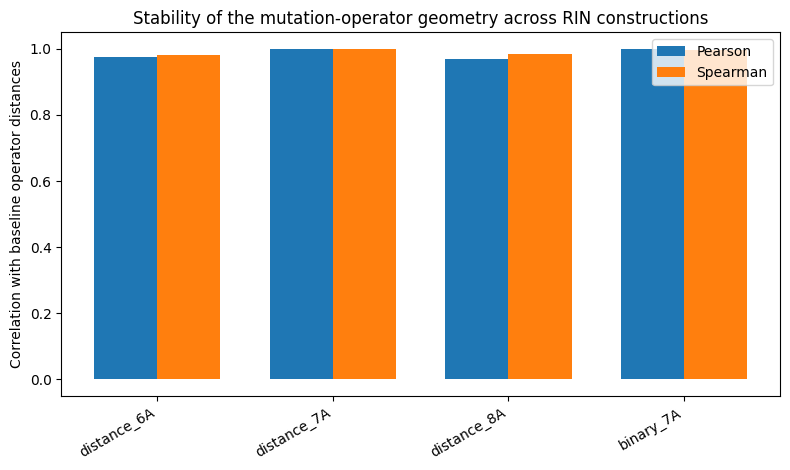

Saved reviewer-driven RIN sensitivity outputs:
 - kras_operator_space_v5_outputs/reviewer_rin_sensitivity_geometry.csv
 - kras_operator_space_v5_outputs/reviewer_rin_sensitivity_selection.csv
 - kras_operator_space_v5_outputs/reviewer_rin_sensitivity_selection_matrix.png
 - kras_operator_space_v5_outputs/reviewer_rin_sensitivity_geometry_correlations.png


In [32]:
# ---------------------------------------------------------------------
# RIN construction sensitivity: compact manuscript-ready figures
# ---------------------------------------------------------------------
K_RIN_SENS = K_MAIN
main_selection_df = rin_sensitivity_selection_df[
    rin_sensitivity_selection_df["k"] == K_RIN_SENS
].copy()

# Selection matrix across RIN configurations.
selection_matrix_rin = pd.DataFrame(
    0,
    index=mutation_names,
    columns=[cfg["label"] for cfg in RIN_SENSITIVITY_CONFIGS],
)

for _, row in main_selection_df.iterrows():
    selected_names = [s.strip() for s in row["selected"].split(",") if s.strip()]
    for name in selected_names:
        selection_matrix_rin.loc[name, row["configuration"]] = 1

fig, ax = plt.subplots(figsize=(8.5, max(4.5, 0.35 * N_mut)))
ax.imshow(selection_matrix_rin.values, aspect="auto")
ax.set_yticks(np.arange(N_mut))
ax.set_yticklabels(mutation_names)
ax.set_xticks(np.arange(selection_matrix_rin.shape[1]))
ax.set_xticklabels(selection_matrix_rin.columns, rotation=30, ha="right")
ax.set_xlabel("RIN construction")
ax.set_ylabel("Mutation")
ax.set_title(f"Representative-subset sensitivity to RIN construction (k={K_RIN_SENS}, mu={MU})")
plt.tight_layout()

selection_path = OUTPUT_DIR / "reviewer_rin_sensitivity_selection_matrix.png"
plt.savefig(selection_path, dpi=300, bbox_inches="tight")
plt.show()

# Geometry correlation relative to the main 7 Å distance-weighted RIN.
fig, ax = plt.subplots(figsize=(8.0, 4.8))
x = np.arange(len(rin_sensitivity_geometry_df))
width = 0.36

ax.bar(
    x - width / 2,
    rin_sensitivity_geometry_df["pearson_d_vs_baseline"],
    width,
    label="Pearson",
)
ax.bar(
    x + width / 2,
    rin_sensitivity_geometry_df["spearman_d_vs_baseline"],
    width,
    label="Spearman",
)
ax.set_xticks(x)
ax.set_xticklabels(rin_sensitivity_geometry_df["configuration"], rotation=30, ha="right")
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Correlation with baseline operator distances")
ax.set_title("Stability of the mutation-operator geometry across RIN constructions")
ax.legend()
plt.tight_layout()

correlation_path = OUTPUT_DIR / "reviewer_rin_sensitivity_geometry_correlations.png"
plt.savefig(correlation_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved reviewer-driven RIN sensitivity outputs:")
print(" -", OUTPUT_DIR / "reviewer_rin_sensitivity_geometry.csv")
print(" -", OUTPUT_DIR / "reviewer_rin_sensitivity_selection.csv")
print(" -", selection_path)
print(" -", correlation_path)


## 14. Experiment 6 — Geometry preservation in the Ising interaction graph

In [33]:
# ---------------------------------------------------------------------
# Experiment 6: exact geometry reconstruction from the Ising couplings
# ---------------------------------------------------------------------
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr, pearsonr

K_GEOM_HAM = K_QOPT if "K_QOPT" in globals() else min(3, N_mut)
LAMBDA_GEOM_HAM = (
    LAMBDA_QOPT
    if "LAMBDA_QOPT" in globals()
    else (1.05 * penalty_bound_B(V_vec, D_sq, MU) if penalty_bound_B(V_vec, D_sq, MU) > 0 else 1.0)
)

A_geom_ham = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_GEOM_HAM, K_GEOM_HAM)
ising_geom_coeffs = ising_coefficients_from_A(A_geom_ham, LAMBDA_GEOM_HAM, K_GEOM_HAM)
J_couplings = ising_geom_coeffs["J"].copy()

if MU <= 0:
    raise ValueError("MU must be positive to reconstruct distances from Ising couplings.")

# In the manuscript notation:
#   D_ij = d_ij^2 = ||Delta L_i - Delta L_j||_HS^2
#   J_ij = lambda/2 - mu/4 * D_ij
# therefore
#   D_ij = (4/mu) * (lambda/2 - J_ij).
D_sq_from_J = (4.0 / MU) * (LAMBDA_GEOM_HAM / 2.0 - J_couplings)
np.fill_diagonal(D_sq_from_J, 0.0)
D_sq_from_J = np.maximum(D_sq_from_J, 0.0)
D_from_J = np.sqrt(D_sq_from_J)

upper = np.triu_indices(N_mut, k=1)
D_sq_off = D_sq[upper]
D_hs_off = D_hs[upper]
J_off = J_couplings[upper]

spearman_Dsq_J = spearmanr(D_sq_off, J_off).correlation
pearson_Dsq_J = pearsonr(D_sq_off, J_off).statistic
spearman_reconstruction = spearmanr(D_sq_off, D_sq_from_J[upper]).correlation
pearson_reconstruction = pearsonr(D_sq_off, D_sq_from_J[upper]).statistic

geometry_hamiltonian_summary = pd.DataFrame([
    {
        "k": K_GEOM_HAM,
        "lambda": LAMBDA_GEOM_HAM,
        "mu": MU,
        "spearman_D_vs_J": spearman_Dsq_J,
        "pearson_D_vs_J": pearson_Dsq_J,
        "spearman_D_vs_reconstructed_D": spearman_reconstruction,
        "pearson_D_vs_reconstructed_D": pearson_reconstruction,
        "max_abs_D_reconstruction_error": float(np.max(np.abs(D_sq_from_J - D_sq))),
    }
])

geometry_hamiltonian_summary.to_csv(
    OUTPUT_DIR / "experiment_6_geometry_hamiltonian_summary.csv",
    index=False,
)
display(geometry_hamiltonian_summary)

print("Theory check:")
print("J_ij is an affine decreasing function of D_ij=d_ij^2.")
print("The D-vs-J correlations are therefore exactly -1 up to floating-point precision.")
print("The reconstructed D matrix should agree with the original D matrix up to numerical precision.")


,k,lambda,mu,spearman_D_vs_J,pearson_D_vs_J,spearman_D_vs_reconstructed_D,pearson_D_vs_reconstructed_D,max_abs_D_reconstruction_error
0,5,25389.536101,1.0,-1.0,-1.0,1.0,1.0,3.623768e-12


Theory check:
J_ij is an affine decreasing function of D_ij=d_ij^2.
The D-vs-J correlations are therefore exactly -1 up to floating-point precision.
The reconstructed D matrix should agree with the original D matrix up to numerical precision.


/tmp/ipykernel_5715/2033495814.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


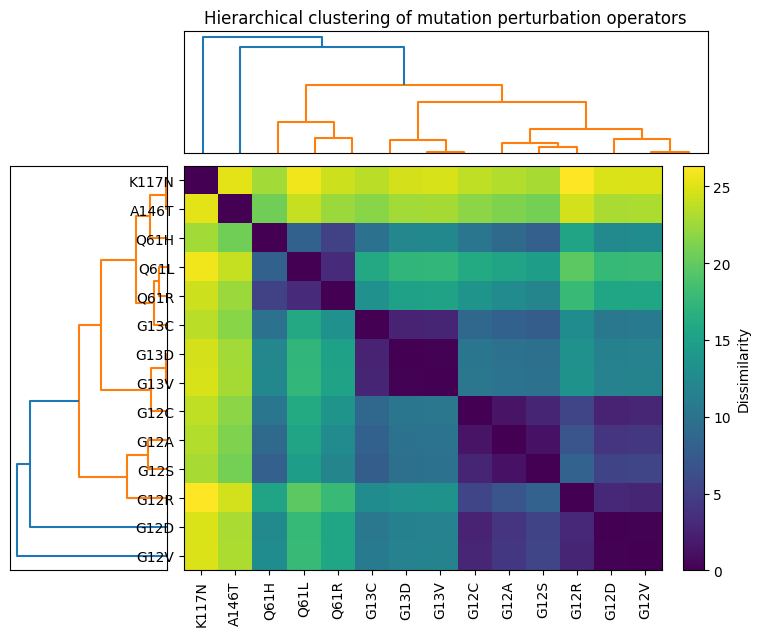

/tmp/ipykernel_5715/2033495814.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


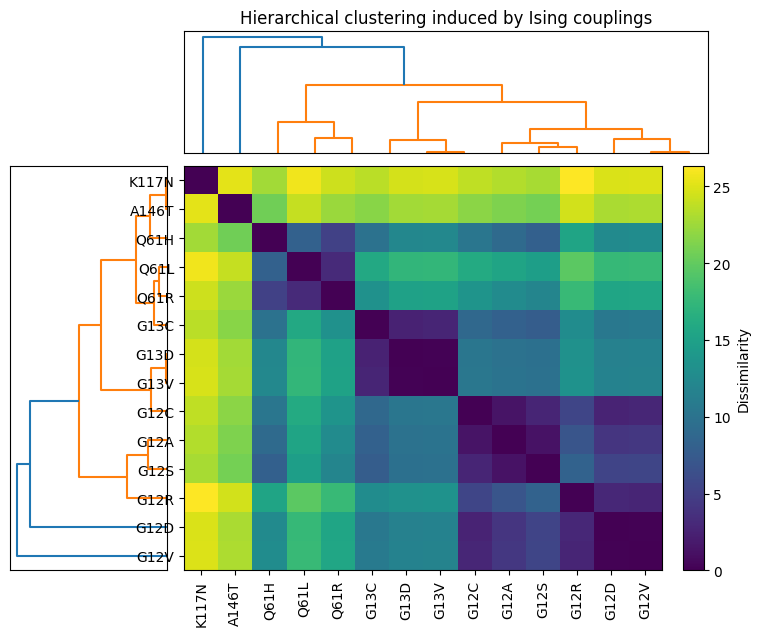

Saved: kras_operator_space_v5_outputs/experiment_6_dendrogram_heatmap_operator_distance.png
Saved: kras_operator_space_v5_outputs/experiment_6_dendrogram_heatmap_ising_couplings.png


In [34]:
# ---------------------------------------------------------------------
# Helper functions for clustered heatmaps and dendrograms
# ---------------------------------------------------------------------

from sklearn.metrics import silhouette_score


def select_cluster_count_by_silhouette(
    distance_matrix: np.ndarray,
    linkage_matrix: np.ndarray,
    min_clusters: int = 2,
    max_clusters: int = 8,
):
    """Select the number of hierarchical clusters using the precomputed-distance silhouette score."""
    n = distance_matrix.shape[0]
    upper_k = min(max_clusters, n - 1)

    rows = []
    best = None

    for k in range(min_clusters, upper_k + 1):
        labels = fcluster(linkage_matrix, t=k, criterion="maxclust")
        n_actual = len(np.unique(labels))
        if n_actual < 2 or n_actual >= n:
            continue

        score = float(silhouette_score(distance_matrix, labels, metric="precomputed"))
        row = {"requested_clusters": k, "actual_clusters": n_actual, "silhouette": score}
        rows.append(row)

        if best is None or score > best["silhouette"]:
            best = {**row, "labels": labels}

    diagnostics = pd.DataFrame(rows)
    if best is None:
        labels = np.ones(n, dtype=int)
        return 1, labels, diagnostics

    return int(best["actual_clusters"]), np.asarray(best["labels"], dtype=int), diagnostics


def safe_linkage_from_distance(distance_matrix: np.ndarray, method: str = "average"):
    """Return hierarchical linkage matrix from a symmetric distance matrix."""
    if distance_matrix.shape[0] < 2:
        return None
    condensed = squareform(distance_matrix, checks=False)
    return linkage(condensed, method=method)


def plot_dendrogram_heatmap(
    distance_matrix: np.ndarray,
    labels: list[str],
    title: str,
    filename: str,
    method: str = "average",
):
    """Plot a dendrogram and the distance matrix ordered by hierarchical clustering."""
    Z = safe_linkage_from_distance(distance_matrix, method=method)

    if Z is None:
        print("Not enough mutations for dendrogram.")
        return None

    order = leaves_list(Z)
    ordered_matrix = distance_matrix[np.ix_(order, order)]
    ordered_labels = [labels[i] for i in order]

    fig = plt.figure(figsize=(9, 7))
    gs = fig.add_gridspec(
        nrows=2,
        ncols=2,
        width_ratios=[1.2, 4.0],
        height_ratios=[1.2, 4.0],
        wspace=0.05,
        hspace=0.05,
    )

    ax_top = fig.add_subplot(gs[0, 1])
    dendrogram(Z, ax=ax_top, no_labels=True, color_threshold=None)
    ax_top.set_xticks([])
    ax_top.set_yticks([])
    ax_top.set_title(title)

    ax_left = fig.add_subplot(gs[1, 0])
    dendrogram(Z, ax=ax_left, orientation="left", no_labels=True, color_threshold=None)
    ax_left.set_xticks([])
    ax_left.set_yticks([])

    ax_heat = fig.add_subplot(gs[1, 1])
    im = ax_heat.imshow(ordered_matrix, aspect="auto")
    ax_heat.set_xticks(np.arange(len(ordered_labels)))
    ax_heat.set_yticks(np.arange(len(ordered_labels)))
    ax_heat.set_xticklabels(ordered_labels, rotation=90)
    ax_heat.set_yticklabels(ordered_labels)

    cbar = fig.colorbar(im, ax=ax_heat, fraction=0.046, pad=0.04)
    cbar.set_label("Dissimilarity")

    fig.tight_layout()
    out_path = OUTPUT_DIR / filename
    fig.savefig(out_path, dpi=250, bbox_inches="tight")
    plt.show()

    return {
        "linkage": Z,
        "order": order,
        "ordered_labels": ordered_labels,
        "path": out_path,
    }


# Clustered heatmap of the original operator geometry.
cluster_D = plot_dendrogram_heatmap(
    distance_matrix=D_hs,
    labels=mutation_names,
    title="Hierarchical clustering of mutation perturbation operators",
    filename="experiment_6_dendrogram_heatmap_operator_distance.png",
)

# Clustered heatmap of the Ising coupling-induced dissimilarity.
cluster_J = plot_dendrogram_heatmap(
    distance_matrix=D_from_J,
    labels=mutation_names,
    title="Hierarchical clustering induced by Ising couplings",
    filename="experiment_6_dendrogram_heatmap_ising_couplings.png",
)

if cluster_D is not None:
    print("Saved:", cluster_D["path"])
if cluster_J is not None:
    print("Saved:", cluster_J["path"])

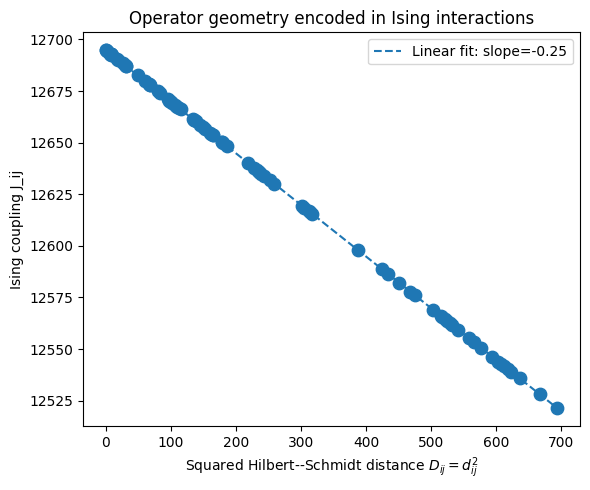

Saved: kras_operator_space_v5_outputs/experiment_6_distance_vs_ising_coupling.png
Spearman(D, J) = -1.000000
Pearson(D, J)  = -1.000000


In [35]:
# ---------------------------------------------------------------------
# Scatter plot: operator distances versus Ising couplings
# ---------------------------------------------------------------------
plt.figure(figsize=(6, 5))
plt.scatter(D_sq_off, J_off, s=80)

if len(D_sq_off) > 1:
    slope, intercept = np.polyfit(D_sq_off, J_off, deg=1)
    x_line = np.linspace(float(np.min(D_sq_off)), float(np.max(D_sq_off)), 100)
    y_line = slope * x_line + intercept
    plt.plot(x_line, y_line, linestyle="--", label=f"Linear fit: slope={slope:.3g}")

plt.xlabel("Squared Hilbert--Schmidt distance $D_{ij}=d_{ij}^2$")
plt.ylabel("Ising coupling J_ij")
plt.title("Operator geometry encoded in Ising interactions")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_6_distance_vs_ising_coupling.png"
plt.savefig(out_path, dpi=250)
plt.show()

print("Saved:", out_path)
print(f"Spearman(D, J) = {spearman_Dsq_J:.6f}")
print(f"Pearson(D, J)  = {pearson_Dsq_J:.6f}")

Silhouette-selected number of operator clusters: 5


,requested_clusters,actual_clusters,silhouette
0,2,2,0.478974
1,3,3,0.477191
2,4,4,0.451986
3,5,5,0.582639
4,6,6,0.520024
5,7,7,0.509745
6,8,8,0.437749


,mutation,cluster_operator_distance,hs_norm
9,Q61H,1,5.290656
10,Q61L,1,13.430102
11,Q61R,1,10.339035
7,G13C,2,8.460647
6,G13D,2,10.981945
8,G13V,2,11.156607
3,G12A,3,7.427498
2,G12C,3,8.852710
0,G12D,3,11.490845
5,G12R,3,14.396861


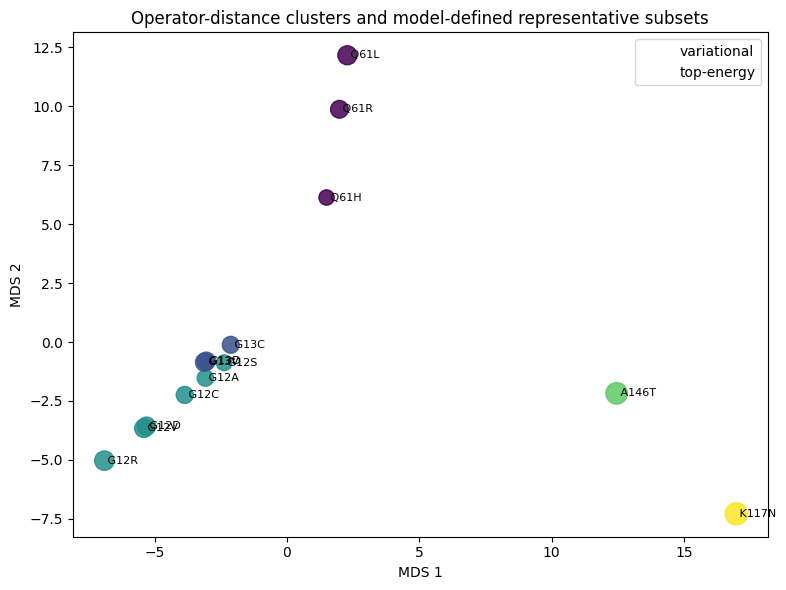

Saved: kras_operator_space_v5_outputs/paper_mds_clusters_and_model_selection.png


In [36]:
# ---------------------------------------------------------------------
# Data-driven cluster labels and representative subsets on the MDS embedding
# ---------------------------------------------------------------------
if cluster_D is not None and N_mut >= 3:
    N_CLUSTERS, cluster_labels, cluster_count_diagnostics_df = select_cluster_count_by_silhouette(
        D_hs,
        cluster_D["linkage"],
        min_clusters=2,
        max_clusters=min(8, N_mut - 1),
    )
else:
    N_CLUSTERS = 1
    cluster_labels = np.ones(N_mut, dtype=int)
    cluster_count_diagnostics_df = pd.DataFrame()

cluster_count_diagnostics_df.to_csv(
    OUTPUT_DIR / "experiment_6_cluster_count_silhouette.csv",
    index=False,
)

cluster_df = pd.DataFrame({
    "mutation": mutation_names,
    "cluster_operator_distance": cluster_labels,
    "hs_norm": np.sqrt(V_vec),
})
cluster_df.to_csv(OUTPUT_DIR / "experiment_6_operator_distance_clusters.csv", index=False)

print(f"Silhouette-selected number of operator clusters: {N_CLUSTERS}")
display(cluster_count_diagnostics_df)
display(cluster_df.sort_values(["cluster_operator_distance", "mutation"]))

selection_masks = {
    "variational": exact_subset if "exact_subset" in globals()
    else exact_variational_selection(K_GEOM_HAM, V_vec, D_sq, MU)["mask"],
    "top-energy": top_subset if "top_subset" in globals()
    else top_energy_baseline(K_GEOM_HAM, V_vec, D_sq, MU)["mask"],
}

plt.figure(figsize=(8, 6))
plt.scatter(
    mds_coords[:, 0],
    mds_coords[:, 1],
    s=80 + 8 * np.sqrt(V_vec),
    c=cluster_labels,
    alpha=0.85,
)

for i, name in enumerate(mutation_names):
    plt.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", va="center", fontsize=8)

marker_cycle = ["o", "s", "^", "D"]
for marker, (label, mask) in zip(marker_cycle, selection_masks.items()):
    idx = np.where(mask == 1)[0]
    plt.scatter(
        mds_coords[idx, 0],
        mds_coords[idx, 1],
        s=260,
        marker=marker,
        facecolors="none",
        linewidths=2,
        label=label,
    )

plt.xlabel("MDS 1")
plt.ylabel("MDS 2")
plt.title("Operator-distance clusters and model-defined representative subsets")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "paper_mds_clusters_and_model_selection.png"
plt.savefig(out_path, dpi=250)
plt.show()

print("Saved:", out_path)


,method,k,selected,covered_clusters,n_covered_clusters,total_clusters,cluster_coverage_ratio
0,variational,5,"G12R, G13V, Q61L, K117N, A146T","1, 2, 3, 4, 5",5,5,1.0
1,top-energy,5,"G12V, G12R, Q61L, K117N, A146T","1, 3, 4, 5",4,5,0.8


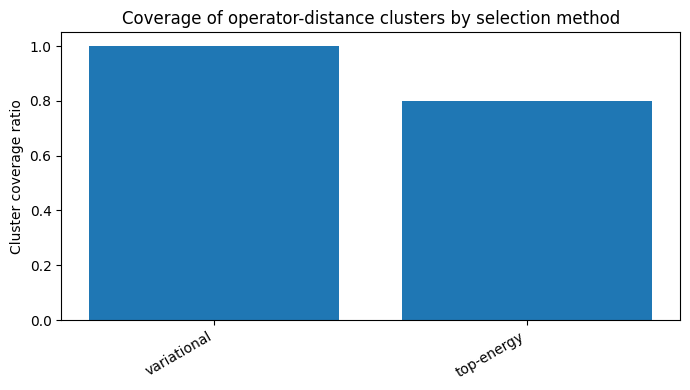

Saved: kras_operator_space_v5_outputs/experiment_6_cluster_coverage_ratio.png


In [37]:
# ---------------------------------------------------------------------
# Cluster coverage by representative subsets
# ---------------------------------------------------------------------
coverage_rows = []

for method, mask in selection_masks.items():
    selected_idx = np.where(mask == 1)[0]
    covered_clusters = sorted(set(cluster_labels[selected_idx]))
    coverage_rows.append({
        "method": method,
        "k": int(mask.sum()),
        "selected": ", ".join(names_from_mask(mask)),
        "covered_clusters": ", ".join(map(str, covered_clusters)),
        "n_covered_clusters": len(covered_clusters),
        "total_clusters": int(len(set(cluster_labels))),
        "cluster_coverage_ratio": len(covered_clusters) / max(1, len(set(cluster_labels))),
    })

cluster_coverage_df = pd.DataFrame(coverage_rows)
cluster_coverage_df.to_csv(
    OUTPUT_DIR / "experiment_6_cluster_coverage_by_method.csv",
    index=False,
)
display(cluster_coverage_df)

plt.figure(figsize=(7, 4))
plt.bar(cluster_coverage_df["method"], cluster_coverage_df["cluster_coverage_ratio"])
plt.ylim(0, 1.05)
plt.ylabel("Cluster coverage ratio")
plt.title("Coverage of operator-distance clusters by selection method")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_6_cluster_coverage_ratio.png"
plt.savefig(out_path, dpi=250)
plt.show()

print("Saved:", out_path)

## 15. Paper-ready geometry--Hamiltonian figures

/tmp/ipykernel_5715/264392979.py:87: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


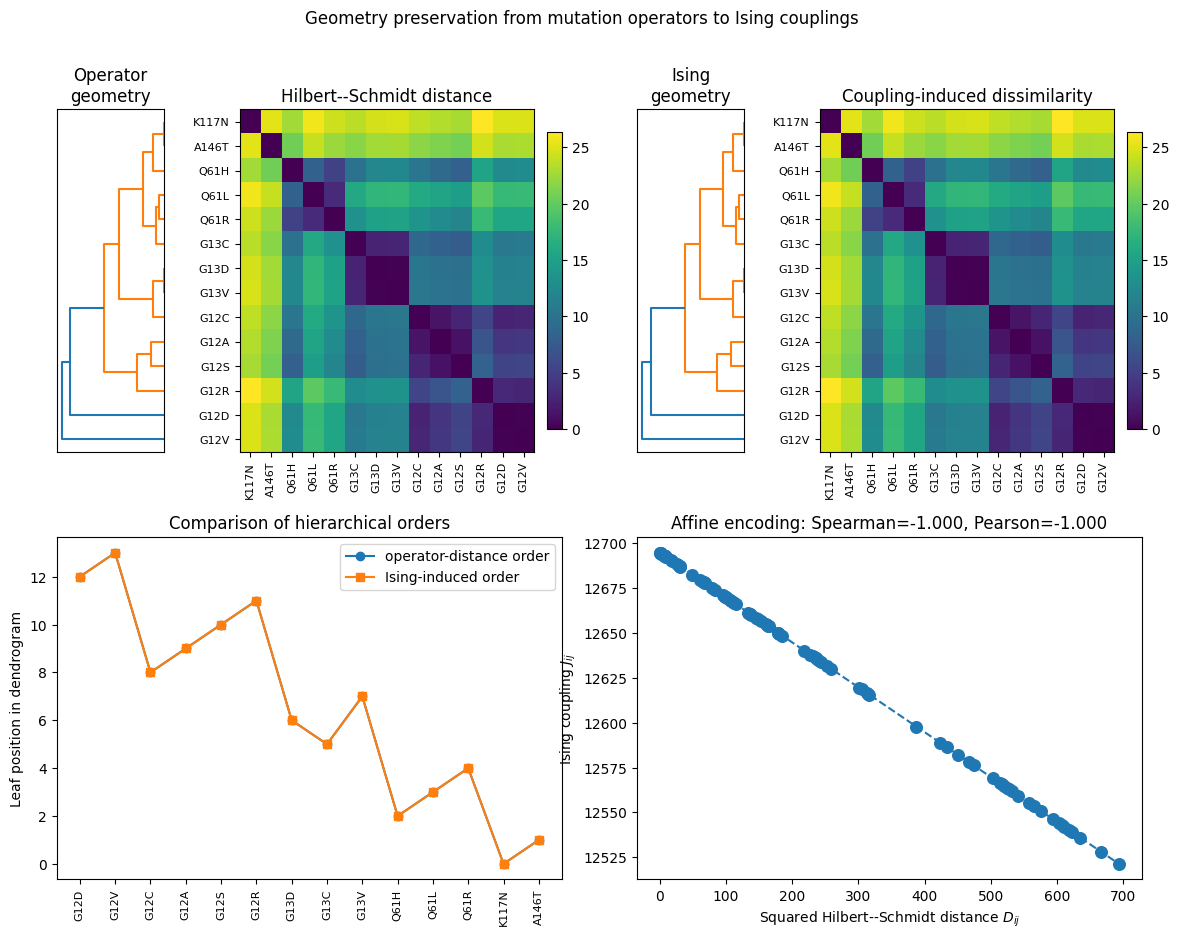

Saved: kras_operator_space_v5_outputs/experiment_7_geometry_hamiltonian_four_panel.png


In [38]:
# ---------------------------------------------------------------------
# Experiment 7A: four-panel comparison of operator geometry and Ising geometry
# ---------------------------------------------------------------------
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import squareform

# Build linkage objects if they are not already available from Experiment 6.
if 'cluster_D' in globals() and cluster_D is not None:
    Z_D = cluster_D['linkage']
    order_D = cluster_D['order']
else:
    Z_D = linkage(squareform(D_hs, checks=False), method='average')
    order_D = leaves_list(Z_D)

if 'cluster_J' in globals() and cluster_J is not None:
    Z_J = cluster_J['linkage']
    order_J = cluster_J['order']
else:
    Z_J = linkage(squareform(D_from_J, checks=False), method='average')
    order_J = leaves_list(Z_J)

ordered_D = D_hs[np.ix_(order_D, order_D)]
ordered_J = D_from_J[np.ix_(order_J, order_J)]
labels_D = [mutation_names[i] for i in order_D]
labels_J = [mutation_names[i] for i in order_J]

fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 4, width_ratios=[1.0, 3.0, 1.0, 3.0], wspace=0.35, hspace=0.25)

# Operator-distance dendrogram and heatmap
ax_dend_D = fig.add_subplot(gs[0, 0])
dendrogram(Z_D, ax=ax_dend_D, orientation='left', no_labels=True, color_threshold=None)
ax_dend_D.set_xticks([])
ax_dend_D.set_yticks([])
ax_dend_D.set_title('Operator\ngeometry')

ax_heat_D = fig.add_subplot(gs[0, 1])
im_D = ax_heat_D.imshow(ordered_D, aspect='auto')
ax_heat_D.set_xticks(np.arange(len(labels_D)))
ax_heat_D.set_yticks(np.arange(len(labels_D)))
ax_heat_D.set_xticklabels(labels_D, rotation=90, fontsize=8)
ax_heat_D.set_yticklabels(labels_D, fontsize=8)
ax_heat_D.set_title('Hilbert--Schmidt distance')
fig.colorbar(im_D, ax=ax_heat_D, fraction=0.046, pad=0.04)

# Ising-coupling dendrogram and heatmap
ax_dend_J = fig.add_subplot(gs[0, 2])
dendrogram(Z_J, ax=ax_dend_J, orientation='left', no_labels=True, color_threshold=None)
ax_dend_J.set_xticks([])
ax_dend_J.set_yticks([])
ax_dend_J.set_title('Ising\ngeometry')

ax_heat_J = fig.add_subplot(gs[0, 3])
im_J = ax_heat_J.imshow(ordered_J, aspect='auto')
ax_heat_J.set_xticks(np.arange(len(labels_J)))
ax_heat_J.set_yticks(np.arange(len(labels_J)))
ax_heat_J.set_xticklabels(labels_J, rotation=90, fontsize=8)
ax_heat_J.set_yticklabels(labels_J, fontsize=8)
ax_heat_J.set_title('Coupling-induced dissimilarity')
fig.colorbar(im_J, ax=ax_heat_J, fraction=0.046, pad=0.04)

# Lower panels: direct comparison of the two orders
ax_order = fig.add_subplot(gs[1, :2])
rank_D = {mutation_names[idx]: pos for pos, idx in enumerate(order_D)}
rank_J = {mutation_names[idx]: pos for pos, idx in enumerate(order_J)}
common_labels = mutation_names
x_pos = np.arange(len(common_labels))
ax_order.plot(x_pos, [rank_D[m] for m in common_labels], marker='o', label='operator-distance order')
ax_order.plot(x_pos, [rank_J[m] for m in common_labels], marker='s', label='Ising-induced order')
ax_order.set_xticks(x_pos)
ax_order.set_xticklabels(common_labels, rotation=90, fontsize=8)
ax_order.set_ylabel('Leaf position in dendrogram')
ax_order.set_title('Comparison of hierarchical orders')
ax_order.legend()

ax_scatter = fig.add_subplot(gs[1, 2:])
ax_scatter.scatter(D_sq_off, J_off, s=70)
if len(D_sq_off) > 1:
    slope, intercept = np.polyfit(D_sq_off, J_off, deg=1)
    x_line = np.linspace(float(np.min(D_sq_off)), float(np.max(D_sq_off)), 100)
    ax_scatter.plot(x_line, slope * x_line + intercept, linestyle='--')
ax_scatter.set_xlabel('Squared Hilbert--Schmidt distance $D_{ij}$')
ax_scatter.set_ylabel('Ising coupling $J_{ij}$')
ax_scatter.set_title(f'Affine encoding: Spearman={spearman_Dsq_J:.3f}, Pearson={pearson_Dsq_J:.3f}')

fig.suptitle('Geometry preservation from mutation operators to Ising couplings', y=0.98)
fig.tight_layout()
out_path = OUTPUT_DIR / 'experiment_7_geometry_hamiltonian_four_panel.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


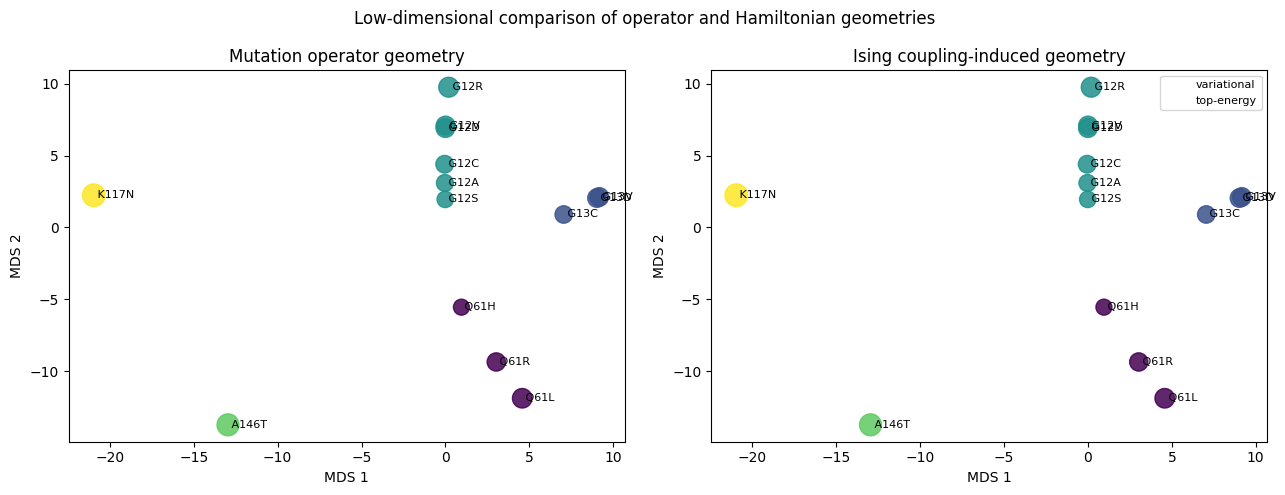

Saved: kras_operator_space_v5_outputs/experiment_7_mds_operator_vs_ising_geometry.png


In [39]:
# ---------------------------------------------------------------------
# Experiment 7B: side-by-side MDS embeddings of D and J-induced geometry
# ---------------------------------------------------------------------
from sklearn.manifold import MDS

mds_operator = MDS(n_components=2, dissimilarity='precomputed', random_state=RANDOM_SEED, normalized_stress='auto')
coords_D = mds_operator.fit_transform(D_hs)

mds_ising = MDS(n_components=2, dissimilarity='precomputed', random_state=RANDOM_SEED, normalized_stress='auto')
coords_J = mds_ising.fit_transform(D_from_J)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, coords, title in [
    (axes[0], coords_D, 'Mutation operator geometry'),
    (axes[1], coords_J, 'Ising coupling-induced geometry'),
]:
    sc = ax.scatter(coords[:, 0], coords[:, 1], s=90 + 8 * np.sqrt(V_vec), c=cluster_labels, alpha=0.85)
    for i, name in enumerate(mutation_names):
        ax.text(coords[i, 0], coords[i, 1], f' {name}', va='center', fontsize=8)
    for marker, (label, mask) in zip(['o', 's', '^', 'D'], selection_masks.items()):
        idx = np.where(mask == 1)[0]
        ax.scatter(coords[idx, 0], coords[idx, 1], s=260, marker=marker, facecolors='none', linewidths=2, label=label)
    ax.set_xlabel('MDS 1')
    ax.set_ylabel('MDS 2')
    ax.set_title(title)

axes[1].legend(loc='best', fontsize=8)
fig.suptitle('Low-dimensional comparison of operator and Hamiltonian geometries')
fig.tight_layout()
out_path = OUTPUT_DIR / 'experiment_7_mds_operator_vs_ising_geometry.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


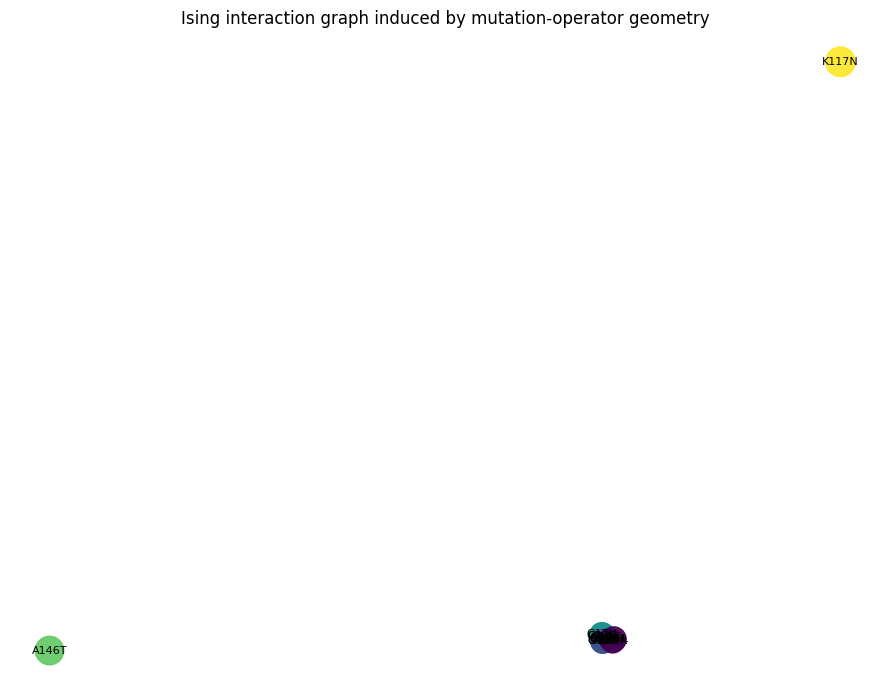

Saved: kras_operator_space_v5_outputs/experiment_7_ising_interaction_graph.png


,n_nodes,n_edges_shown,edge_threshold_abs_J,max_abs_J,min_abs_J
0,14,32,12668.061337,12694.760424,12521.301174


In [40]:
# ---------------------------------------------------------------------
# Experiment 7C: weighted Ising interaction graph
# ---------------------------------------------------------------------
# This graph represents the two-body part of the cost Hamiltonian. Nodes are
# mutations, edges are weighted by |J_ij|, and node colors are operator-distance clusters.

G_ising = nx.Graph()
for i, name in enumerate(mutation_names):
    G_ising.add_node(name, cluster=int(cluster_labels[i]), hs_norm=float(np.sqrt(V_vec[i])))

abs_J = np.abs(J_couplings)
upper_abs_J = abs_J[np.triu_indices(N_mut, k=1)]
threshold = np.quantile(upper_abs_J, 0.65) if len(upper_abs_J) > 0 else 0.0

for i in range(N_mut):
    for j in range(i + 1, N_mut):
        weight = float(abs_J[i, j])
        if weight >= threshold:
            G_ising.add_edge(mutation_names[i], mutation_names[j], weight=weight, signed_weight=float(J_couplings[i, j]))

pos = nx.spring_layout(G_ising, seed=RANDOM_SEED, weight='weight')
node_sizes = [120 + 15 * G_ising.nodes[n]['hs_norm'] for n in G_ising.nodes]
node_colors = [G_ising.nodes[n]['cluster'] for n in G_ising.nodes]
edge_widths = [0.8 + 3.0 * G_ising[u][v]['weight'] / max(threshold, 1e-12) for u, v in G_ising.edges]

plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(G_ising, pos, width=edge_widths, alpha=0.55)
nx.draw_networkx_nodes(G_ising, pos, node_size=node_sizes, node_color=node_colors, alpha=0.9)
nx.draw_networkx_labels(G_ising, pos, font_size=8)
plt.title('Ising interaction graph induced by mutation-operator geometry')
plt.axis('off')
plt.tight_layout()
out_path = OUTPUT_DIR / 'experiment_7_ising_interaction_graph.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)

ising_graph_summary = pd.DataFrame([
    {
        'n_nodes': G_ising.number_of_nodes(),
        'n_edges_shown': G_ising.number_of_edges(),
        'edge_threshold_abs_J': threshold,
        'max_abs_J': float(np.max(upper_abs_J)) if len(upper_abs_J) else np.nan,
        'min_abs_J': float(np.min(upper_abs_J)) if len(upper_abs_J) else np.nan,
    }
])
display(ising_graph_summary)
ising_graph_summary.to_csv(OUTPUT_DIR / 'experiment_7_ising_interaction_graph_summary.csv', index=False)


In [41]:
# ---------------------------------------------------------------------
# Experiment 7D: compact manuscript figure table
# ---------------------------------------------------------------------
figure_table = pd.DataFrame([
    {
        'figure': 'Fig. 1',
        'candidate_file': 'kras_rin_3d.png',
        'main_message': 'KRAS is converted into a residue interaction network and graph Laplacian.',
        'supports': 'Section 2 / Experiment 1',
    },
    {
        'figure': 'Fig. 2',
        'candidate_file': 'mutation_operator_distance_matrix.png + mutation_operator_gram_matrix.png',
        'main_message': 'Mutation perturbations form a nontrivial operator space with Hilbert--Schmidt geometry.',
        'supports': 'Sections 2.3 and 3.1 / Experiment 1',
    },
    {
        'figure': 'Fig. 3',
        'candidate_file': 'experiment_5_mds_representative_subsets.png',
        'main_message': 'The variational functional selects high-impact and geometrically diverse mutation representatives.',
        'supports': 'Section 3.1 / Experiment 2',
    },
    {
        'figure': 'Fig. 4',
        'candidate_file': 'experiment_3_qubo_ising_minima.png',
        'main_message': 'The variational, QUBO and Ising formulations are numerically equivalent.',
        'supports': 'Sections 3.2 and 3.3 / Experiment 3',
    },
    {
        'figure': 'Fig. 5',
        'candidate_file': 'experiment_7_geometry_hamiltonian_four_panel.png',
        'main_message': 'The geometry of mutation operators is encoded in the Ising coupling structure.',
        'supports': 'Section 3.3 / Experiment 6-7',
    },
    {
        'figure': 'Fig. 6',
        'candidate_file': 'experiment_4_optimization_gap.png',
        'main_message': 'Quantum/hybrid optimizers operate on the same cost Hamiltonian and approximate its optimum.',
        'supports': 'Section 3.4 / Experiment 4',
    },
])

figure_table.to_csv(OUTPUT_DIR / 'paper_candidate_figures_v7.csv', index=False)
display(figure_table)
print('Saved:', OUTPUT_DIR / 'paper_candidate_figures_v7.csv')


,figure,candidate_file,main_message,supports
0,Fig. 1,kras_rin_3d.png,KRAS is converted into a residue interaction n...,Section 2 / Experiment 1
1,Fig. 2,mutation_operator_distance_matrix.png + mutati...,Mutation perturbations form a nontrivial opera...,Sections 2.3 and 3.1 / Experiment 1
2,Fig. 3,experiment_5_mds_representative_subsets.png,The variational functional selects high-impact...,Section 3.1 / Experiment 2
3,Fig. 4,experiment_3_qubo_ising_minima.png,"The variational, QUBO and Ising formulations a...",Sections 3.2 and 3.3 / Experiment 3
4,Fig. 5,experiment_7_geometry_hamiltonian_four_panel.png,The geometry of mutation operators is encoded ...,Section 3.3 / Experiment 6-7
5,Fig. 6,experiment_4_optimization_gap.png,Quantum/hybrid optimizers operate on the same ...,Section 3.4 / Experiment 4


Saved: kras_operator_space_v5_outputs/paper_candidate_figures_v7.csv


## 16. Publication-grade hierarchical clustering visualizations


In [42]:
# ---------------------------------------------------------------------
# Experiment 8A: utilities for clearer clustering figures
# ---------------------------------------------------------------------
import re
from matplotlib.gridspec import GridSpec
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list, fcluster
from scipy.spatial.distance import squareform

# Use the operator-distance matrix already computed in the notebook.
# D_hs is the Hilbert--Schmidt distance between mutation perturbation operators.
# D_from_J is the distance-like representation induced by Ising couplings.

if 'D_hs' not in globals():
    D_hs = np.sqrt(D_sq)

if 'Z_D' not in globals():
    Z_D = linkage(squareform(D_hs, checks=False), method='average')

if 'order_D' not in globals():
    order_D = leaves_list(Z_D)

if 'D_from_J' in globals():
    if 'Z_J' not in globals():
        Z_J = linkage(squareform(D_from_J, checks=False), method='average')
    if 'order_J' not in globals():
        order_J = leaves_list(Z_J)
else:
    Z_J = None
    order_J = None

# Residue-site extraction from mutation names such as G12D, Q61L, A146T.
def mutation_site(name: str):
    match = re.search(r"(\d+)", str(name))
    return int(match.group(1)) if match else -1

mutation_sites = np.array([mutation_site(name) for name in mutation_names])
unique_sites = sorted(set(mutation_sites))

# Stable color assignment by residue position.
site_cmap = plt.cm.get_cmap('tab20', max(1, len(unique_sites)))
site_to_color = {site: site_cmap(i) for i, site in enumerate(unique_sites)}
mutation_label_colors = {name: site_to_color[site] for name, site in zip(mutation_names, mutation_sites)}

# Use the same data-driven cluster assignment selected in Experiment 6.
if "cluster_labels" in globals():
    cluster_labels_vis = np.asarray(cluster_labels, dtype=int)
    N_CLUSTER_VIS = len(np.unique(cluster_labels_vis))
else:
    N_CLUSTER_VIS, cluster_labels_vis, _ = select_cluster_count_by_silhouette(
        D_hs, Z_D, min_clusters=2, max_clusters=min(8, N_mut - 1)
    )

print('Mutation sites:', dict(zip(mutation_names, mutation_sites)))
print('Silhouette-selected number of visualization clusters:', N_CLUSTER_VIS)


Mutation sites: {'G12D': np.int64(12), 'G12V': np.int64(12), 'G12C': np.int64(12), 'G12A': np.int64(12), 'G12S': np.int64(12), 'G12R': np.int64(12), 'G13D': np.int64(13), 'G13C': np.int64(13), 'G13V': np.int64(13), 'Q61H': np.int64(61), 'Q61L': np.int64(61), 'Q61R': np.int64(61), 'K117N': np.int64(117), 'A146T': np.int64(146)}
Silhouette-selected number of visualization clusters: 5


/tmp/ipykernel_5715/2657055721.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  site_cmap = plt.cm.get_cmap('tab20', max(1, len(unique_sites)))


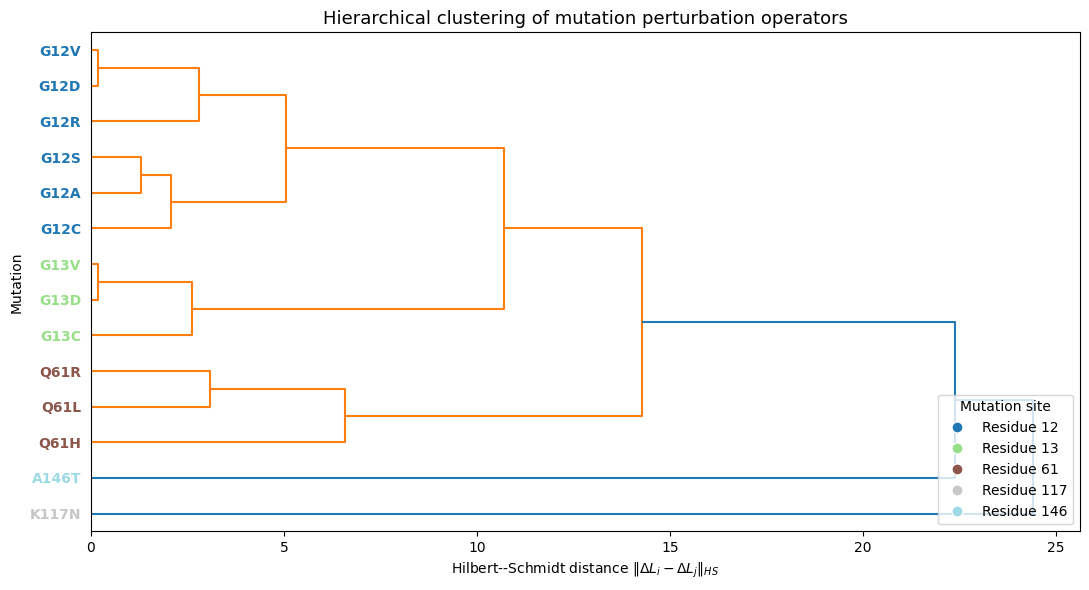

Saved: kras_operator_space_v5_outputs/experiment_8_readable_operator_dendrogram.png


In [43]:
# ---------------------------------------------------------------------
# Experiment 8B: readable horizontal dendrogram of mutation perturbation operators
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, max(6, 0.42 * N_mut)))

dendro = dendrogram(
    Z_D,
    labels=mutation_names,
    orientation='right',
    leaf_font_size=10,
    color_threshold=None,
    ax=ax,
)

ax.set_title('Hierarchical clustering of mutation perturbation operators', fontsize=13)
ax.set_xlabel(r'Hilbert--Schmidt distance $\|\Delta L_i-\Delta L_j\|_{HS}$')
ax.set_ylabel('Mutation')

# Color leaf labels by mutated residue position.
for tick in ax.get_yticklabels():
    label = tick.get_text()
    tick.set_color(mutation_label_colors.get(label, 'black'))
    tick.set_fontweight('bold')

# Add a compact legend for residue positions.
legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', label=f'Residue {site}',
               markerfacecolor=site_to_color[site], markersize=8)
    for site in unique_sites
]
ax.legend(handles=legend_handles, title='Mutation site', loc='lower right', frameon=True)

plt.tight_layout()
out_path = OUTPUT_DIR / 'experiment_8_readable_operator_dendrogram.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


/tmp/ipykernel_5715/1812653390.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cluster_cmap = plt.cm.get_cmap('tab10', max(1, len(set(cluster_labels_vis))))


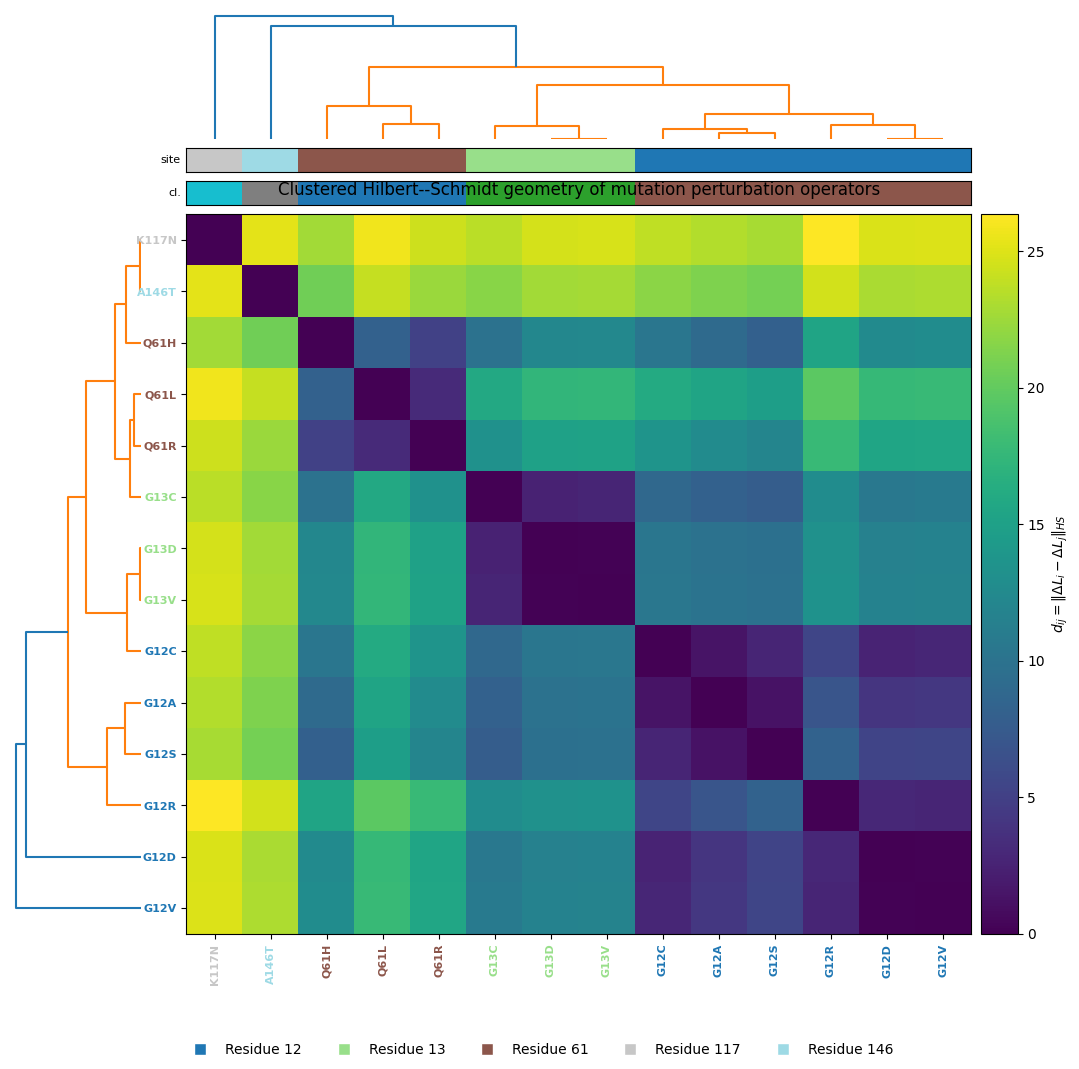

Saved: kras_operator_space_v5_outputs/experiment_8_clustered_heatmap_operator_distance_readable.png


In [44]:
# ---------------------------------------------------------------------
# Experiment 8C: publication-style clustered heatmap for operator distances
# ---------------------------------------------------------------------
def plot_clustered_heatmap(distance_matrix, linkage_matrix, order, title, output_name, cbar_label):
    ordered = distance_matrix[np.ix_(order, order)]
    labels = [mutation_names[i] for i in order]
    ordered_sites = mutation_sites[order]
    ordered_cluster_labels = cluster_labels_vis[order]

    fig = plt.figure(figsize=(13, 12))
    gs = GridSpec(
        4,
        4,
        figure=fig,
        width_ratios=[1.25, 0.25, 7.5, 0.35],
        height_ratios=[1.35, 0.25, 0.25, 7.5],
        wspace=0.04,
        hspace=0.04,
    )

    ax_top = fig.add_subplot(gs[0, 2])
    ax_left = fig.add_subplot(gs[3, 0])
    ax_site = fig.add_subplot(gs[1, 2])
    ax_cluster = fig.add_subplot(gs[2, 2])
    ax_heat = fig.add_subplot(gs[3, 2])
    ax_cbar = fig.add_subplot(gs[3, 3])

    dendrogram(linkage_matrix, ax=ax_top, no_labels=True, color_threshold=None)
    ax_top.axis('off')

    dendrogram(linkage_matrix, ax=ax_left, orientation='left', no_labels=True, color_threshold=None)
    ax_left.axis('off')

    # Residue-site color strip.
    site_rgb = np.array([site_to_color[site] for site in ordered_sites]).reshape(1, len(order), 4)
    ax_site.imshow(site_rgb, aspect='auto')
    ax_site.set_xticks([])
    ax_site.set_yticks([])
    ax_site.set_ylabel('site', rotation=0, ha='right', va='center', fontsize=8)

    # Cluster color strip.
    cluster_cmap = plt.cm.get_cmap('tab10', max(1, len(set(cluster_labels_vis))))
    cluster_rgb = np.array([cluster_cmap(int(c) - 1) for c in ordered_cluster_labels]).reshape(1, len(order), 4)
    ax_cluster.imshow(cluster_rgb, aspect='auto')
    ax_cluster.set_xticks([])
    ax_cluster.set_yticks([])
    ax_cluster.set_ylabel('cl.', rotation=0, ha='right', va='center', fontsize=8)

    im = ax_heat.imshow(ordered, aspect='auto')
    ax_heat.set_title(title, pad=14)
    ax_heat.set_xticks(np.arange(len(order)))
    ax_heat.set_yticks(np.arange(len(order)))
    ax_heat.set_xticklabels(labels, rotation=90, fontsize=8)
    ax_heat.set_yticklabels(labels, fontsize=8)

    for tick in ax_heat.get_xticklabels():
        tick.set_color(mutation_label_colors.get(tick.get_text(), 'black'))
        tick.set_fontweight('bold')
    for tick in ax_heat.get_yticklabels():
        tick.set_color(mutation_label_colors.get(tick.get_text(), 'black'))
        tick.set_fontweight('bold')

    cbar = fig.colorbar(im, cax=ax_cbar)
    cbar.set_label(cbar_label)

    # Residue-site legend below the plot.
    legend_handles = [
        plt.Line2D([0], [0], marker='s', color='w', label=f'Residue {site}',
                   markerfacecolor=site_to_color[site], markersize=8)
        for site in unique_sites
    ]
    fig.legend(handles=legend_handles, loc='lower center', ncol=min(len(unique_sites), 6), frameon=False)

    out_path = OUTPUT_DIR / output_name
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved:', out_path)

plot_clustered_heatmap(
    D_hs,
    Z_D,
    order_D,
    title='Clustered Hilbert--Schmidt geometry of mutation perturbation operators',
    output_name='experiment_8_clustered_heatmap_operator_distance_readable.png',
    cbar_label=r'$d_{ij}=\|\Delta L_i-\Delta L_j\|_{HS}$',
)


/tmp/ipykernel_5715/1812653390.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cluster_cmap = plt.cm.get_cmap('tab10', max(1, len(set(cluster_labels_vis))))


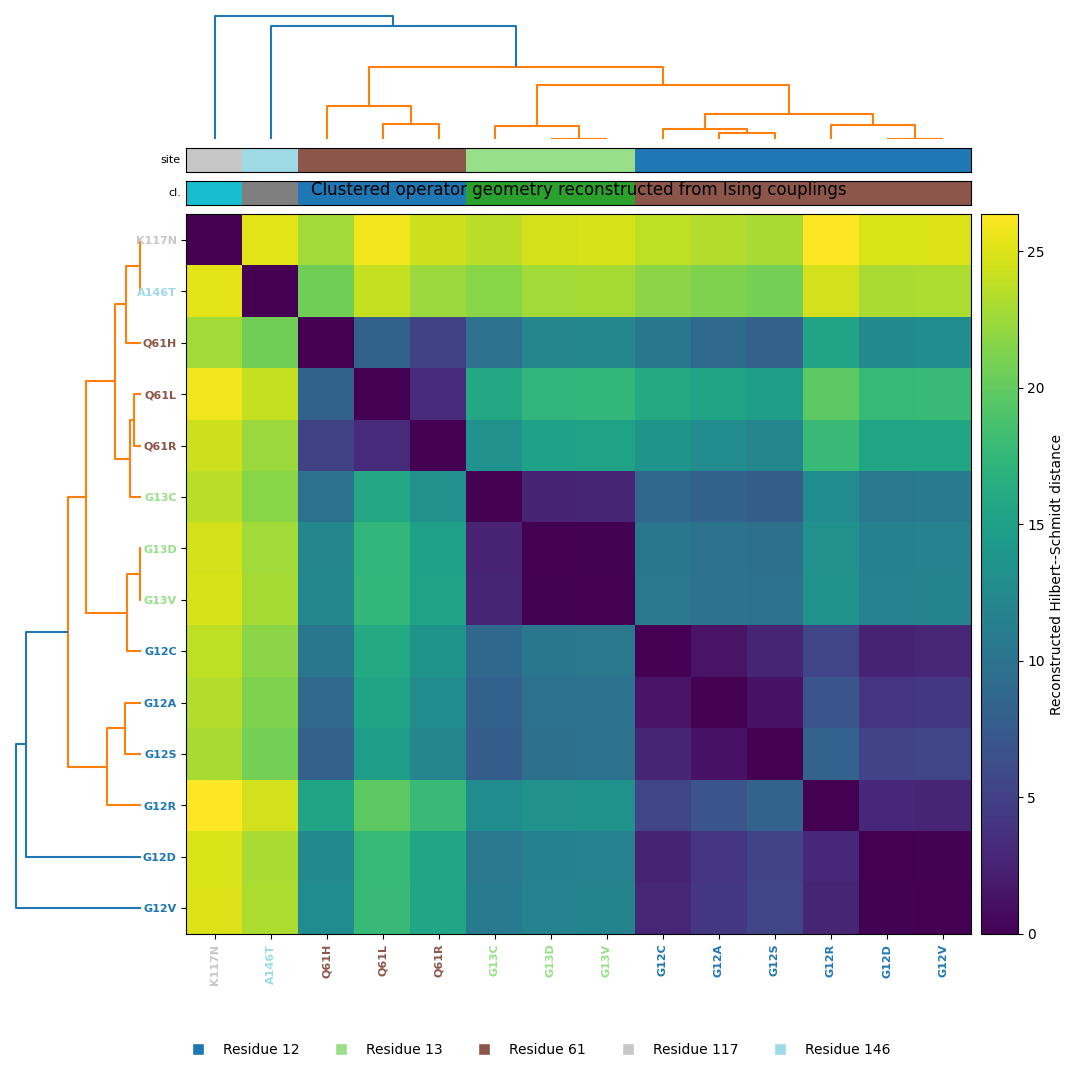

Saved: kras_operator_space_v5_outputs/experiment_8_clustered_heatmap_ising_geometry_readable.png


In [45]:
# ---------------------------------------------------------------------
# Experiment 8D: readable clustering view for the Ising-coupling-induced geometry
# ---------------------------------------------------------------------
if 'D_from_J' in globals() and Z_J is not None:
    # Reuse the same plotting function, now for the operator-distance matrix reconstructed exactly from the Ising couplings.
    plot_clustered_heatmap(
        D_from_J,
        Z_J,
        order_J,
        title='Clustered operator geometry reconstructed from Ising couplings',
        output_name='experiment_8_clustered_heatmap_ising_geometry_readable.png',
        cbar_label='Reconstructed Hilbert--Schmidt distance',
    )
else:
    print('D_from_J was not found. Run Experiment 6/7 before this cell.')


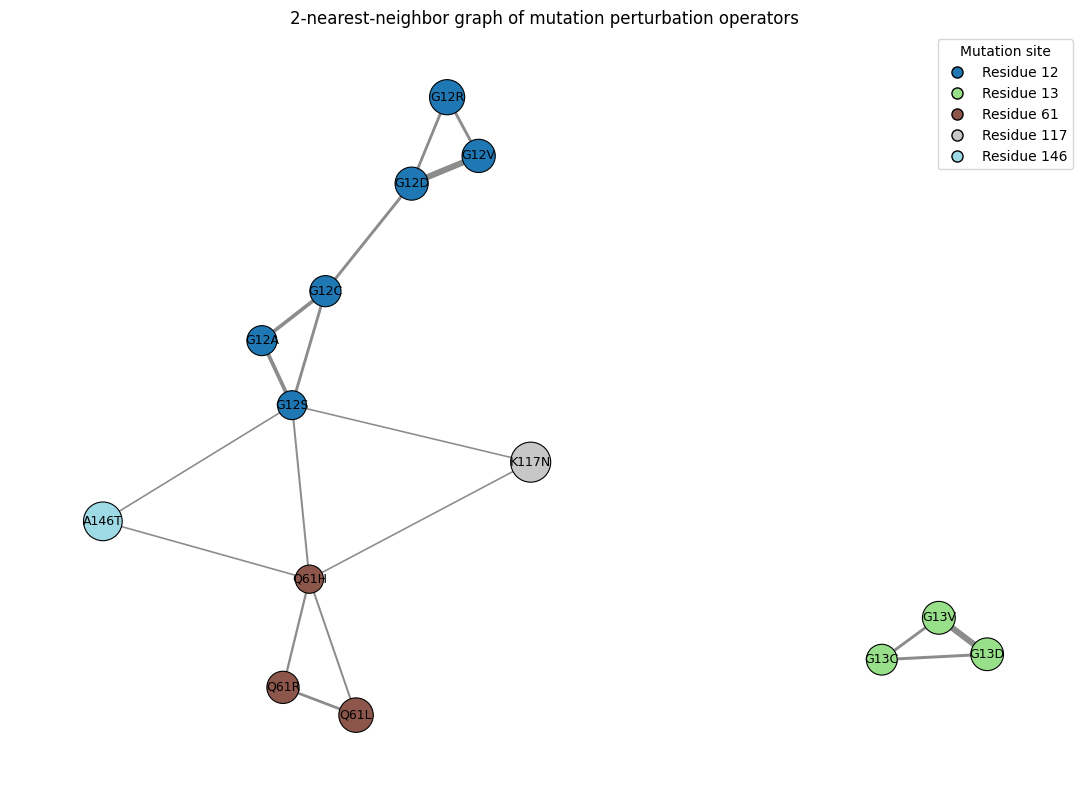

Saved: kras_operator_space_v5_outputs/experiment_8_operator_space_knn_graph.png


In [46]:
# ---------------------------------------------------------------------
# Experiment 8E: nearest-neighbor graph in the mutation operator space
# ---------------------------------------------------------------------
# The dendrogram is useful but can be visually dense. A k-nearest-neighbor graph gives
# a cleaner cluster-level summary of local relationships in the operator space.
K_NEIGHBORS = min(2, max(1, N_mut - 1))

G_knn = nx.Graph()
for i, name in enumerate(mutation_names):
    G_knn.add_node(name, site=int(mutation_sites[i]), cluster=int(cluster_labels_vis[i]), hs_norm=float(np.sqrt(V_vec[i])))

for i in range(N_mut):
    nearest = np.argsort(D_hs[i])[1:K_NEIGHBORS + 1]
    for j in nearest:
        weight = float(D_hs[i, j])
        similarity = 1.0 / (1.0 + weight)
        G_knn.add_edge(mutation_names[i], mutation_names[j], distance=weight, weight=similarity)

pos = nx.spring_layout(G_knn, seed=RANDOM_SEED, weight='weight')
node_colors = [site_to_color[G_knn.nodes[n]['site']] for n in G_knn.nodes()]
node_sizes = [280 + 25 * G_knn.nodes[n]['hs_norm'] for n in G_knn.nodes()]
edge_widths = [1.0 + 4.0 * G_knn[u][v]['weight'] for u, v in G_knn.edges()]

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G_knn, pos, ax=ax, width=edge_widths, alpha=0.45)
nx.draw_networkx_nodes(G_knn, pos, ax=ax, node_color=node_colors, node_size=node_sizes, edgecolors='black', linewidths=0.8)
nx.draw_networkx_labels(G_knn, pos, ax=ax, font_size=9)

ax.set_title(f'{K_NEIGHBORS}-nearest-neighbor graph of mutation perturbation operators')
ax.axis('off')

legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', label=f'Residue {site}',
               markerfacecolor=site_to_color[site], markeredgecolor='black', markersize=8)
    for site in unique_sites
]
ax.legend(handles=legend_handles, title='Mutation site', loc='best', frameon=True)

plt.tight_layout()
out_path = OUTPUT_DIR / 'experiment_8_operator_space_knn_graph.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


In [47]:
# ---------------------------------------------------------------------
# Experiment 8F: cluster summary table for the Results section
# ---------------------------------------------------------------------
cluster_summary_rows = []
for c in sorted(set(cluster_labels_vis)):
    idx = np.where(cluster_labels_vis == c)[0]
    cluster_summary_rows.append({
        'operator_cluster': int(c),
        'n_mutations': int(len(idx)),
        'mutations': ', '.join([mutation_names[i] for i in idx]),
        'mean_hs_norm': float(np.mean(np.sqrt(V_vec[idx]))),
        'mean_pairwise_distance': float(np.mean(D_hs[np.ix_(idx, idx)][np.triu_indices(len(idx), k=1)])) if len(idx) > 1 else 0.0,
    })

operator_cluster_summary_df = pd.DataFrame(cluster_summary_rows)
operator_cluster_summary_df.to_csv(OUTPUT_DIR / 'experiment_8_operator_cluster_summary.csv', index=False)
display(operator_cluster_summary_df)

print('Recommended manuscript figures from Experiment 8:')
print('1) experiment_8_readable_operator_dendrogram.png')
print('2) experiment_8_clustered_heatmap_operator_distance_readable.png')
print('3) experiment_8_clustered_heatmap_ising_geometry_readable.png')
print('4) experiment_8_operator_space_knn_graph.png')


,operator_cluster,n_mutations,mutations,mean_hs_norm,mean_pairwise_distance
0,1,3,"Q61H, Q61L, Q61R",9.686598,5.426297
1,2,3,"G13D, G13C, G13V",10.199733,1.797307
2,3,6,"G12D, G12V, G12C, G12A, G12S, G12R",9.996866,3.777490
3,4,1,A146T,19.898795,0.000000
4,5,1,K117N,22.058964,0.000000


Recommended manuscript figures from Experiment 8:
1) experiment_8_readable_operator_dendrogram.png
2) experiment_8_clustered_heatmap_operator_distance_readable.png
3) experiment_8_clustered_heatmap_ising_geometry_readable.png
4) experiment_8_operator_space_knn_graph.png


## 17. Experiment 9 — Degree-normalized perturbation-energy ablation

In [48]:

# ---------------------------------------------------------------------
# Experiment 9A: construct degree-normalized perturbation energies
# ---------------------------------------------------------------------
EPS_DEGREE = 1e-12

# Residue degree information from the wild-type RIN.
residue_degree_map = {
    int(row["residue_number"]): float(row["degree"])
    for _, row in residue_table.iterrows()
}
residue_weighted_degree_map = {
    int(row["residue_number"]): float(row["weighted_degree"])
    for _, row in residue_table.iterrows()
}

mutation_sites_ordered = []
mutation_degrees = []
mutation_weighted_degrees = []

for name in mutation_names:
    # Prefer metadata from operator_space_df, fall back to parsing the mutation label.
    if "site" in operator_space_df.columns:
        site = int(operator_space_df.loc[operator_space_df["mutation"] == name, "site"].iloc[0])
    else:
        site = mutation_site(name) if "mutation_site" in globals() else int("".join(ch for ch in name if ch.isdigit()))

    mutation_sites_ordered.append(site)
    mutation_degrees.append(residue_degree_map.get(site, np.nan))
    mutation_weighted_degrees.append(residue_weighted_degree_map.get(site, np.nan))

mutation_degrees = np.asarray(mutation_degrees, dtype=float)
mutation_weighted_degrees = np.asarray(mutation_weighted_degrees, dtype=float)

# Normalized alternatives. Weighted degree is the primary version because the RIN is weighted.
V_degree_normalized = V_vec / np.maximum(mutation_degrees, EPS_DEGREE)
V_weighted_degree_normalized = V_vec / np.maximum(mutation_weighted_degrees, EPS_DEGREE)

normalized_energy_df = pd.DataFrame({
    "mutation": mutation_names,
    "site": mutation_sites_ordered,
    "V_original": V_vec,
    "hs_norm": np.sqrt(V_vec),
    "degree": mutation_degrees,
    "weighted_degree": mutation_weighted_degrees,
    "V_degree_normalized": V_degree_normalized,
    "V_weighted_degree_normalized": V_weighted_degree_normalized,
})

normalized_energy_df.to_csv(OUTPUT_DIR / "experiment_9_degree_normalized_energies.csv", index=False)
display(normalized_energy_df.sort_values("V_weighted_degree_normalized", ascending=False))

print("Saved:", OUTPUT_DIR / "experiment_9_degree_normalized_energies.csv")


,mutation,site,V_original,hs_norm,degree,weighted_degree,V_degree_normalized,V_weighted_degree_normalized
5,G12R,12,207.269593,14.396861,4.0,19.842582,51.817398,10.445696
12,K117N,117,486.597913,22.058964,9.0,48.380297,54.066435,10.057770
10,Q61L,61,180.367635,13.430102,4.0,21.154934,45.091909,8.526032
1,G12V,12,136.272940,11.673600,4.0,19.842582,34.068235,6.867702
0,G12D,12,132.039525,11.490845,4.0,19.842582,33.009881,6.654352
8,G13V,13,124.469871,11.156607,4.0,19.374979,31.117468,6.424258
13,A146T,146,395.962046,19.898795,11.0,61.933582,35.996550,6.393334
6,G13D,13,120.603126,10.981945,4.0,19.374979,30.150782,6.224684
11,Q61R,61,106.895648,10.339035,4.0,21.154934,26.723912,5.052989
2,G12C,12,78.370481,8.852710,4.0,19.842582,19.592620,3.949611


Saved: kras_operator_space_v5_outputs/experiment_9_degree_normalized_energies.csv


In [49]:
# ---------------------------------------------------------------------
# Experiment 9B: repeat Experiment 2 with normalized perturbation energies
# ---------------------------------------------------------------------
def run_variational_selection_table(V_input: np.ndarray, label: str) -> pd.DataFrame:
    rows = []
    for k in k_values:
        exact = exact_variational_selection(k, V_input, D_sq, MU)
        top = top_energy_baseline(k, V_input, D_sq, MU)
        rnd = random_baseline(k, V_input, D_sq, MU, N_RANDOM_BASELINE)

        rows.append({
            "energy_model": label,
            "k": k,
            "method": "variational_exact",
            "selected": ", ".join(exact["selected"]),
            "V": exact["V"],
            "D": exact["D"],
            "J": exact["J"],
        })
        rows.append({
            "energy_model": label,
            "k": k,
            "method": "top_perturbation_energy",
            "selected": ", ".join(top["selected"]),
            "V": top["V"],
            "D": top["D"],
            "J": top["J"],
        })
        rows.append({
            "energy_model": label,
            "k": k,
            "method": "random_mean",
            "selected": "random subsets",
            "V": rnd["V_mean"],
            "D": rnd["D_mean"],
            "J": rnd["J_mean"],
            "V_std": rnd["V_std"],
            "D_std": rnd["D_std"],
            "J_std": rnd["J_std"],
        })

    return pd.DataFrame(rows)

experiment_9_original_df = run_variational_selection_table(V_vec, "original_total_perturbation")
experiment_9_degree_df = run_variational_selection_table(V_degree_normalized, "degree_normalized")
experiment_9_weighted_df = run_variational_selection_table(V_weighted_degree_normalized, "weighted_degree_normalized")

experiment_9_df = pd.concat(
    [experiment_9_original_df, experiment_9_degree_df, experiment_9_weighted_df],
    ignore_index=True,
)
experiment_9_df.to_csv(OUTPUT_DIR / "experiment_9_normalized_V_selection_results.csv", index=False)

display(experiment_9_df)
print("Saved:", OUTPUT_DIR / "experiment_9_normalized_V_selection_results.csv")


,energy_model,k,method,selected,V,D,J,V_std,D_std,J_std
0,original_total_perturbation,4,variational_exact,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
1,original_total_perturbation,4,top_perturbation_energy,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
2,original_total_perturbation,4,random_mean,random subsets,617.829325,1446.336043,-2064.165368,228.385208,800.226776,1019.202942
3,original_total_perturbation,5,variational_exact,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,NaN,NaN,NaN
4,original_total_perturbation,5,top_perturbation_energy,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,NaN,NaN,NaN
5,original_total_perturbation,5,random_mean,random subsets,782.681122,2464.140017,-3246.821139,244.176041,1110.472630,1346.020354
6,original_total_perturbation,6,variational_exact,"G12R, G13V, Q61L, Q61R, K117N, A146T",1501.562706,6831.761863,-8333.324568,NaN,NaN,NaN
7,original_total_perturbation,6,top_perturbation_energy,"G12D, G12V, G12R, Q61L, K117N, A146T",1538.509652,6510.405222,-8048.914874,NaN,NaN,NaN
8,original_total_perturbation,6,random_mean,random subsets,935.434201,3681.943778,-4617.377978,246.044177,1402.282311,1639.518803
9,degree_normalized,4,variational_exact,"G12R, Q61L, K117N, A146T",186.972291,3563.718167,-3750.690458,NaN,NaN,NaN


Saved: kras_operator_space_v5_outputs/experiment_9_normalized_V_selection_results.csv


,energy_model,method,k,selected,sites,mean_degree,mean_weighted_degree,V_model,D,J,V_original_total_of_selected
0,original_total_perturbation,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T","12, 13, 61, 117, 146",6.4,34.137275,1394.667058,5180.325154,-6574.992212,1394.667058
1,original_total_perturbation,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T","12, 12, 61, 117, 146",6.4,34.230795,1406.470127,5042.880729,-6449.350856,1406.470127
2,degree_normalized,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T","12, 13, 61, 117, 146",6.4,34.137275,218.089759,5180.325154,-5398.414913,1394.667058
3,degree_normalized,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T","12, 12, 61, 117, 146",6.4,34.230795,221.040526,5042.880729,-5263.921256,1406.470127
4,weighted_degree_normalized,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T","12, 13, 61, 117, 146",6.4,34.137275,41.847090,5180.325154,-5222.172245,1394.667058
5,weighted_degree_normalized,top_perturbation_energy,5,"G12D, G12V, G12R, Q61L, K117N","12, 12, 12, 61, 117",5.0,25.812595,42.551552,3634.920779,-3677.472331,1142.547606


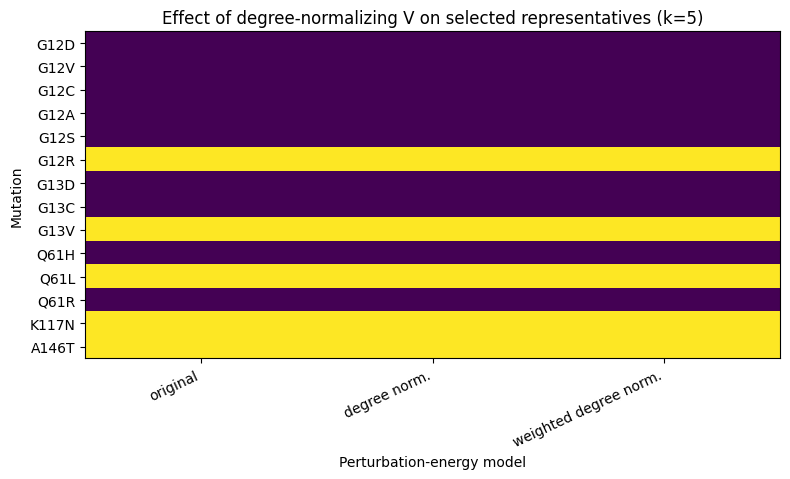

Saved: kras_operator_space_v5_outputs/experiment_9_selection_indicator_normalized_V.png


In [50]:
# ---------------------------------------------------------------------
# Experiment 9C: compare selected subsets under original and normalized V
# ---------------------------------------------------------------------
# Focus on the same k used for quantum optimization if available, otherwise use a robust default.
k_norm_plot = K_QOPT if "K_QOPT" in globals() else min(4, N_mut)

comparison_rows = []
for energy_label, V_input in [
    ("original_total_perturbation", V_vec),
    ("degree_normalized", V_degree_normalized),
    ("weighted_degree_normalized", V_weighted_degree_normalized),
]:
    exact = exact_variational_selection(k_norm_plot, V_input, D_sq, MU)
    top = top_energy_baseline(k_norm_plot, V_input, D_sq, MU)

    for method_label, result in [
        ("variational_exact", exact),
        ("top_perturbation_energy", top),
    ]:
        selected_idx = np.where(result["mask"] == 1)[0]
        comparison_rows.append({
            "energy_model": energy_label,
            "method": method_label,
            "k": k_norm_plot,
            "selected": ", ".join(result["selected"]),
            "sites": ", ".join(map(str, [mutation_sites_ordered[i] for i in selected_idx])),
            "mean_degree": float(np.mean(mutation_degrees[selected_idx])),
            "mean_weighted_degree": float(np.mean(mutation_weighted_degrees[selected_idx])),
            "V_model": result["V"],
            "D": result["D"],
            "J": result["J"],
            "V_original_total_of_selected": float(np.sum(V_vec[selected_idx])),
        })

experiment_9_comparison_df = pd.DataFrame(comparison_rows)
experiment_9_comparison_df.to_csv(OUTPUT_DIR / "experiment_9_selected_subsets_comparison.csv", index=False)
display(experiment_9_comparison_df)

# Bar chart: which mutations are selected under each energy model.
plot_rows = []
for _, row in experiment_9_comparison_df.iterrows():
    if row["method"] != "variational_exact":
        continue
    selected_names = [s.strip() for s in row["selected"].split(",") if s.strip()]
    for name in selected_names:
        plot_rows.append({"energy_model": row["energy_model"], "mutation": name, "selected": 1})

selection_indicator_df = pd.DataFrame(plot_rows)
models = ["original_total_perturbation", "degree_normalized", "weighted_degree_normalized"]
indicator = pd.DataFrame(0, index=mutation_names, columns=models)
for _, row in selection_indicator_df.iterrows():
    indicator.loc[row["mutation"], row["energy_model"]] = 1

plt.figure(figsize=(8, max(4, 0.35 * N_mut)))
plt.imshow(indicator.values, aspect="auto")
plt.yticks(np.arange(N_mut), mutation_names)
plt.xticks(np.arange(len(models)), ["original", "degree norm.", "weighted degree norm."], rotation=25, ha="right")
plt.xlabel("Perturbation-energy model")
plt.ylabel("Mutation")
plt.title(f"Effect of degree-normalizing V on selected representatives (k={k_norm_plot})")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_9_selection_indicator_normalized_V.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


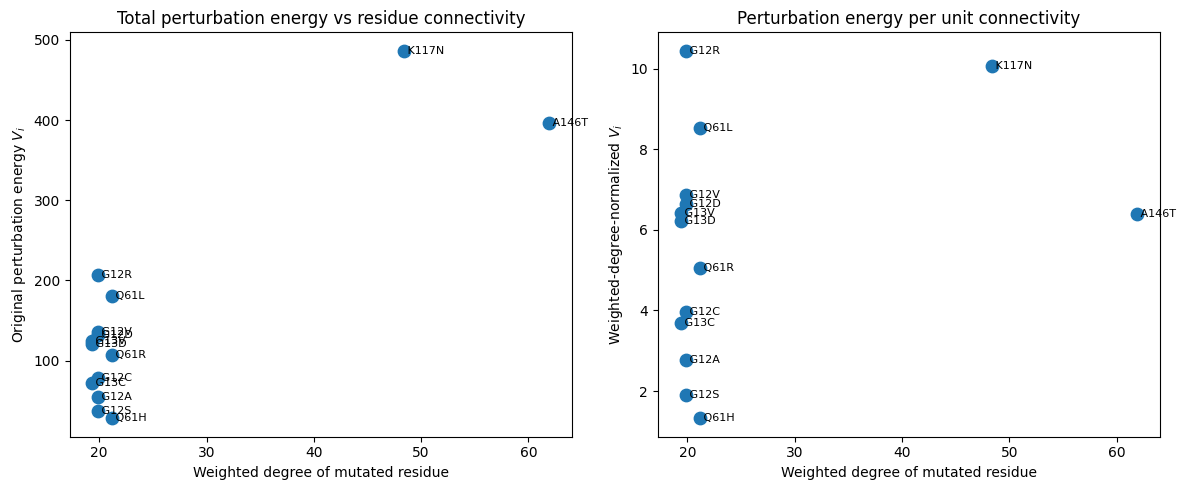

Saved: kras_operator_space_v5_outputs/experiment_9_V_vs_connectivity_ablation.png
Spearman(weighted degree, original V) = 0.364924
Spearman(weighted degree, weighted-normalized V) = 0.161675


In [51]:
# ---------------------------------------------------------------------
# Experiment 9D: V versus residue connectivity
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(mutation_weighted_degrees, V_vec, s=80)
for i, name in enumerate(mutation_names):
    axes[0].text(mutation_weighted_degrees[i], V_vec[i], f" {name}", fontsize=8, va="center")
axes[0].set_xlabel("Weighted degree of mutated residue")
axes[0].set_ylabel(r"Original perturbation energy $V_i$")
axes[0].set_title("Total perturbation energy vs residue connectivity")

axes[1].scatter(mutation_weighted_degrees, V_weighted_degree_normalized, s=80)
for i, name in enumerate(mutation_names):
    axes[1].text(mutation_weighted_degrees[i], V_weighted_degree_normalized[i], f" {name}", fontsize=8, va="center")
axes[1].set_xlabel("Weighted degree of mutated residue")
axes[1].set_ylabel(r"Weighted-degree-normalized $V_i$")
axes[1].set_title("Perturbation energy per unit connectivity")

plt.tight_layout()
out_path = OUTPUT_DIR / "experiment_9_V_vs_connectivity_ablation.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

if len(mutation_weighted_degrees) > 1:
    corr_orig = spearmanr(mutation_weighted_degrees, V_vec).correlation
    corr_norm = spearmanr(mutation_weighted_degrees, V_weighted_degree_normalized).correlation
    print(f"Spearman(weighted degree, original V) = {corr_orig:.6f}")
    print(f"Spearman(weighted degree, weighted-normalized V) = {corr_norm:.6f}")


## 18. Additional manuscript figures — geometry, Hamiltonian and robustness

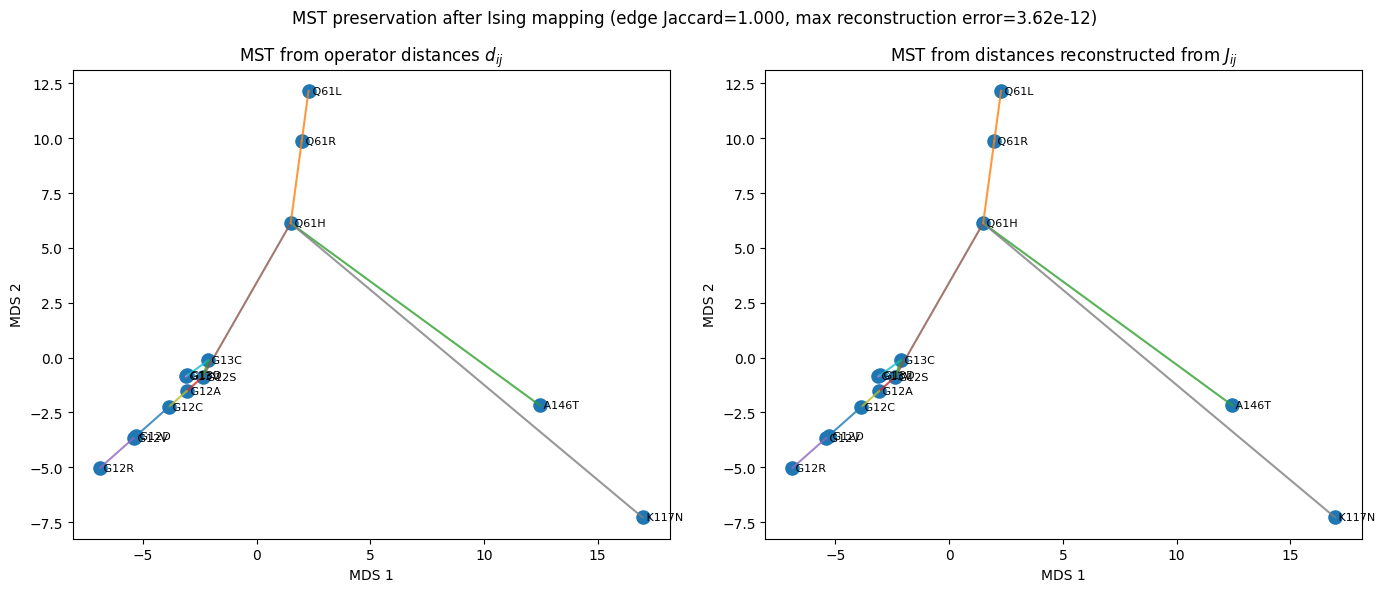

,metric,value
0,mst_edge_jaccard,1.000000e+00
1,n_edges_D,1.300000e+01
2,n_edges_J_reconstructed,1.300000e+01
3,n_common_edges,1.300000e+01
4,max_abs_error_Dsq_reconstruction,3.623768e-12
5,relative_error_Dsq_reconstruction,5.222565e-15


Saved: kras_operator_space_v5_outputs/experiment_10_mst_operator_vs_ising_reconstructed.png


In [52]:
# ---------------------------------------------------------------------
# Experiment 10A: MST(D) versus MST(J-reconstructed geometry)
# ---------------------------------------------------------------------
from scipy.sparse.csgraph import minimum_spanning_tree

# Use the same Hamiltonian coefficients already constructed for the geometry-preservation experiment.
K_GEOM_HAM = K_QOPT if "K_QOPT" in globals() else K_MAIN
LAMBDA_GEOM_HAM = LAMBDA_QOPT if "LAMBDA_QOPT" in globals() else 1.05 * penalty_bound_B(V_vec, D_sq, MU)

if "J_couplings" not in globals():
    A_geom_ham = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_GEOM_HAM, K_GEOM_HAM)
    ising_geom_coeffs = ising_coefficients_from_A(A_geom_ham, LAMBDA_GEOM_HAM, K_GEOM_HAM)
    J_couplings = ising_geom_coeffs["J"]

# The Ising couplings satisfy
#     J_ij = lambda/2 - mu/4 D_ij, where D_ij=d_ij^2.
# Therefore the squared operator distances can be reconstructed from the
# Hamiltonian couplings as
#     D_ij = (4/mu)(lambda/2 - J_ij).
# This is the correct distance-like object to compare against the operator geometry.
if MU <= 0:
    raise ValueError("MU must be positive to reconstruct distances from Ising couplings.")

D_sq_from_J = (4.0 / MU) * (LAMBDA_GEOM_HAM / 2.0 - J_couplings)
np.fill_diagonal(D_sq_from_J, 0.0)
D_sq_from_J = np.maximum(D_sq_from_J, 0.0)
D_from_J_hs = np.sqrt(D_sq_from_J)

D_for_mst = D_hs.copy()
np.fill_diagonal(D_for_mst, 0.0)

mst_D_sparse = minimum_spanning_tree(D_for_mst).toarray()
mst_J_sparse = minimum_spanning_tree(D_from_J_hs).toarray()

mst_D_edges = {
    tuple(sorted((i, j)))
    for i, j in zip(*np.where(mst_D_sparse > 0))
}
mst_J_edges = {
    tuple(sorted((i, j)))
    for i, j in zip(*np.where(mst_J_sparse > 0))
}

mst_jaccard = (
    len(mst_D_edges & mst_J_edges) / len(mst_D_edges | mst_J_edges)
    if len(mst_D_edges | mst_J_edges) > 0 else np.nan
)

reconstruction_max_abs_error = float(np.max(np.abs(D_sq - D_sq_from_J)))
reconstruction_rel_error = reconstruction_max_abs_error / max(float(np.max(np.abs(D_sq))), 1e-12)

def draw_mst(ax, edge_set, title):
    ax.scatter(mds_coords[:, 0], mds_coords[:, 1], s=90)
    for i, name in enumerate(mutation_names):
        ax.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", fontsize=8, va="center")
    for i, j in edge_set:
        ax.plot(
            [mds_coords[i, 0], mds_coords[j, 0]],
            [mds_coords[i, 1], mds_coords[j, 1]],
            linewidth=1.5,
            alpha=0.8,
        )
    ax.set_title(title)
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw_mst(axes[0], mst_D_edges, r"MST from operator distances $d_{ij}$")
draw_mst(axes[1], mst_J_edges, r"MST from distances reconstructed from $J_{ij}$")
fig.suptitle(
    f"MST preservation after Ising mapping "
    f"(edge Jaccard={mst_jaccard:.3f}, max reconstruction error={reconstruction_max_abs_error:.2e})"
)
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mst_operator_vs_ising_reconstructed.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

mst_summary_df = pd.DataFrame({
    "metric": [
        "mst_edge_jaccard",
        "n_edges_D",
        "n_edges_J_reconstructed",
        "n_common_edges",
        "max_abs_error_Dsq_reconstruction",
        "relative_error_Dsq_reconstruction",
    ],
    "value": [
        mst_jaccard,
        len(mst_D_edges),
        len(mst_J_edges),
        len(mst_D_edges & mst_J_edges),
        reconstruction_max_abs_error,
        reconstruction_rel_error,
    ],
})
mst_summary_df.to_csv(OUTPUT_DIR / "experiment_10_mst_summary.csv", index=False)
display(mst_summary_df)
print("Saved:", out_path)


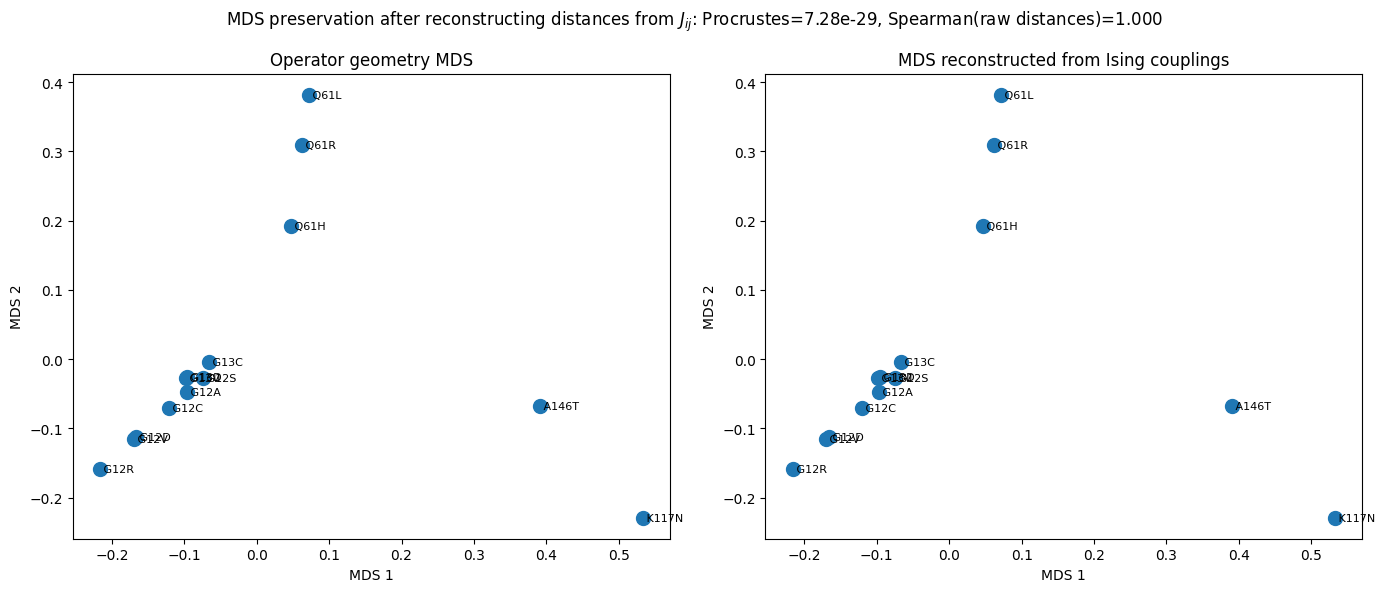

,metric,value
0,procrustes_disparity,7.284444e-29
1,pearson_embedding_distances,1.000000e+00
2,spearman_embedding_distances,1.000000e+00
3,pearson_raw_distances,1.000000e+00
4,spearman_raw_distances,1.000000e+00
5,max_abs_error_Dsq_reconstruction,3.623768e-12


Saved: kras_operator_space_v5_outputs/experiment_10_mds_operator_vs_ising_reconstructed.png


In [53]:
# ---------------------------------------------------------------------
# Experiment 10B: MDS(D) versus MDS(distance reconstructed from J)
# ---------------------------------------------------------------------
from scipy.spatial import procrustes
from scipy.stats import pearsonr, spearmanr
try:
    from sklearn.metrics import pairwise_distances
except Exception:
    pairwise_distances = None

# Use the true Hilbert--Schmidt distance reconstructed from the Hamiltonian couplings.
# This avoids treating J_ij itself as a distance, which would be conceptually incorrect.
D_from_J = D_from_J_hs.copy()

# Classical MDS is deterministic here and avoids extra dependencies.
coords_D_classical = classical_mds(D_hs, n_components=2)
coords_J_classical = classical_mds(D_from_J, n_components=2)

# Procrustes alignment quantifies whether both embeddings encode the same geometry.
mtx_D, mtx_J, procrustes_disparity = procrustes(coords_D_classical, coords_J_classical)

# Compare pairwise distances in both embeddings.
if pairwise_distances is not None:
    emb_D_dist = pairwise_distances(mtx_D)
    emb_J_dist = pairwise_distances(mtx_J)
else:
    emb_D_dist = squareform(pdist(mtx_D))
    emb_J_dist = squareform(pdist(mtx_J))

upper = np.triu_indices(N_mut, k=1)
pearson_emb = pearsonr(emb_D_dist[upper], emb_J_dist[upper]).statistic
spearman_emb = spearmanr(emb_D_dist[upper], emb_J_dist[upper]).correlation
pearson_raw = pearsonr(D_hs[upper], D_from_J[upper]).statistic
spearman_raw = spearmanr(D_hs[upper], D_from_J[upper]).correlation

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, coords_plot, title in [
    (axes[0], mtx_D, "Operator geometry MDS"),
    (axes[1], mtx_J, "MDS reconstructed from Ising couplings"),
]:
    ax.scatter(coords_plot[:, 0], coords_plot[:, 1], s=100)
    for i, name in enumerate(mutation_names):
        ax.text(coords_plot[i, 0], coords_plot[i, 1], f" {name}", fontsize=8, va="center")
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")
    ax.set_title(title)

fig.suptitle(
    f"MDS preservation after reconstructing distances from $J_{{ij}}$: "
    f"Procrustes={procrustes_disparity:.2e}, Spearman(raw distances)={spearman_raw:.3f}"
)
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mds_operator_vs_ising_reconstructed.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

mds_preservation_df = pd.DataFrame({
    "metric": [
        "procrustes_disparity",
        "pearson_embedding_distances",
        "spearman_embedding_distances",
        "pearson_raw_distances",
        "spearman_raw_distances",
        "max_abs_error_Dsq_reconstruction",
    ],
    "value": [
        procrustes_disparity,
        pearson_emb,
        spearman_emb,
        pearson_raw,
        spearman_raw,
        reconstruction_max_abs_error,
    ],
})
mds_preservation_df.to_csv(OUTPUT_DIR / "experiment_10_mds_preservation_summary.csv", index=False)
display(mds_preservation_df)
print("Saved:", out_path)


,method,k,V,D,J,selected
0,variational,5,1394.667058,5180.325154,-6574.992212,"G12R, G13V, Q61L, K117N, A146T"
1,top-energy,5,1406.470127,5042.880729,-6449.350856,"G12V, G12R, Q61L, K117N, A146T"


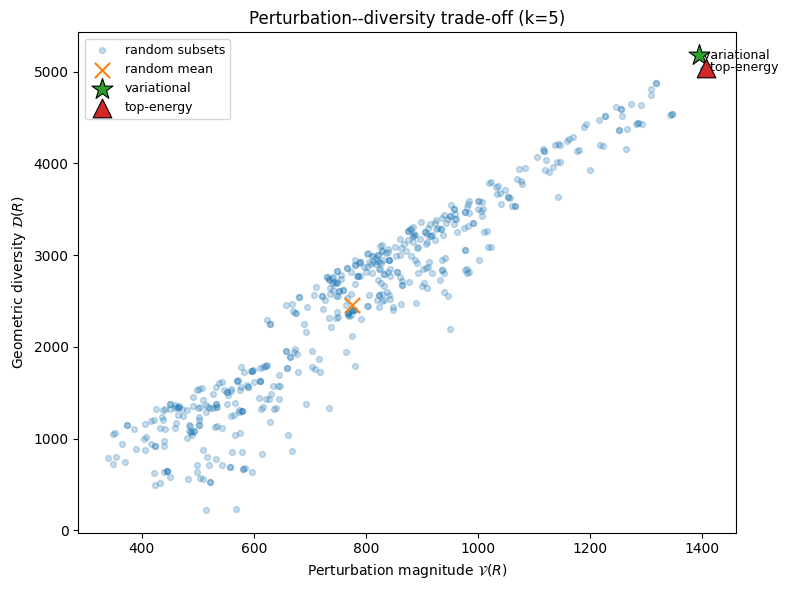

Saved: kras_operator_space_v5_outputs/paper_pareto_V_D_tradeoff.png


In [54]:
# ---------------------------------------------------------------------
# Experiment 10C: perturbation--diversity trade-off of the selection model
# ---------------------------------------------------------------------
K_PARETO = K_MAIN

exact_main = exact_variational_selection(K_PARETO, V_vec, D_sq, MU)
top_main = top_energy_baseline(K_PARETO, V_vec, D_sq, MU)

pareto_rows = []
for method_label, result in [
    ("variational", exact_main),
    ("top-energy", top_main),
]:
    pareto_rows.append({
        "method": method_label,
        "k": K_PARETO,
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selected": ", ".join(result["selected"]),
    })

# Random subset cloud provides context for the two model-level criteria.
rng = np.random.default_rng(RANDOM_SEED + 1000 + K_PARETO)
random_points = []
for _ in range(500):
    idx = tuple(rng.choice(N_mut, size=K_PARETO, replace=False))
    mask = mask_from_indices(idx, N_mut)
    random_points.append(variational_components(mask, V_vec, D_sq, MU))

random_df = pd.DataFrame(random_points)

pareto_summary_df = pd.DataFrame(pareto_rows)
pareto_summary_df.to_csv(
    OUTPUT_DIR / "paper_pareto_selection_summary.csv",
    index=False,
)
display(pareto_summary_df)

plt.figure(figsize=(8, 6))
plt.scatter(
    random_df["V"],
    random_df["D"],
    s=18,
    alpha=0.25,
    label="random subsets",
)
plt.scatter(
    [random_df["V"].mean()],
    [random_df["D"].mean()],
    s=120,
    marker="x",
    label="random mean",
)

for _, row in pareto_summary_df.iterrows():
    marker = "*" if row["method"] == "variational" else "^"
    size = 250 if row["method"] == "variational" else 180
    plt.scatter(
        row["V"],
        row["D"],
        s=size,
        marker=marker,
        label=row["method"],
        edgecolor="black",
        linewidth=0.8,
        zorder=5,
    )
    plt.text(
        row["V"],
        row["D"],
        f" {row['method']}",
        fontsize=9,
        va="center",
    )

plt.xlabel(r"Perturbation magnitude $\mathcal{V}(R)$")
plt.ylabel(r"Geometric diversity $\mathcal{D}(R)$")
plt.title(f"Perturbation--diversity trade-off (k={K_PARETO})")
plt.legend(fontsize=9)
plt.tight_layout()

out_path = OUTPUT_DIR / "paper_pareto_V_D_tradeoff.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


,mu,k,selected,V,D,J,selection_changed
0,0.00,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1406.470127,True
1,0.05,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1658.614164,False
2,0.10,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-1912.699573,True
3,0.25,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-2689.748346,False
4,0.50,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-3984.829635,False
5,1.00,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,False
6,2.00,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-11755.317366,False
7,5.00,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-27296.292828,False


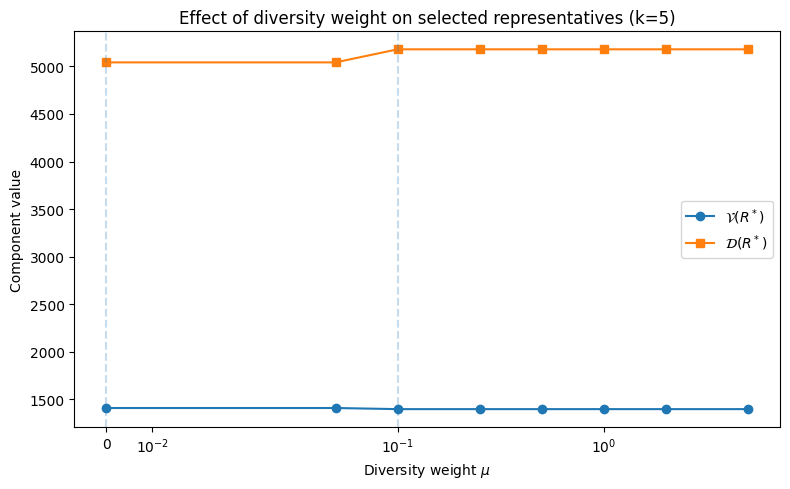

Saved: kras_operator_space_v5_outputs/experiment_10_mu_evolution_components_k_main.png


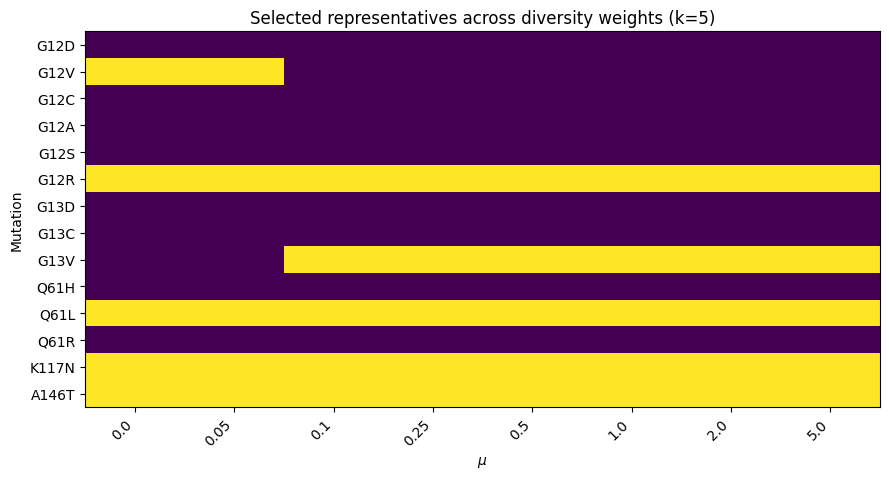

Saved: kras_operator_space_v5_outputs/experiment_10_mu_selection_matrix_k_main.png


In [55]:
# ---------------------------------------------------------------------
# Experiment 10D: evolution with the diversity parameter mu
# ---------------------------------------------------------------------
MU_GRID = np.array([0.0, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0], dtype=float)
K_MU = K_MAIN

mu_rows = []
prev_selection = None
for mu_value in MU_GRID:
    result = exact_variational_selection(K_MU, V_vec, D_sq, mu_value)
    selection_tuple = tuple(result["selected"])
    changed = selection_tuple != prev_selection
    prev_selection = selection_tuple

    mu_rows.append({
        "mu": mu_value,
        "k": K_MU,
        "selected": ", ".join(result["selected"]),
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selection_changed": changed,
    })

mu_sensitivity_df = pd.DataFrame(mu_rows)
mu_sensitivity_df.to_csv(OUTPUT_DIR / "experiment_10_mu_evolution_k_main.csv", index=False)
display(mu_sensitivity_df)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(mu_sensitivity_df["mu"], mu_sensitivity_df["V"], marker="o", label=r"$\mathcal{V}(R^*)$")
ax1.plot(mu_sensitivity_df["mu"], mu_sensitivity_df["D"], marker="s", label=r"$\mathcal{D}(R^*)$")
ax1.set_xscale("symlog", linthresh=0.05)
ax1.set_xlabel(r"Diversity weight $\mu$")
ax1.set_ylabel("Component value")
ax1.set_title(f"Effect of diversity weight on selected representatives (k={K_MU})")
for _, row in mu_sensitivity_df.iterrows():
    if row["selection_changed"]:
        ax1.axvline(row["mu"], linestyle="--", alpha=0.25)
ax1.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mu_evolution_components_k_main.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

# Compact mutation-selection matrix across mu values.
selection_matrix_mu = pd.DataFrame(0, index=mutation_names, columns=[str(mu) for mu in MU_GRID])
for _, row in mu_sensitivity_df.iterrows():
    selected_names = [s.strip() for s in row["selected"].split(",") if s.strip()]
    for name in selected_names:
        selection_matrix_mu.loc[name, str(row["mu"])] = 1

plt.figure(figsize=(9, max(4, 0.35 * N_mut)))
plt.imshow(selection_matrix_mu.values, aspect="auto")
plt.yticks(np.arange(N_mut), mutation_names)
plt.xticks(np.arange(len(MU_GRID)), [str(mu) for mu in MU_GRID], rotation=45, ha="right")
plt.xlabel(r"$\mu$")
plt.ylabel("Mutation")
plt.title(f"Selected representatives across diversity weights (k={K_MU})")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mu_selection_matrix_k_main.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


,quantity_pair,pearson,spearman
0,D_ij_vs_Ising_coupling,-1.000000,-1.000000
1,D_ij_vs_reconstructed_D_ij,1.000000,1.000000
2,operator_distance_vs_reconstructed_operator_di...,1.000000,1.000000
3,weighted_degree_vs_original_V,0.867222,0.364924
4,weighted_degree_vs_weighted_degree_normalized_V,0.311649,0.161675
5,HS_norm_vs_weighted_degree_normalized_V,0.812333,0.925275


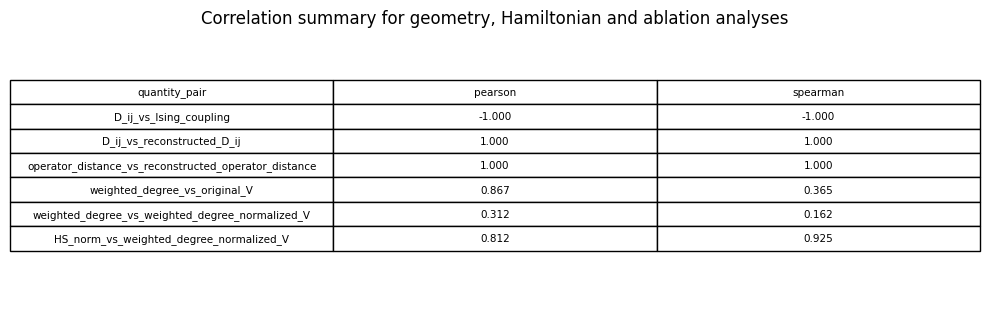

Saved: kras_operator_space_v5_outputs/experiment_10_correlation_summary_table.png


In [56]:
# ---------------------------------------------------------------------
# Experiment 10E: compact correlation summary table
# ---------------------------------------------------------------------
correlation_rows = []

def safe_corr(x, y, label):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    if np.sum(mask) < 2:
        return {"quantity_pair": label, "pearson": np.nan, "spearman": np.nan}
    return {
        "quantity_pair": label,
        "pearson": float(pearsonr(x[mask], y[mask]).statistic),
        "spearman": float(spearmanr(x[mask], y[mask]).correlation),
    }

upper = np.triu_indices(N_mut, k=1)
correlation_rows.append(safe_corr(D_sq[upper], J_couplings[upper], "D_ij_vs_Ising_coupling"))
correlation_rows.append(safe_corr(D_sq[upper], D_sq_from_J[upper], "D_ij_vs_reconstructed_D_ij"))
correlation_rows.append(safe_corr(D_hs[upper], D_from_J_hs[upper], "operator_distance_vs_reconstructed_operator_distance"))
correlation_rows.append(safe_corr(mutation_weighted_degrees, V_vec, "weighted_degree_vs_original_V"))
correlation_rows.append(safe_corr(mutation_weighted_degrees, V_weighted_degree_normalized, "weighted_degree_vs_weighted_degree_normalized_V"))
correlation_rows.append(safe_corr(np.sqrt(V_vec), V_weighted_degree_normalized, "HS_norm_vs_weighted_degree_normalized_V"))

correlation_summary_df = pd.DataFrame(correlation_rows)
correlation_summary_df.to_csv(OUTPUT_DIR / "experiment_10_correlation_summary.csv", index=False)
display(correlation_summary_df)

# Visual table figure.
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axis("off")
table_data = correlation_summary_df.copy()
table_data["pearson"] = table_data["pearson"].map(lambda v: f"{v:.3f}" if np.isfinite(v) else "nan")
table_data["spearman"] = table_data["spearman"].map(lambda v: f"{v:.3f}" if np.isfinite(v) else "nan")
tbl = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    loc="center",
    cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(7.5)
tbl.scale(1, 1.35)
plt.title("Correlation summary for geometry, Hamiltonian and ablation analyses")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_correlation_summary_table.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


In [57]:
# ---------------------------------------------------------------------
# Experiment 10F: optional Sankey-style cluster coverage summary
# ---------------------------------------------------------------------
# This cell uses Plotly if available. If Plotly is not installed, it falls back to a static cluster table.
try:
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except Exception:
    PLOTLY_AVAILABLE = False

K_SANKEY = K_MAIN
selection_for_sankey = {
    "variational": exact_variational_selection(K_SANKEY, V_vec, D_sq, MU)["mask"],
    "top-energy": top_energy_baseline(K_SANKEY, V_vec, D_sq, MU)["mask"],
}
if "cluster_labels_vis" in globals():
    cluster_labels_for_sankey = np.asarray(cluster_labels_vis)
elif "cluster_labels" in globals():
    cluster_labels_for_sankey = np.asarray(cluster_labels)
else:
    cluster_labels_for_sankey = np.ones(N_mut, dtype=int)

sankey_rows = []
for method, mask in selection_for_sankey.items():
    for i, name in enumerate(mutation_names):
        sankey_rows.append({
            "method": method,
            "mutation": name,
            "cluster": f"Cluster {int(cluster_labels_for_sankey[i])}",
            "selected": int(mask[i]),
        })

sankey_df = pd.DataFrame(sankey_rows)
sankey_df.to_csv(OUTPUT_DIR / "experiment_10_sankey_cluster_selection_data.csv", index=False)
display(sankey_df[sankey_df["selected"] == 1])

if PLOTLY_AVAILABLE:
    # Build a method -> cluster Sankey weighted by selected mutations.
    methods = list(selection_for_sankey.keys())
    clusters = sorted(sankey_df["cluster"].unique(), key=lambda s: int(s.split()[-1]))
    labels = methods + clusters
    label_index = {label: idx for idx, label in enumerate(labels)}

    source = []
    target = []
    value = []
    for method in methods:
        sub = sankey_df[(sankey_df["method"] == method) & (sankey_df["selected"] == 1)]
        counts = sub.groupby("cluster").size()
        for cluster, count in counts.items():
            source.append(label_index[method])
            target.append(label_index[cluster])
            value.append(int(count))

    fig = go.Figure(data=[go.Sankey(
        node=dict(label=labels, pad=18, thickness=18),
        link=dict(source=source, target=target, value=value),
    )])
    fig.update_layout(title_text=f"Cluster coverage by model-level selection criterion (k={K_SANKEY})", font_size=11)
    out_html = OUTPUT_DIR / "experiment_10_sankey_cluster_coverage.html"
    fig.write_html(str(out_html))
    fig.show()
    print("Saved:", out_html)
else:
    coverage_table = sankey_df[sankey_df["selected"] == 1].pivot_table(
        index="cluster", columns="method", values="mutation", aggfunc=lambda x: ", ".join(x), fill_value=""
    )
    display(coverage_table)
    coverage_table.to_csv(OUTPUT_DIR / "experiment_10_cluster_coverage_table.csv")
    print("Plotly not available. Saved static cluster coverage table instead.")


,method,mutation,cluster,selected
5,variational,G12R,Cluster 3,1
8,variational,G13V,Cluster 2,1
10,variational,Q61L,Cluster 1,1
12,variational,K117N,Cluster 5,1
13,variational,A146T,Cluster 4,1
15,top-energy,G12V,Cluster 3,1
19,top-energy,G12R,Cluster 3,1
24,top-energy,Q61L,Cluster 1,1
26,top-energy,K117N,Cluster 5,1
27,top-energy,A146T,Cluster 4,1


Saved: kras_operator_space_v5_outputs/experiment_10_sankey_cluster_coverage.html


In [58]:
# ---------------------------------------------------------------------
# Experiment 10G: final model-level representative-subset summary
# ---------------------------------------------------------------------
K_SUMMARY = K_MAIN

summary_rows = []

def add_selection_summary(method, mask):
    mask = np.asarray(mask, dtype=int)
    vals = variational_components(mask, V_vec, D_sq, MU)

    cluster_source = None
    if "cluster_labels_for_sankey" in globals():
        cluster_source = np.asarray(cluster_labels_for_sankey)
    elif "cluster_labels" in globals():
        cluster_source = np.asarray(cluster_labels)

    if cluster_source is not None:
        clusters_selected = sorted(
            set(int(cluster_source[i]) for i in np.where(mask == 1)[0])
        )
    else:
        clusters_selected = []

    summary_rows.append({
        "method": method,
        "k": int(mask.sum()),
        "selected": ", ".join(names_from_mask(mask)),
        "V": vals["V"],
        "D": vals["D"],
        "J": vals["J"],
        "n_clusters_covered": len(clusters_selected),
        "clusters_covered": ", ".join(map(str, clusters_selected)),
    })

add_selection_summary(
    "variational_exact",
    exact_variational_selection(K_SUMMARY, V_vec, D_sq, MU)["mask"],
)
add_selection_summary(
    "top_perturbation_energy",
    top_energy_baseline(K_SUMMARY, V_vec, D_sq, MU)["mask"],
)

final_selection_summary_df = pd.DataFrame(summary_rows)
final_selection_summary_df.to_csv(
    OUTPUT_DIR / "paper_main_selection_summary.csv",
    index=False,
)
display(final_selection_summary_df)


,method,k,selected,V,D,J,n_clusters_covered,clusters_covered
0,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,5,"1, 2, 3, 4, 5"
1,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,4,"1, 3, 4, 5"


### Experiment 12: operator geometry, Hamiltonian couplings, and reconstructed geometry

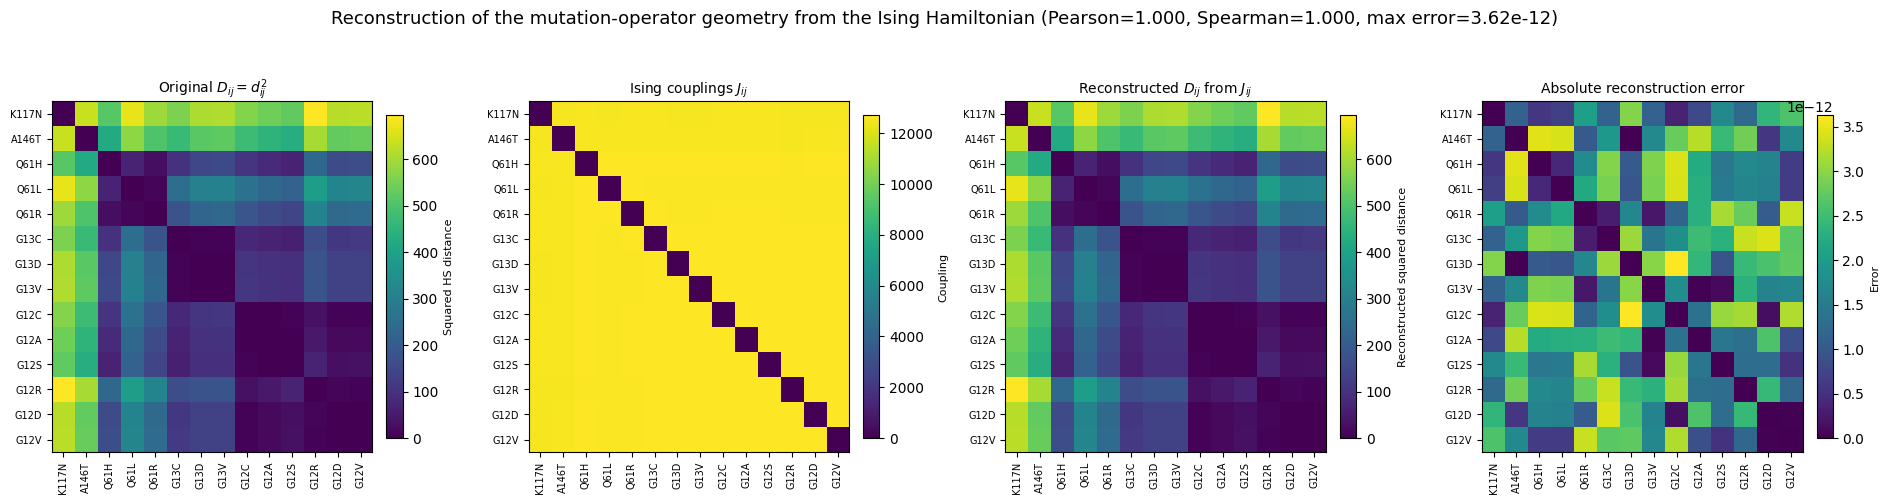

Saved: kras_operator_space_v5_outputs/experiment_12_geometry_hamiltonian_reconstruction.png


,k,lambda,mu,pearson_Dsq_vs_reconstructed_Dsq,spearman_Dsq_vs_reconstructed_Dsq,max_abs_error_Dsq,max_abs_error_Dhs
0,5,25389.536101,1.0,1.0,1.0,3.623768e-12,8.549689e-12


In [59]:
# ---------------------------------------------------------------------
# Experiment 12: operator geometry -> Ising couplings -> reconstructed geometry
# ---------------------------------------------------------------------
# This figure visualizes the core statement of the geometry-preserving
# Ising representation: the Hamiltonian couplings contain enough information
# to reconstruct the original operator-space geometry.

from scipy.stats import pearsonr, spearmanr

# Ensure the Ising coefficients are available. Reuse the same k and lambda
# used in the geometry-preservation experiments whenever possible.
K_GEOM_RECON = K_QOPT if "K_QOPT" in globals() else K_MAIN
LAMBDA_GEOM_RECON = LAMBDA_QOPT if "LAMBDA_QOPT" in globals() else 1.05 * penalty_bound_B(V_vec, D_sq, MU)

if "J_couplings" not in globals():
    A_geom_recon = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_GEOM_RECON, K_GEOM_RECON)
    ising_geom_recon = ising_coefficients_from_A(A_geom_recon, LAMBDA_GEOM_RECON, K_GEOM_RECON)
    J_couplings = ising_geom_recon["J"]

if MU <= 0:
    raise ValueError("MU must be positive to reconstruct distances from Ising couplings.")

# Reconstruct squared distances from the Ising couplings:
#     J_ij = lambda/2 - mu/4 D_ij, where D_ij=d_ij^2
# hence
#     D_ij = (4/mu)(lambda/2 - J_ij).
D_sq_reconstructed = (4.0 / MU) * (LAMBDA_GEOM_RECON / 2.0 - J_couplings)
np.fill_diagonal(D_sq_reconstructed, 0.0)
D_sq_reconstructed = np.maximum(D_sq_reconstructed, 0.0)
D_hs_reconstructed = np.sqrt(D_sq_reconstructed)

abs_error_sq = np.abs(D_sq - D_sq_reconstructed)
max_abs_error_sq = float(np.max(abs_error_sq))
max_abs_error_hs = float(np.max(np.abs(D_hs - D_hs_reconstructed)))

upper = np.triu_indices(N_mut, k=1)
pearson_recon = pearsonr(D_sq[upper], D_sq_reconstructed[upper]).statistic
spearman_recon = spearmanr(D_sq[upper], D_sq_reconstructed[upper]).correlation

# Use the same ordering in all panels for direct visual comparison.
try:
    order_recon = order_D
except NameError:
    Z_recon = linkage(squareform(D_hs, checks=False), method="average")
    order_recon = leaves_list(Z_recon)

labels_recon = [mutation_names[i] for i in order_recon]
D_sq_ord = D_sq[np.ix_(order_recon, order_recon)]
J_ord = J_couplings[np.ix_(order_recon, order_recon)]
D_sq_rec_ord = D_sq_reconstructed[np.ix_(order_recon, order_recon)]
err_ord = abs_error_sq[np.ix_(order_recon, order_recon)]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))

panels = [
    (D_sq_ord, r"Original $D_{ij}=d_{ij}^2$", r"Squared HS distance"),
    (J_ord, r"Ising couplings $J_{ij}$", r"Coupling"),
    (D_sq_rec_ord, r"Reconstructed $D_{ij}$ from $J_{ij}$", r"Reconstructed squared distance"),
    (err_ord, r"Absolute reconstruction error", r"Error"),
]

for ax, (mat, title, cbar_label) in zip(axes, panels):
    im = ax.imshow(mat, aspect="auto")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(np.arange(N_mut))
    ax.set_yticks(np.arange(N_mut))
    ax.set_xticklabels(labels_recon, rotation=90, fontsize=7)
    ax.set_yticklabels(labels_recon, fontsize=7)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label, fontsize=8)

fig.suptitle(
    "Reconstruction of the mutation-operator geometry from the Ising Hamiltonian "
    f"(Pearson={pearson_recon:.3f}, Spearman={spearman_recon:.3f}, max error={max_abs_error_sq:.2e})",
    fontsize=13,
    y=1.04,
)
fig.tight_layout()

out_path = OUTPUT_DIR / "experiment_12_geometry_hamiltonian_reconstruction.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

geometry_reconstruction_summary_df = pd.DataFrame([
    {
        "k": K_GEOM_RECON,
        "lambda": LAMBDA_GEOM_RECON,
        "mu": MU,
        "pearson_Dsq_vs_reconstructed_Dsq": float(pearson_recon),
        "spearman_Dsq_vs_reconstructed_Dsq": float(spearman_recon),
        "max_abs_error_Dsq": max_abs_error_sq,
        "max_abs_error_Dhs": max_abs_error_hs,
    }
])
geometry_reconstruction_summary_df.to_csv(
    OUTPUT_DIR / "experiment_12_geometry_reconstruction_summary.csv",
    index=False,
)
display(geometry_reconstruction_summary_df)

### Experiment 10H: Geometry-only MDS visualization

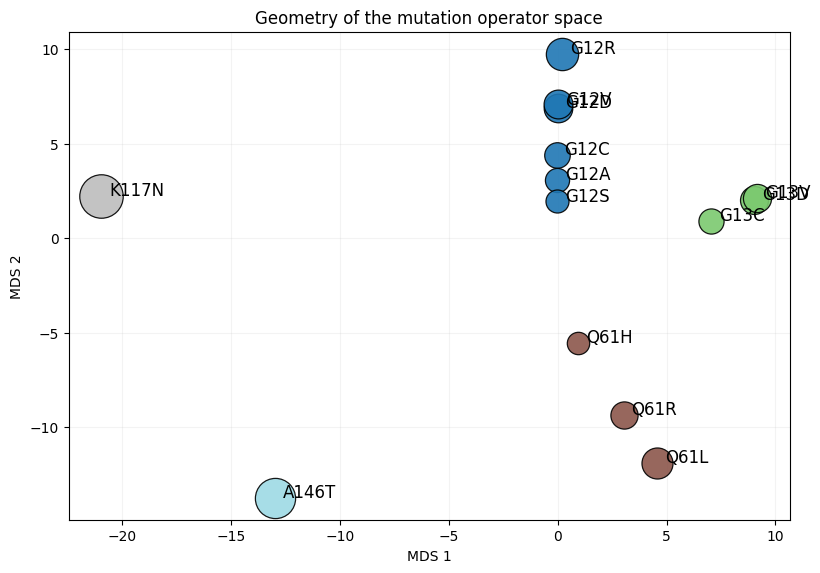

Saved figure to: kras_operator_space_v5_outputs/experiment_10_geometry_only_mds.png


In [60]:
# ---------------------------------------------------------------------
# Experiment 10H: Geometry-only MDS visualization
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
import numpy as np

# Recover the Hilbert--Schmidt operator-distance matrix from previous cells.
# The MDS embedding must use distances, not squared distances.
if "D_hs" in globals():
    DIST_HS = np.asarray(D_hs, dtype=float)
elif "D_sq" in globals():
    DIST_HS = np.sqrt(np.maximum(np.asarray(D_sq, dtype=float), 0.0))
elif "D_matrix" in globals():
    # Backward compatibility: older versions used D_matrix ambiguously.
    # If it looks squared, this conversion still gives the intended HS scale.
    D_tmp = np.asarray(D_matrix, dtype=float)
    DIST_HS = np.sqrt(np.maximum(D_tmp, 0.0))
elif "distance_matrix" in globals():
    DIST_HS = np.asarray(distance_matrix, dtype=float)
elif "distance_df" in globals():
    DIST_HS = np.asarray(distance_df.values, dtype=float)
else:
    raise RuntimeError(
        "Operator distance matrix not found. Execute the previous "
        "operator-space geometry cells first."
    )

coords = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42,
    normalized_stress="auto",
).fit_transform(DIST_HS)

site_colors = {}
for m in mutation_names:
    if m.startswith("G12"):
        site_colors[m] = "#1f77b4"
    elif m.startswith("G13"):
        site_colors[m] = "#7bc96f"
    elif m.startswith("Q61"):
        site_colors[m] = "#8c564b"
    elif m.startswith("K117"):
        site_colors[m] = "#bdbdbd"
    else:
        site_colors[m] = "#9edae5"

sizes = 260 + 720 * (V_vec - V_vec.min()) / (V_vec.max() - V_vec.min() + 1e-12)

plt.figure(figsize=(8.2, 6.1))
ax = plt.gca()

for i, m in enumerate(mutation_names):
    ax.scatter(
        coords[i, 0],
        coords[i, 1],
        s=sizes[i],
        color=site_colors[m],
        edgecolor="black",
        linewidth=0.9,
        alpha=0.9,
        zorder=2,
    )

# Slightly larger labels. A fixed offset is intentionally used to keep the
# visualization deterministic and reproducible without external label-adjustment
# dependencies.
x_span = coords[:, 0].max() - coords[:, 0].min()
y_span = coords[:, 1].max() - coords[:, 1].min()
dx = 0.012 * x_span
dy = 0.012 * y_span

for i, m in enumerate(mutation_names):
    ax.text(
        coords[i, 0] + dx,
        coords[i, 1] + dy,
        m,
        fontsize=12,
        ha="left",
        va="center",
        zorder=3,
    )

ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")
ax.set_title("Geometry of the mutation operator space")

# No legend is shown here to keep the paper figure uncluttered. Colors encode
# mutation site and marker size is proportional to V_i; both are described in
# the figure caption.
ax.grid(alpha=0.15)
plt.subplots_adjust(left=0.10, right=0.98, bottom=0.11, top=0.91)

out_path = OUTPUT_DIR / "experiment_10_geometry_only_mds.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {out_path}")


### Experiment 10I: Distribution of Hilbert--Schmidt distances

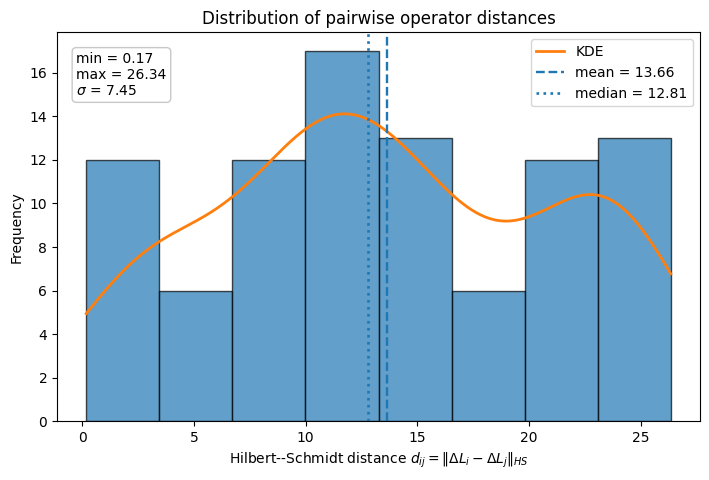

Saved figure to: kras_operator_space_v5_outputs/experiment_10_operator_distance_histogram.png
min=0.175
max=26.341
mean=13.656
median=12.806
std=7.449


In [61]:
# ---------------------------------------------------------------------
# Experiment 10I: Distribution of Hilbert--Schmidt distances
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# Recover the Hilbert--Schmidt operator-distance matrix from previous cells.
if "D_hs" in globals():
    DIST_HS = np.asarray(D_hs, dtype=float)
elif "D_sq" in globals():
    DIST_HS = np.sqrt(np.maximum(np.asarray(D_sq, dtype=float), 0.0))
elif "D_matrix" in globals():
    D_tmp = np.asarray(D_matrix, dtype=float)
    DIST_HS = np.sqrt(np.maximum(D_tmp, 0.0))
elif "distance_matrix" in globals():
    DIST_HS = np.asarray(distance_matrix, dtype=float)
elif "distance_df" in globals():
    DIST_HS = np.asarray(distance_df.values, dtype=float)
else:
    raise RuntimeError(
        "Operator distance matrix not found. Execute the previous "
        "operator-space geometry cells first."
    )

vals = DIST_HS[np.triu_indices_from(DIST_HS, k=1)]

mean_val = float(vals.mean())
median_val = float(np.median(vals))
std_val = float(vals.std())
min_val = float(vals.min())
max_val = float(vals.max())

fig, ax = plt.subplots(figsize=(7.2, 4.9))

counts, bins, _ = ax.hist(
    vals,
    bins="auto",
    edgecolor="black",
    alpha=0.70,
    density=False,
)

# Kernel density estimate, rescaled to histogram counts.
x_grid = np.linspace(min_val, max_val, 400)
kde = gaussian_kde(vals)
bin_width = np.mean(np.diff(bins))
kde_counts = kde(x_grid) * len(vals) * bin_width
ax.plot(x_grid, kde_counts, linewidth=2.0, label="KDE")

ax.axvline(mean_val, linestyle="--", linewidth=1.7, label=f"mean = {mean_val:.2f}")
ax.axvline(median_val, linestyle=":", linewidth=1.9, label=f"median = {median_val:.2f}")

stats_text = (
    f"min = {min_val:.2f}\n"
    f"max = {max_val:.2f}\n"
    f"$\\sigma$ = {std_val:.2f}"
)
ax.text(
    0.03,
    0.95,
    stats_text,
    transform=ax.transAxes,
    va="top",
    ha="left",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.75"),
)

ax.set_xlabel(r"Hilbert--Schmidt distance $d_{ij}=\|\Delta L_i-\Delta L_j\|_{HS}$")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of pairwise operator distances")
ax.legend(loc="upper right")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_operator_distance_histogram.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {out_path}")
print(f"min={min_val:.3f}")
print(f"max={max_val:.3f}")
print(f"mean={mean_val:.3f}")
print(f"median={median_val:.3f}")
print(f"std={std_val:.3f}")


### Experiment 10J: Perturbation-energy ranking of mutation operators


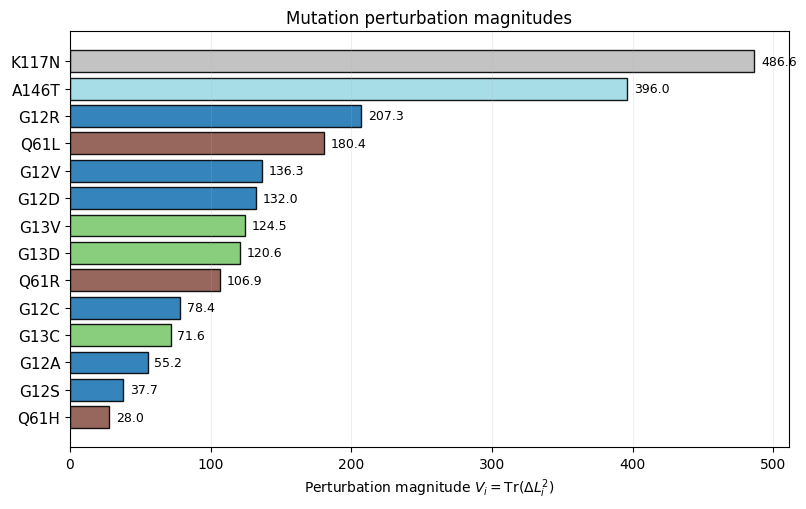

Saved figure to: kras_operator_space_v5_outputs/experiment_10_operator_energy_ranking.png


,mutation,V_i
0,K117N,486.597913
1,A146T,395.962046
2,G12R,207.269593
3,Q61L,180.367635
4,G12V,136.272940
5,G12D,132.039525
6,G13V,124.469871
7,G13D,120.603126
8,Q61R,106.895648
9,G12C,78.370481


In [62]:
# ---------------------------------------------------------------------
# Experiment 10J: Perturbation-magnitude ranking of mutation operators
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

if "mutation_names" not in globals() or "V_vec" not in globals():
    raise RuntimeError(
        "mutation_names and V_vec must exist. Execute the operator-space "
        "construction cells first."
    )

names_arr = np.asarray(mutation_names)
V_arr = np.asarray(V_vec, dtype=float)

order = np.argsort(V_arr)[::-1]
names_sorted = names_arr[order]
V_sorted = V_arr[order]

def site_color(m):
    if m.startswith("G12"):
        return "#1f77b4"
    if m.startswith("G13"):
        return "#7bc96f"
    if m.startswith("Q61"):
        return "#8c564b"
    if m.startswith("K117"):
        return "#bdbdbd"
    return "#9edae5"

colors_sorted = [site_color(m) for m in names_sorted]

fig, ax = plt.subplots(figsize=(8.2, 5.2))
y = np.arange(len(names_sorted))

ax.barh(y, V_sorted, color=colors_sorted, edgecolor="black", alpha=0.9)
ax.set_yticks(y)
ax.set_yticklabels(names_sorted, fontsize=11)
ax.invert_yaxis()

ax.set_xlabel(r"Perturbation magnitude $V_i=\operatorname{Tr}(\Delta L_i^2)$")
ax.set_title("Mutation perturbation magnitudes")

for yi, val in zip(y, V_sorted):
    ax.text(val + 0.01 * V_sorted.max(), yi, f"{val:.1f}", va="center", fontsize=9)

ax.grid(axis="x", alpha=0.2)
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_operator_energy_ranking.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

energy_ranking_df = (
    pd.DataFrame({"mutation": names_sorted, "V_i": V_sorted})
    if "pd" in globals()
    else None
)

print(f"Saved figure to: {out_path}")
if energy_ranking_df is not None:
    display(energy_ranking_df)


## Experiment 11: final manuscript figures for representative selection

The figures in this block evaluate the **selection model**, not the numerical optimizer.

They therefore compare:
- the exact geometry-induced variational subset,
- the perturbation-magnitude-only baseline, and
- random subsets where useful for context.

Simulated annealing and XY-QAOA are intentionally excluded here and are reported separately in Experiment 13 as optimization backends.


,method,k,V,D,J,selected
0,variational,5,1394.667058,5180.325154,-6574.992212,"G12R, G13V, Q61L, K117N, A146T"
1,magnitude baseline,5,1406.470127,5042.880729,-6449.350856,"G12V, G12R, Q61L, K117N, A146T"


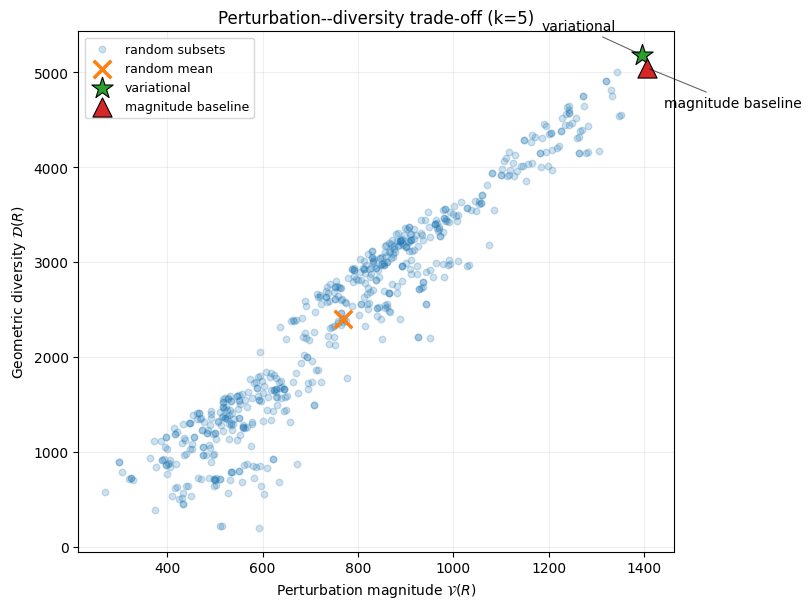

Saved: kras_operator_space_v5_outputs/experiment_11_pareto_V_D_tradeoff_final.png


In [63]:
# ---------------------------------------------------------------------
# Experiment 11A: final Pareto-style perturbation--diversity trade-off
# ---------------------------------------------------------------------

K_PARETO = K_MAIN
exact_main = exact_variational_selection(K_PARETO, V_vec, D_sq, MU)
top_main = top_energy_baseline(K_PARETO, V_vec, D_sq, MU)

pareto_rows_final = []

for method_label, result in [
    ("variational", exact_main),
    ("magnitude baseline", top_main),
]:
    pareto_rows_final.append({
        "method": method_label,
        "k": K_PARETO,
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selected": ", ".join(result["selected"]),
        "mask": result["mask"],
    })

pareto_final_df = pd.DataFrame([
    {k: v for k, v in row.items() if k != "mask"}
    for row in pareto_rows_final
])
pareto_final_df.to_csv(
    OUTPUT_DIR / "paper_final_pareto_summary.csv",
    index=False,
)
display(pareto_final_df)

rng = np.random.default_rng(RANDOM_SEED + 1100 + K_PARETO)
random_points = []
for _ in range(600):
    idx = tuple(rng.choice(N_mut, size=K_PARETO, replace=False))
    mask = mask_from_indices(idx, N_mut)
    random_points.append(variational_components(mask, V_vec, D_sq, MU))
random_df_final = pd.DataFrame(random_points)

fig, ax = plt.subplots(figsize=(8.2, 6.2))
ax.scatter(
    random_df_final["V"],
    random_df_final["D"],
    s=22,
    alpha=0.22,
    label="random subsets",
)
ax.scatter(
    [random_df_final["V"].mean()],
    [random_df_final["D"].mean()],
    marker="x",
    s=160,
    linewidths=2.5,
    label="random mean",
)

marker_map = {"variational": "*", "magnitude baseline": "^"}
size_map = {"variational": 260, "magnitude baseline": 190}
label_offsets = {
    "variational": (-72, 18),
    "magnitude baseline": (12, -28),
}

for row in pareto_rows_final:
    method = row["method"]
    ax.scatter(
        [row["V"]],
        [row["D"]],
        marker=marker_map[method],
        s=size_map[method],
        edgecolor="black",
        linewidth=0.8,
        label=method,
        zorder=5,
    )
    dx, dy = label_offsets[method]
    ax.annotate(
        method,
        xy=(row["V"], row["D"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=10,
        arrowprops=dict(arrowstyle="-", lw=0.8, alpha=0.6),
        zorder=6,
    )

ax.set_xlabel(r"Perturbation magnitude $\mathcal{V}(R)$")
ax.set_ylabel(r"Geometric diversity $\mathcal{D}(R)$")
ax.set_title(f"Perturbation--diversity trade-off (k={K_PARETO})")
ax.grid(alpha=0.2)
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_11_pareto_V_D_tradeoff_final.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


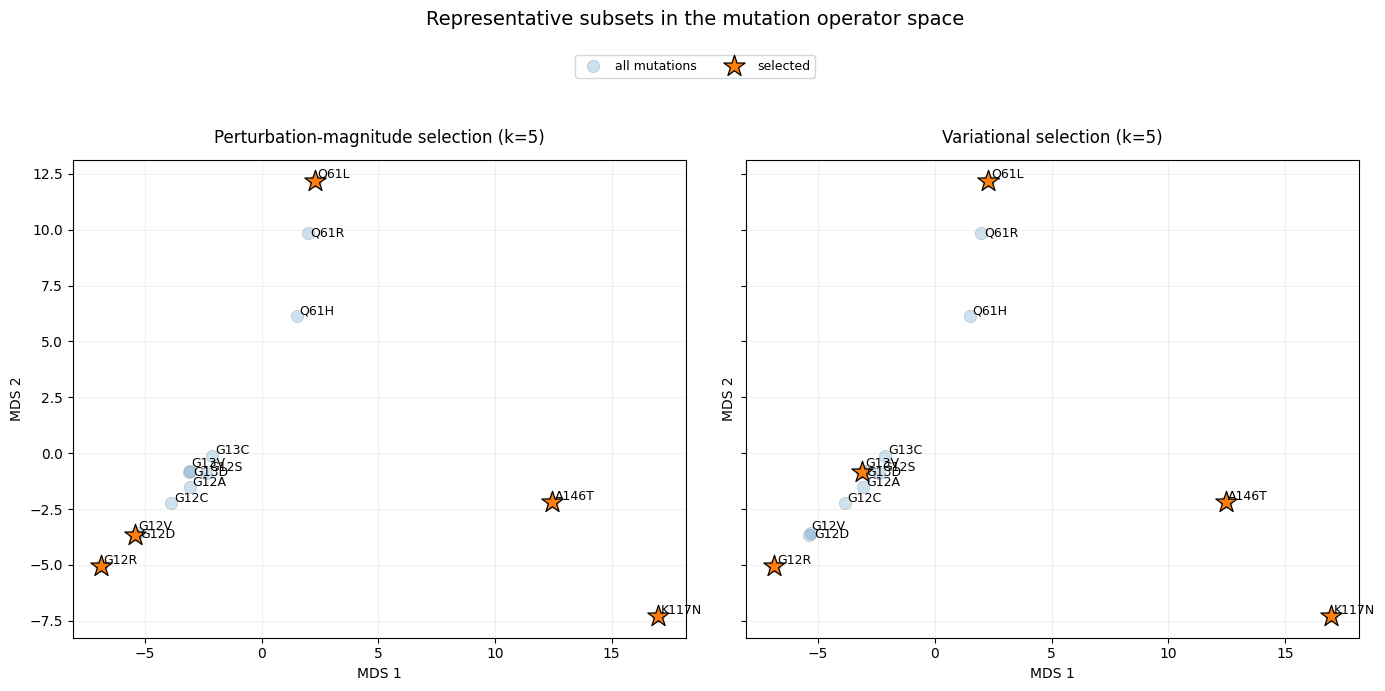

Saved: kras_operator_space_v5_outputs/experiment_11_mds_top_energy_vs_variational.png


,method,selected,V,D,J
0,magnitude baseline,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856
1,variational,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212


In [64]:
# ---------------------------------------------------------------------
# Experiment 11B: side-by-side MDS comparison of perturbation-magnitude vs variational selection
# ---------------------------------------------------------------------
# This figure shows why the diversity term matters:
# perturbation-magnitude selection tends to reuse nearby/high-magnitude regions,
# whereas the variational solution covers a broader region of the operator space.

K_SHOW = K_MAIN
exact_show = exact_variational_selection(K_SHOW, V_vec, D_sq, MU)
top_show = top_energy_baseline(K_SHOW, V_vec, D_sq, MU)

# Robust recovery of MDS coordinates.
if "mds_coords" in globals():
    COORDS = np.asarray(mds_coords)
else:
    from sklearn.manifold import MDS
    COORDS = MDS(
        n_components=2,
        dissimilarity="precomputed",
        random_state=42,
        normalized_stress="auto",
    ).fit_transform(D_hs)

def plot_selection_panel(ax, selected_mask, title):
    selected_idx = set(np.where(selected_mask == 1)[0])

    # Background: all mutations.
    ax.scatter(
        COORDS[:, 0],
        COORDS[:, 1],
        s=80,
        alpha=0.22,
        edgecolor="black",
        linewidth=0.4,
        label="all mutations",
    )

    # Selected mutations.
    ax.scatter(
        COORDS[list(selected_idx), 0],
        COORDS[list(selected_idx), 1],
        s=260,
        marker="*",
        edgecolor="black",
        linewidth=0.9,
        label="selected",
        zorder=5,
    )

    # Small manual offsets to reduce label overlap in dense regions.
    label_offsets = {
        "G12D": (0.12, -0.22),
        "G12V": (0.12, 0.22),
        "G13D": (0.12, -0.22),
        "G13V": (0.12, 0.22),
        "Q61L": (0.12, 0.18),
        "Q61R": (0.12, -0.18),
    }

    for i, name in enumerate(mutation_names):
        offset_x, offset_y = label_offsets.get(name, (0.12, 0.08))
        ax.text(
            COORDS[i, 0] + offset_x,
            COORDS[i, 1] + offset_y,
            name,
            fontsize=9,
            zorder=6,
        )

    ax.set_title(title, pad=12)
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")
    ax.grid(alpha=0.18)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)

plot_selection_panel(
    axes[0],
    top_show["mask"],
    f"Perturbation-magnitude selection (k={K_SHOW})",
)

plot_selection_panel(
    axes[1],
    exact_show["mask"],
    f"Variational selection (k={K_SHOW})",
)

# Put the legend below the title and outside the plotting area to avoid overlap.
handles, labels = axes[1].get_legend_handles_labels()
fig.suptitle("Representative subsets in the mutation operator space", y=0.98, fontsize=14)
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=2,
    frameon=True,
    fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.88])

out_path = OUTPUT_DIR / "experiment_11_mds_top_energy_vs_variational.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

comparison_rows = []
for method, result in [
    ("magnitude baseline", top_show),
    ("variational", exact_show),
]:
    comparison_rows.append({
        "method": method,
        "selected": ", ".join(result["selected"]),
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
    })
selection_comparison_df = pd.DataFrame(comparison_rows)
selection_comparison_df.to_csv(OUTPUT_DIR / "experiment_11_selection_comparison.csv", index=False)
display(selection_comparison_df)

In [65]:
# ---------------------------------------------------------------------
# Experiment 11C: compact cluster-coverage table
# ---------------------------------------------------------------------

N_CLUSTERS_FOR_TABLE = (
    len(set(cluster_labels))
    if "cluster_labels" in globals()
    else np.nan
)

coverage_masks = {
    "variational": exact_show["mask"],
    "top-energy": top_show["mask"],
}

coverage_table_rows = []
for method, mask in coverage_masks.items():
    selected_idx = np.where(mask == 1)[0]

    if "cluster_labels" in globals():
        covered = sorted(set(cluster_labels[selected_idx]))
        n_covered = len(covered)
        ratio = n_covered / max(1, len(set(cluster_labels)))
        covered_str = ", ".join(map(str, covered))
    else:
        n_covered = np.nan
        ratio = np.nan
        covered_str = ""

    coverage_table_rows.append({
        "method": method,
        "selected": ", ".join(names_from_mask(mask)),
        "covered_clusters": covered_str,
        "coverage": (
            f"{n_covered}/{N_CLUSTERS_FOR_TABLE}"
            if not pd.isna(n_covered)
            else ""
        ),
        "coverage_ratio": ratio,
    })

coverage_table_final_df = pd.DataFrame(coverage_table_rows)
coverage_table_final_df.to_csv(
    OUTPUT_DIR / "paper_cluster_coverage_table.csv",
    index=False,
)
display(coverage_table_final_df)


,method,selected,covered_clusters,coverage,coverage_ratio
0,variational,"G12R, G13V, Q61L, K117N, A146T","1, 2, 3, 4, 5",5/5,1.0
1,top-energy,"G12V, G12R, Q61L, K117N, A146T","1, 3, 4, 5",4/5,0.8


,mu,selected,V,D,J,selection_changed
0,0.00,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1406.470127,True
1,0.05,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1658.614164,False
2,0.10,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-1912.699573,True
3,0.25,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-2689.748346,False
4,0.50,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-3984.829635,False
5,1.00,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,False
6,2.00,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-11755.317366,False
7,5.00,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-27296.292828,False


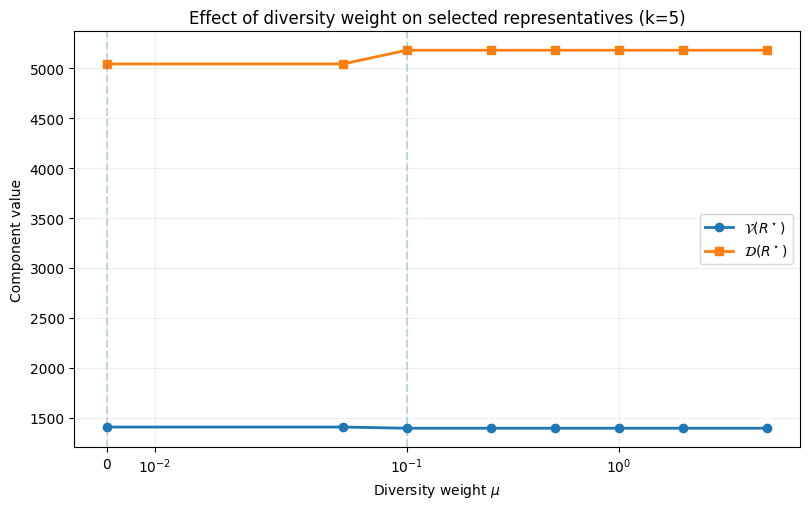

Saved: kras_operator_space_v5_outputs/experiment_11_mu_evolution_components_final.png


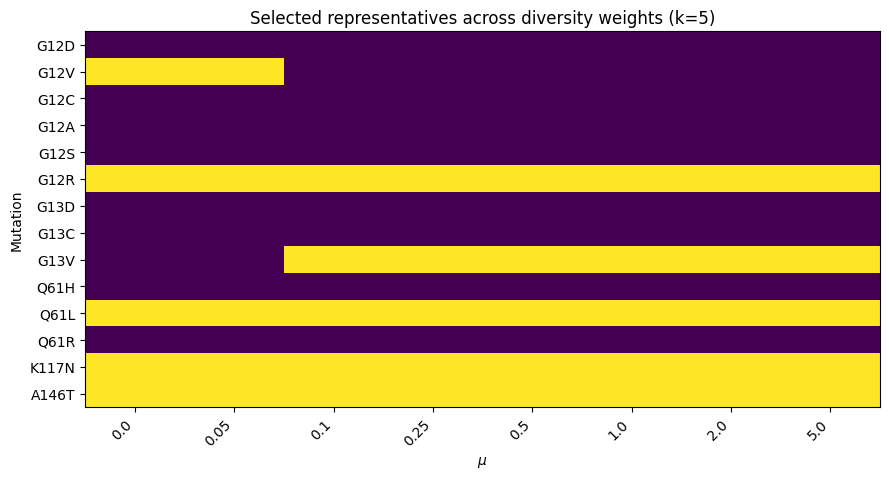

Saved: kras_operator_space_v5_outputs/experiment_11_mu_selection_matrix_final.png


In [66]:

# ---------------------------------------------------------------------
# Experiment 11D: final mu sensitivity figures with cleaner labels
# ---------------------------------------------------------------------
MU_GRID_FINAL = np.array([0.0, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0], dtype=float)
K_MU = K_MAIN

mu_rows_final = []
prev_selection = None

for mu_value in MU_GRID_FINAL:
    result = exact_variational_selection(K_MU, V_vec, D_sq, mu_value)
    selection_tuple = tuple(result["selected"])
    changed = selection_tuple != prev_selection
    prev_selection = selection_tuple

    mu_rows_final.append({
        "mu": mu_value,
        "selected": ", ".join(result["selected"]),
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selection_changed": changed,
    })

mu_sensitivity_final_df = pd.DataFrame(mu_rows_final)
mu_sensitivity_final_df.to_csv(OUTPUT_DIR / "experiment_11_mu_sensitivity_final.csv", index=False)
display(mu_sensitivity_final_df)

fig, ax = plt.subplots(figsize=(8.2, 5.2))
ax.plot(
    mu_sensitivity_final_df["mu"],
    mu_sensitivity_final_df["V"],
    marker="o",
    linewidth=2,
    label=r"$\mathcal{V}(R^\star)$",
)
ax.plot(
    mu_sensitivity_final_df["mu"],
    mu_sensitivity_final_df["D"],
    marker="s",
    linewidth=2,
    label=r"$\mathcal{D}(R^\star)$",
)
ax.set_xscale("symlog", linthresh=0.05)
ax.set_xlabel(r"Diversity weight $\mu$")
ax.set_ylabel("Component value")
ax.set_title(f"Effect of diversity weight on selected representatives (k={K_MU})")

for _, row in mu_sensitivity_final_df.iterrows():
    if row["selection_changed"]:
        ax.axvline(row["mu"], linestyle="--", alpha=0.25)

ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_11_mu_evolution_components_final.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

# Selection matrix.
selection_matrix_mu_final = pd.DataFrame(0, index=mutation_names, columns=[str(mu) for mu in MU_GRID_FINAL])
for _, row in mu_sensitivity_final_df.iterrows():
    selected_names = [s.strip() for s in row["selected"].split(",") if s.strip()]
    for name in selected_names:
        selection_matrix_mu_final.loc[name, str(row["mu"])] = 1

fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * N_mut)))
ax.imshow(selection_matrix_mu_final.values, aspect="auto")
ax.set_yticks(np.arange(N_mut))
ax.set_yticklabels(mutation_names)
ax.set_xticks(np.arange(len(MU_GRID_FINAL)))
ax.set_xticklabels([str(mu) for mu in MU_GRID_FINAL], rotation=45, ha="right")
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Mutation")
ax.set_title(f"Selected representatives across diversity weights (k={K_MU})")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_11_mu_selection_matrix_final.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


## Experiment 13. Optimization backends for the induced Hamiltonian

This final block is intentionally separate from the representative-selection analysis.

Exact enumeration provides the reference optimum. Fixed-cardinality simulated annealing tests whether a mature classical heuristic can recover that optimum. XY-QAOA tests gate-based compatibility and the behavior of a cardinality-preserving variational quantum ansatz as circuit depth increases.

No biological or geometric claim is inferred from the particular most-probable bit string produced by a finite-depth QAOA state. The model-defined representative subset is the exact variational optimum reported in the preceding experiments.


,solver,energy,gap,success_rate,selected
0,Exact enumeration,-6574.992212,0.0,1.0,"G12R, G13V, Q61L, K117N, A146T"
1,Fixed-k simulated annealing,-6574.992212,0.0,1.0,"G12R, G13V, Q61L, K117N, A146T"


,p,expectation,expectation_gap,relative_expectation_gap,optimal_probability,shots_to_95_success
1,1,-4072.935865,2502.056347,0.380541,0.006689,447.0
2,2,-4490.247179,2084.745033,0.317072,0.008260,362.0
3,3,-4561.885702,2013.106509,0.306176,0.010464,285.0
4,4,-4876.822212,1698.170000,0.258277,0.008764,341.0
5,5,-5099.143966,1475.848246,0.224464,0.002868,1043.0


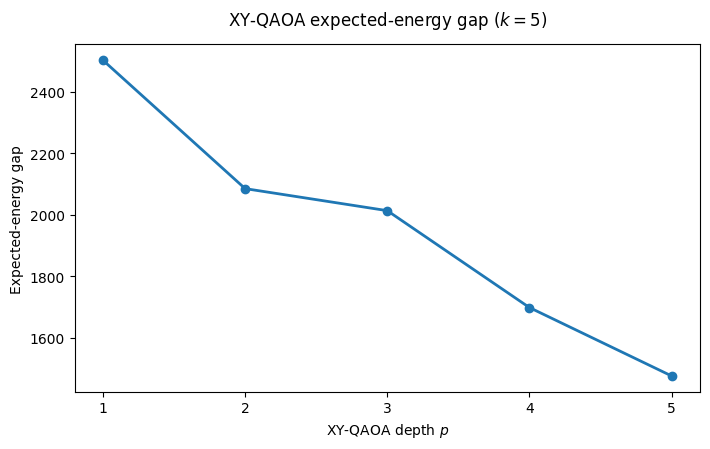

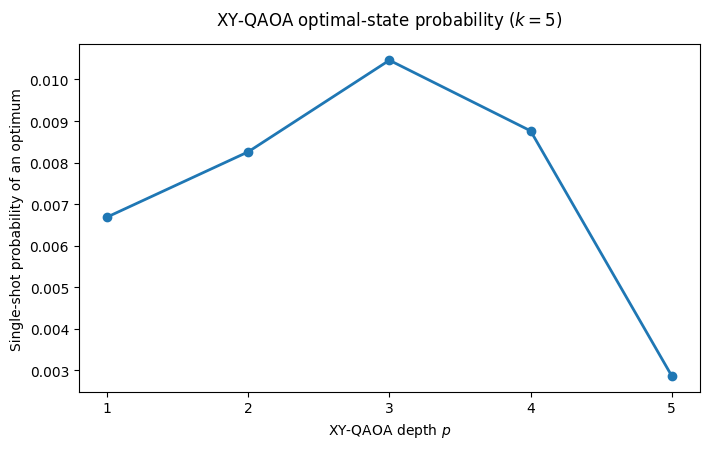

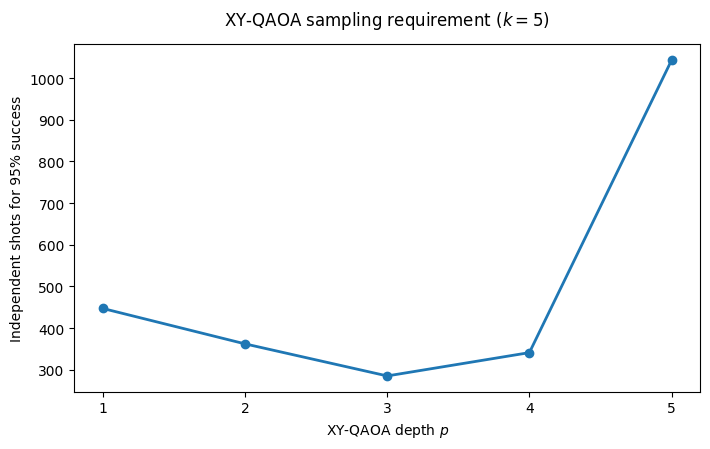

Paper-ready backend outputs saved.


In [67]:
# ---------------------------------------------------------------------
# Experiment 13: paper-ready optimization-backend diagnostics
# ---------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if "experiment_4_df" in globals():
    exp4 = experiment_4_df.copy()
else:
    csv_path = OUTPUT_DIR / "experiment_4_optimization_backend_diagnostics.csv"
    if not csv_path.exists():
        raise RuntimeError(
            "Experiment 4 results not found. Execute Experiment 4 first."
        )
    exp4 = pd.read_csv(csv_path)

K_MAIN_PLOT = K_QOPT

# Exact reference and fixed-k simulated annealing.
exact_row = exp4[exp4["method"] == "exact_enumeration"].iloc[0]
sa_row = exp4[
    exp4["method"] == "simulated_annealing_fixed_k"
].iloc[0]

classical_backend_table = pd.DataFrame([
    {
        "solver": "Exact enumeration",
        "energy": exact_row["energy"],
        "gap": 0.0,
        "success_rate": 1.0,
        "selected": exact_row["selected"],
    },
    {
        "solver": "Fixed-k simulated annealing",
        "energy": sa_row["energy"],
        "gap": sa_row["mode_gap"],
        "success_rate": sa_row["success_rate"],
        "selected": sa_row["selected"],
    },
])
classical_backend_table.to_csv(
    OUTPUT_DIR / "paper_classical_backend_table.csv",
    index=False,
)
display(classical_backend_table)

# XY-QAOA is reported only through optimization-quality diagnostics.
qaoa = exp4[
    exp4["method"] == "qaoa_xy_fixed_cardinality"
].copy()
qaoa["p"] = qaoa["p"].astype(int)
qaoa = qaoa.sort_values("p")

qaoa_table = qaoa[
    [
        "p",
        "expectation",
        "expectation_gap",
        "relative_expectation_gap",
        "optimal_probability",
        "shots_to_95_success",
    ]
].copy()

qaoa_table.to_csv(
    OUTPUT_DIR / "paper_xy_qaoa_backend_table.csv",
    index=False,
)
display(qaoa_table)

# Figure 1: expected-energy gap.
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(
    qaoa["p"],
    qaoa["expectation_gap"],
    marker="o",
    linewidth=2.0,
)
ax.set_xlabel("XY-QAOA depth $p$")
ax.set_ylabel("Expected-energy gap")
ax.set_title(f"XY-QAOA expected-energy gap ($k={K_MAIN_PLOT}$)", pad=14)
ax.set_xticks(qaoa["p"].tolist())
plt.tight_layout()
qaoa_gap_path = OUTPUT_DIR / "paper_xy_qaoa_expected_gap_final.png"
plt.savefig(qaoa_gap_path, dpi=300, bbox_inches="tight")
plt.show()

# Figure 2: optimal-state probability.
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(
    qaoa["p"],
    qaoa["optimal_probability"],
    marker="o",
    linewidth=2.0,
)
ax.set_xlabel("XY-QAOA depth $p$")
ax.set_ylabel("Single-shot probability of an optimum")
ax.set_title(
    f"XY-QAOA optimal-state probability ($k={K_MAIN_PLOT}$)",
    pad=14,
)
ax.set_xticks(qaoa["p"].tolist())
plt.tight_layout()
qaoa_prob_path = OUTPUT_DIR / "paper_xy_qaoa_optimal_probability_final.png"
plt.savefig(qaoa_prob_path, dpi=300, bbox_inches="tight")
plt.show()

# Figure 3: shots for 95% success.
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(
    qaoa["p"],
    qaoa["shots_to_95_success"],
    marker="o",
    linewidth=2.0,
)
ax.set_xlabel("XY-QAOA depth $p$")
ax.set_ylabel("Independent shots for 95% success")
ax.set_title(
    f"XY-QAOA sampling requirement ($k={K_MAIN_PLOT}$)",
    pad=14,
)
ax.set_xticks(qaoa["p"].tolist())
plt.tight_layout()
qaoa_shots_path = OUTPUT_DIR / "paper_xy_qaoa_shots_to_95_final.png"
plt.savefig(qaoa_shots_path, dpi=300, bbox_inches="tight")
plt.show()

print("Paper-ready backend outputs saved.")


## Final v5 manuscript-readiness audit

The following cell performs automatic consistency checks on the results that will be used in the revised manuscript. A failed check does not modify the numerical results; it flags an item that should be inspected before drafting the corresponding subsection.

The checks deliberately distinguish exact mathematical identities from empirical robustness:
- QUBO/Ising equivalence and distance reconstruction are exact-consistency checks.
- RIN sensitivity, \(\mu\) stability, clustering, and solver behavior are empirical results and are summarized without imposing artificial pass/fail claims beyond basic sanity conditions.


In [68]:
# ---------------------------------------------------------------------
# Final automated manuscript-readiness audit and output manifest
# ---------------------------------------------------------------------

audit_rows = []

def add_audit(name, passed, value, note):
    audit_rows.append({
        "check": name,
        "status": "PASS" if bool(passed) else "REVIEW",
        "value": value,
        "note": note,
    })

# 1) Exact variational/QUBO/Ising equivalence for k=4,5,6.
if "experiment_3_df" in globals():
    eq_subset = bool(
        experiment_3_df["same_variational_qubo_subset"].all()
        and experiment_3_df["same_variational_ising_subset"].all()
    )
    max_mismatch = float(
        experiment_3_df["max_abs_qubo_ising_energy_mismatch"].max()
    )
    add_audit(
        "Variational/QUBO/Ising minimizers",
        eq_subset,
        f"max energy mismatch={max_mismatch:.3e}",
        "The exact reformulations should recover the same minimizers.",
    )

# 2) Exact reconstruction of the operator squared-distance matrix.
if "D_sq_from_J" in globals():
    reconstruction_error = float(np.max(np.abs(D_sq_from_J - D_sq)))
    add_audit(
        "Geometry reconstruction from Ising couplings",
        reconstruction_error < 1e-8,
        f"{reconstruction_error:.3e}",
        "Numerical check of the analytic affine identity.",
    )

# 3) Cluster count selected from data.
if "cluster_count_diagnostics_df" in globals() and len(cluster_count_diagnostics_df) > 0:
    best_cluster_row = cluster_count_diagnostics_df.loc[
        cluster_count_diagnostics_df["silhouette"].idxmax()
    ]
    add_audit(
        "Data-driven cluster count available",
        np.isfinite(best_cluster_row["silhouette"]),
        f"k_clusters={int(best_cluster_row['actual_clusters'])}, silhouette={best_cluster_row['silhouette']:.3f}",
        "Cluster count is selected by silhouette rather than prescribed.",
    )

# 4) RIN-sensitivity summary.
if "rin_sensitivity_geometry_df" in globals():
    nonbaseline = rin_sensitivity_geometry_df[
        rin_sensitivity_geometry_df["configuration"] != RIN_SENSITIVITY_BASELINE
    ]
    min_spearman = float(nonbaseline["spearman_d_vs_baseline"].min())
    min_pearson = float(nonbaseline["pearson_d_vs_baseline"].min())
    add_audit(
        "RIN geometry sensitivity computed",
        np.isfinite(min_spearman) and np.isfinite(min_pearson),
        f"min Pearson={min_pearson:.3f}, min Spearman={min_spearman:.3f}",
        "Empirical robustness result; do not describe it as exact invariance.",
    )

# 5) Main selection comparison.
if "experiment_5_df" in globals():
    var_row = experiment_5_df[
        experiment_5_df["method"] == "variational_exact"
    ].iloc[0]
    top_row = experiment_5_df[
        experiment_5_df["method"] == "top_perturbation_energy"
    ].iloc[0]
    add_audit(
        "Main selection comparison",
        True,
        (
            f"V: {var_row['V']:.3f} vs {top_row['V']:.3f}; "
            f"D: {var_row['D']:.3f} vs {top_row['D']:.3f}"
        ),
        "Use these exact values for the Section 4.3 comparison.",
    )

# 6) Mu stability.
if "mu_sensitivity_final_df" in globals():
    main_mu_row = mu_sensitivity_final_df[
        np.isclose(mu_sensitivity_final_df["mu"], MU)
    ]
    n_unique_after_point_one = (
        mu_sensitivity_final_df[
            mu_sensitivity_final_df["mu"] >= 0.1
        ]["selected"].nunique()
    )
    add_audit(
        "Mu sensitivity",
        len(main_mu_row) == 1,
        f"unique subsets for mu>=0.1: {n_unique_after_point_one}",
        "Use the sweep to justify the nominal mu without claiming it is uniquely optimal.",
    )

# 7) Fixed-k simulated annealing.
if "sa_result" in globals():
    add_audit(
        "Fixed-k simulated annealing",
        np.isclose(sa_result["energy"], exact_energy, atol=1e-9),
        f"success rate={100*sa_result['success_rate']:.1f}%",
        "Classical heuristic backend; report restart success rate.",
    )

# 8) XY-QAOA feasibility and expected-energy behavior.
if "qaoa_results" in globals():
    qaoa_audit = experiment_4_df[
        experiment_4_df["method"] == "qaoa_xy_fixed_cardinality"
    ].sort_values("p")
    exp_gaps = qaoa_audit["expectation_gap"].to_numpy(dtype=float)
    monotone_expectation = bool(
        np.all(np.diff(exp_gaps) <= 1e-8)
    )
    add_audit(
        "XY-QAOA expected-energy trend",
        monotone_expectation,
        " -> ".join(f"{v:.1f}" for v in exp_gaps),
        (
            "Warm-start construction allows deeper circuits to reproduce shallower states. "
            "Do not require optimal-state probability to be monotonic."
        ),
    )

# 9) Fixed-cardinality XY mixer connectivity.
if "xy_connected" in globals():
    add_audit(
        "XY mixer connectivity",
        bool(xy_connected),
        f"{xy_reachable}/{len(feasible_masks)} feasible states reachable",
        "Checks ergodic connectivity of the chosen ring mixer on the finite feasible basis.",
    )

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(
    OUTPUT_DIR / "paper_v5_readiness_audit.csv",
    index=False,
)
display(audit_df)

# Compact manuscript result manifest.
manifest_rows = [
    {
        "manuscript_use": "Selection trade-off",
        "file": "paper_final_pareto_tradeoff.png",
    },
    {
        "manuscript_use": "Perturbation-magnitude vs variational MDS",
        "file": "experiment_11_mds_top_energy_vs_variational.png",
    },
    {
        "manuscript_use": "Cluster coverage",
        "file": "paper_cluster_coverage_table.csv",
    },
    {
        "manuscript_use": "Mu sensitivity",
        "file": "experiment_11_mu_sensitivity_final.csv",
    },
    {
        "manuscript_use": "RIN sensitivity",
        "file": "reviewer_RIN_sensitivity_geometry.csv",
    },
    {
        "manuscript_use": "Exact QUBO/Ising validation",
        "file": "experiment_3_exact_qubo_ising_validation.csv",
    },
    {
        "manuscript_use": "Geometry reconstruction",
        "file": "experiment_6_geometry_hamiltonian_correlations.csv",
    },
    {
        "manuscript_use": "Classical optimization backend",
        "file": "paper_classical_backend_table.csv",
    },
    {
        "manuscript_use": "XY-QAOA depth metrics",
        "file": "paper_xy_qaoa_backend_table.csv",
    },
]

manifest_df = pd.DataFrame(manifest_rows)
manifest_df.to_csv(
    OUTPUT_DIR / "paper_v5_output_manifest.csv",
    index=False,
)
display(manifest_df)

print("\nFinal v5 output directory:", OUTPUT_DIR.resolve())
print("Review any rows marked REVIEW before drafting the manuscript.")


,check,status,value,note
0,Variational/QUBO/Ising minimizers,PASS,max energy mismatch=1.863e-09,The exact reformulations should recover the sa...
1,Geometry reconstruction from Ising couplings,PASS,3.624e-12,Numerical check of the analytic affine identity.
2,Data-driven cluster count available,PASS,"k_clusters=5, silhouette=0.583",Cluster count is selected by silhouette rather...
3,RIN geometry sensitivity computed,PASS,"min Pearson=0.969, min Spearman=0.980",Empirical robustness result; do not describe i...
4,Main selection comparison,PASS,V: 1394.667 vs 1406.470; D: 5180.325 vs 5042.881,Use these exact values for the Section 4.3 com...
5,Mu sensitivity,PASS,unique subsets for mu>=0.1: 1,Use the sweep to justify the nominal mu withou...
6,Fixed-k simulated annealing,PASS,success rate=100.0%,Classical heuristic backend; report restart su...
7,XY-QAOA expected-energy trend,PASS,2502.1 -> 2084.7 -> 2013.1 -> 1698.2 -> 1475.8,Warm-start construction allows deeper circuits...
8,XY mixer connectivity,PASS,2002/2002 feasible states reachable,Checks ergodic connectivity of the chosen ring...


,manuscript_use,file
0,Selection trade-off,paper_final_pareto_tradeoff.png
1,Perturbation-magnitude vs variational MDS,experiment_11_mds_top_energy_vs_variational.png
2,Cluster coverage,paper_cluster_coverage_table.csv
3,Mu sensitivity,experiment_11_mu_sensitivity_final.csv
4,RIN sensitivity,reviewer_RIN_sensitivity_geometry.csv
5,Exact QUBO/Ising validation,experiment_3_exact_qubo_ising_validation.csv
6,Geometry reconstruction,experiment_6_geometry_hamiltonian_correlations...
7,Classical optimization backend,paper_classical_backend_table.csv
8,XY-QAOA depth metrics,paper_xy_qaoa_backend_table.csv



Final v5 output directory: /content/kras_operator_space_v5_outputs
Review any rows marked REVIEW before drafting the manuscript.
